# Step 4: Diagnostics: who does the model fail for, and why?

## What this notebook is for
Steps 3a and 3b trained two rankers that reorder each search results list so that clicked, carted and purchased products rise to the top. They report **one average number per model** (NDCG@10 on the test set). An average hides a lot: a model can be excellent for users with long histories and useless for products nobody has bought before, and still post a good average.

This notebook takes the saved **test-set predictions** of every model and asks:
1. **Are the differences between models real**, or within the noise of 12,880 test searches?
2. **For which users, products and searches does the final model do well or badly?**
3. **When it fails, why?** What kind of product does it miss, and what does it rank above it?
4. **What has each model learned?** (LambdaRank through SHAP values, the attention model through its attention weights.)
5. **Can we trust the headline numbers?** In particular, does the popularity signal, the largest single input, use information from after the search?
6. **What does this mean for the business?** (Repeat purchases, new products, small shops.)

## Sections
The **key findings** of the whole notebook are listed in the next cell, each with the section where it is shown.

| Section | Question | Main output |
|---|---|---|
| 0 | Are the inputs complete, and do we reproduce the reported numbers? | file check, integrity table |
| 1 | Which model is best, and are the gaps real? | results table with confidence intervals |
| 2 | Which users, products and searches does each model handle well or badly? | NDCG by segment charts |
| 3 | When the final model misses, what went wrong? | failure types |
| 4 | What has each model learned? | SHAP (LambdaRank), attention weights (attention model) |
| 5 | Can we trust the numbers? | popularity timing check, 1-second searches, other seeds |
| 6 | What does it mean for the business? | repeat purchases, new products, small shops |

## Models compared
| Name in this notebook | What it is | Source |
|---|---|---|
| random | random order (the floor) | computed here |
| BM25 | text match between query and product name | step 3a predictions |
| popularity | rank by how many training users touched the product (`pop_product_users`) | popularity features (step 3b) |
| LambdaRank (no popularity) | step 3a's model with the 13 popularity features removed | step 3a predictions |
| **LambdaRank (final)** | step 3a's final model: 36 features + 13 popularity, seed 42 | step 3a predictions |
| attention (no history) | step 3b's model with the history-reading branch removed | step 3b test scores |
| attention (full) | step 3b's attention model, seed 42 | step 3b test scores |
| LSTM-NCF | the past project's model, retrained by step 2 on the team's split | step 2 predictions |

## Words used in this notebook
- **Search**: one user's final search; the test set has 12,880 of them, one per test user.
- **Search results list** (or **list**): the up-to-200 products JD showed for that search. The models reorder this list.
- **Engaged**: the user clicked, carted or bought the product (label 1, 2 or 3). **Shown but ignored**: label 0.
- **Past action**: one entry in the user's history (click, cart, follow or order) before the search.
- **Repeat product**: a product in the list that the user acted on before.
- **Cold product**: a product that no training user ever acted on (in their history or in their own search results list), so a model has no training data on that exact product.
- **NDCG@10**: how close the model's top 10 is to the best possible top 10. Purchases count 7, carts 3, clicks 1 (gain 2^label − 1). 1 = perfect, random order ≈ 0.08.


## Key findings
Each finding gives the number behind it and **where it is shown** (→ section, figure in `step4_diagnostics/figures/`). All numbers are on the 12,880 test searches; intervals are 95% bootstrap intervals over searches, paired where two models are compared.

**Overall results**
1. **LambdaRank (final) is the best model, but popularity does most of the work.** NDCG@10 **0.406** [0.399, 0.412], **+0.077** [+0.072, +0.081] over sorting by popularity alone. Popularity alone achieves 76% of LambdaRank's gain over random order, and LambdaRank without popularity (0.274) falls below it. → **1.1**, `1_overall_results.png`
2. **LambdaRank and the attention model are practically equal.** +0.007 [+0.005, +0.010] NDCG@10, ahead for every training seed, but no difference in purchases on the first page (+5 per 1,000 purchase searches [−9, +18]). The attention model's history stream adds about 0.001. → **1.1**, **4.4**, **5.3**, **6.1**
3. **The past project's LSTM-NCF, retrained by step 2, is beaten clearly.** NDCG@10 0.352 [0.346, 0.358]: +0.023 over popularity, but LambdaRank is +0.054 [+0.050, +0.058] above it, and it puts the purchased product in the top 10 no more often than popularity (55.3% vs 57.0%). LambdaRank puts 85 more purchases on the first page per 1,000 purchase searches [+64, +107]. → **1.3**
4. **The average hides many losses.** LambdaRank is worse than popularity in 23.9% of searches, and 22.4% of searches are missed by both (no engaged product in either top 10). → **1.1**, **3.2**, `1_better_same_worse.png`

**Who the model works for**

5. **What the wanted product is matters far more than who the user is.** NDCG@10 is 0.763 with a repeat product against 0.344 without, and 0.184 when every engaged product is cold against 0.703 when it has 100+ training users. User segments move it only between 0.38 and 0.43. → **2.2**, `2_ndcg_by_product_segment.png`
6. **The gain over popularity is mostly a repeat-product detector.** +0.398 with a repeat product, +0.021 without: the 15% of searches with a repeat product supply 77% of the gain. → **2.3**, `2_gain_by_segment.png`
7. **Popularity hurts cold products.** In the 25% of searches where every engaged product is cold, popularity alone scores 0.068, below random order (0.107), and adding popularity to LambdaRank costs −0.032 [−0.038, −0.025]. → **2.2**, **2.3**
8. **Contrary to the interim report's prediction, the past-project model does not collapse on cold products.** On cold-product searches LSTM-NCF scores 0.193, above random (0.107) and slightly above LambdaRank (0.184); it falls behind on popular products instead (0.587 vs popularity's 0.680 at 100+ users). → **2.4**, `2_lstm_ncf_by_segment.png`

**Why it fails**

9. **29.8% of searches have no engaged product in the top 10, and 87% of these failures are about popularity:** the engaged product is cold (53%) or outranked by more popular products (34%). User properties barely matter (over-representation 0.95–1.1×). → **3.3**, `3_failure_types.png`
10. **Failures are near misses among substitutes.** In 73% of failed searches at least half the top 10 is in the right leaf category, but 71% of the top 10 is more popular than the product the user wanted. → **3.4**
11. **About one product in ten is tied with a neighbour**, almost always a variant of the same product (90.7% of tie groups share shop, brand and category), so a deployed ranker needs a tie rule. → **0.5**, **3.5**

**Inside the models**

12. **Popularity drives 55% of what reorders a list, and the model reads "no data" as "unpopular".** A cold product gets −0.31 from `pop_product_users`, and wanted cold products end at their list's average (push −0.03) against +4.20 for repeat products. → **4.2**, **4.3**, `4_shap_importance.png`, `4_shap_push_engaged.png`
13. **The attention weights are sensible but largely redundant.** They favour matching past actions at about 1.4× their share, but 56–65% of that is predictable from the dense features, and the "nothing relevant" slot only tracks history length (71% of the weight for 1–9 past actions, 15% for 200+). → **4.4**, `4_attention.png`

**Can the numbers be trusted?**

14. **Yes: the headline holds.** Popularity computed strictly before the test day costs only 0.004 NDCG@10 (gain over popularity still +0.075). Without the 4.7% of searches whose last past action is 1 s before the search, the result is 0.393 and +0.065, and repeat products still supply 72% of the gain. Over three training seeds LambdaRank scores 0.4061 ± 0.0007 with the same segment pattern. → **5.1**, **5.2**, **5.3**

**What it means for the business**

15. **The model's measurable value is "find it again".** It puts **69 more purchases on the first page per 1,000 purchase searches** than popularity [+50, +88]. About 80% of that comes from products the user had already looked at or bought, which it ranks in the top 10 98–100% of the time. For products new to the user (86% of purchases) it equals popularity. → **6.1**, `6_purchases_first_page.png`
16. **New products and small shops are under-exposed.** A wanted cold product reaches the first page **19%** of the time against 66% for other wanted products; a product from a least-active shop 22% against 52%. About **335 and 77 wanted products per 1,000 searches** miss page one because of it: a popularity feedback loop against new launches and new sellers. → **6.2**, `6_first_page_reach.png`
17. **The value goes to customers in the middle of a visit** (41% of searches, 63% of the gain). Users with 1–9 past actions get no measurable purchase gain, and no customer group is worse off than with popularity. → **6.3**

**Implications.** For the model: treat zero popularity as "no data" rather than "unpopular" (2.3, 4.3), and add information that separates substitutes, such as price, attributes or product text (3.4). For evaluation: report cold-product NDCG and first-page reach by product kind next to NDCG@10 (6.2). **Limits:** offline results on searches with an engaged product, no prices (so no GMV), and no comparison with JD's own ranking (6.4).


## 0. Setup

### 0.1 Mount Drive and list the input files
**What this step does.** It connects to Google Drive, sets the folder that holds the team's outputs, and checks that every input file is there before any analysis starts.

**Why.** This notebook only reads files written by the other workstreams (steps 1a, 1b, 3a and 3b). If one is missing or was saved under another name, it is better to find out in the first cell than halfway through a long run.

**How.**
- `BASE` is the only path to edit if the team folder moves. If the notebook is not running on Colab (e.g. a local test), it falls back to a local folder `drive_data/` with the same subfolders.
- Inputs are grouped as in the plan: **predictions** (what we diagnose), **segment features** (what we slice by), **interpretation** (model file and attention weights), and **training-side data** (for the cold-product definition and the popularity timing check).
- Every input is required, including step 2's baseline predictions (final rerun, 6 Nov) and Ning's LambdaRank seed file. If one is missing or was saved under another name, the cell stops with a clear message.
- `SEED = 42` is used for every random choice here (tie-breaking, bootstrap, samples), so reruns give the same numbers.

**How to read the output.** One line per file: `OK` with its size, or `MISSING`. Any missing file stops the notebook with a clear message.


In [ ]:
import gc
import os
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
pd.set_option('display.width', 200)

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/bt4222/JDsearch')
    IN_COLAB = True
except Exception as e:                      # not on Colab, or mounting failed
    print('Drive not mounted:', repr(e))
    BASE = Path('drive_data')               # local copy with the same subfolders
    IN_COLAB = False

STEP1A = BASE / 'step1a_history'
STEP1B = BASE / 'step1b_query_item' / 'full'
STEP2  = BASE / 'step2_baselines'
STEP3A = BASE / 'step3a_lambdarank'
STEP3B = BASE / 'step3b_attention'

OUT = BASE / 'step4_diagnostics'            # tables and figures from this notebook
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)

FILES = {
    # predictions: what we diagnose
    'lr_pred':      STEP3A / 'test_predictions_lambdarank.parquet',
    'lr_seeds':     STEP3A / 'predictions_lambdarank_seeds_test.parquet',   # LambdaRank seeds 42, 43, 44 (Ning)
    'att_scores':   STEP3B / 'step3b_test_scores.parquet',
    'att_sess':     STEP3B / 'step3b_session_ndcg.parquet',
    'step2_pred':   STEP2 / 'test_predictions_baselines.parquet',            # LSTM-NCF, popularity, BM25 (step 2)
    # segment features (test rows are filtered on load)
    'user_subset':  BASE / 'user_subset.parquet',
    'hist_user':    STEP1A / 'history_user_features.parquet',
    'hist_cand':    STEP1A / 'history_candidate_features.parquet',
    'hist_group':   STEP1A / 'history_group_features.parquet',
    'query_item':   STEP1B / 'query_item_test.parquet',
    'popularity':   STEP3B / 'step3b_popularity_features.parquet',
    'lookup':       STEP3B / 'product_lookup.parquet',
    # interpretation
    'lr_model':     STEP3A / 'lambdarank_final_pop.txt',
    'lr_importance':STEP3A / 'feature_importance_lambdarank.csv',
    'att_summary':  STEP3B / 'step3b_attention_summary.parquet',
    # training-side data: cold products and the popularity timing check
    'hist_long':    STEP1A / 'history_long.parquet',
}

def size_mb(p):
    return p.stat().st_size / 1e6

missing = []
print(f'BASE = {BASE}  (Colab: {IN_COLAB})\n')
for name, path in FILES.items():
    if path.exists():
        print(f'OK       {name:14s} {size_mb(path):9.1f} MB   {path.relative_to(BASE)}')
    else:
        print(f'MISSING  {name:14s} {"":>12s}   {path.relative_to(BASE)}')
        missing.append(name)

try:
    import psutil
    print(f'\nRuntime RAM: {psutil.virtual_memory().total / 1e9:.1f} GB total, '
          f'{psutil.virtual_memory().available / 1e9:.1f} GB free')
except ImportError:
    pass

assert not missing, f'Inputs missing: {missing}. Check BASE and the file names above.'


Mounted at /content/drive
BASE = /content/drive/MyDrive/bt4222/JDsearch  (Colab: True)

OK       lr_pred             41.1 MB   step3a_lambdarank/test_predictions_lambdarank.parquet
OK       lr_seeds            28.5 MB   step3a_lambdarank/predictions_lambdarank_seeds_test.parquet
OK       att_scores          76.4 MB   step3b_attention/step3b_test_scores.parquet
OK       att_sess             3.8 MB   step3b_attention/step3b_session_ndcg.parquet
OK       user_subset        169.5 MB   user_subset.parquet
OK       hist_user            3.1 MB   step1a_history/history_user_features.parquet
OK       hist_cand           50.0 MB   step1a_history/history_candidate_features.parquet
OK       hist_group          66.8 MB   step1a_history/history_group_features.parquet
OK       query_item          22.7 MB   step1b_query_item/full/query_item_test.parquet
OK       popularity         142.9 MB   step3b_attention/step3b_popularity_features.parquet
OK       lookup             125.3 MB   step3b_attention/pro

### 0.2 Check the columns of every input (without loading the data)
For each table it prints the number of rows and the column names, read from the file's header only. For the LambdaRank model file it prints the number of trees and the feature list the model was trained on.

Reason being every later step joins these files on `session_id` (the search) and `wid` (the product). Before writing those joins we confirm:
- the key columns exist and have the same names everywhere (step 1b calls the product `candidate_id`; we rename it to `wid` when loading);
- the row counts agree: every test-row file should have **1,147,673 rows** (12,880 test searches), and the step 1a candidate and group files cover all **7,665,446** rows (train + validation + test);
- the model file lists the **49 features** of the final model (36 + 13 popularity), in the order the model expects. SHAP in Section 4 must feed the features in exactly this order.


In [2]:
def show_schema(name):
    path = FILES[name]
    meta = pq.read_metadata(path)
    cols = pq.read_schema(path).names
    print(f'--- {name}: {meta.num_rows:,} rows, {len(cols)} columns')
    print('   ', cols, '\n')

for name in ['lr_pred', 'lr_seeds', 'att_scores', 'att_sess', 'step2_pred', 'att_summary',
             'user_subset', 'hist_user', 'hist_cand', 'hist_group', 'query_item',
             'popularity', 'lookup', 'hist_long']:
    show_schema(name)

# LambdaRank model file: number of trees and the feature order it expects
model_text = FILES['lr_model'].read_text()
feature_line = next(l for l in model_text.splitlines() if l.startswith('feature_names='))
LR_FEATURES = feature_line.split('=', 1)[1].split()
print(f'--- lr_model: {model_text.count("Tree=")} trees, {len(LR_FEATURES)} features')
print('   ', LR_FEATURES, '\n')

imp = pd.read_csv(FILES['lr_importance'])
print(f'--- lr_importance: {len(imp)} rows, columns {list(imp.columns)}')
print(imp.head(10).to_string(index=False))
del model_text


--- lr_pred: 1,147,673 rows, 8 columns
    ['session_id', 'wid', 'label', 'score_lambdarank', 'rank_lambdarank', 'score_lambdarank_no_pop', 'score_lambdarank_pop', 'score_bm25'] 

--- lr_seeds: 1,147,673 rows, 7 columns
    ['session_id', 'wid', 'label', 'score_seed42', 'score_seed43', 'score_seed44', 'score_mean'] 

--- att_scores: 1,147,673 rows, 17 columns
    ['session_id', 'candidate_pos', 'wid', 'label', 'score_full', 'score_candidate-independent_attention', 'score_no_match_bias', 'score_no_match_signals', 'score_no_attribute_match_signals', 'score_no_query_match_signals', 'score_mean_pooling', 'score_no_action_type', 'score_no_age', 'score_no_history', 'score_no_popularity', 'score_no_group_history', 'score_with_user_features'] 

--- att_sess: 1,004,640 rows, 6 columns
    ['session_id', 'graded', 'purchase', 'model', 'seed', 'split'] 

--- att_summary: 1,147,673 rows, 27 columns
    ['score', 'attn_null', 'attn_click', 'attn_cart', 'attn_ord', 'attn_flw', 'attn_age <= 1 hour', 

**Finding (0.1–0.2).**
- **All 16 inputs are on Drive** and Drive mounts through the VS Code Colab extension. The runtime has 13.6 GB of RAM (12.5 GB free).
- **Row counts agree.** Every test-row file has **1,147,673 rows**. The step 1a candidate and group files and the popularity file cover all **7,665,446** candidate rows (train + validation + test), and the user files cover all **85,864** searches.
- **The model file is the final model.** `lambdarank_final_pop.txt` holds **495 trees** (step 3a's best iteration for the final model) and **49 features** in the expected order: 12 query/product (`qi__`), 9 exact-product history (`hc__`), 15 brand/shop/category history (`hg__`), 13 popularity (`pop__`).
- **Key names differ in two places.** Step 1b calls the product `candidate_id` (renamed to `wid` on load). The step 3a predictions have no `candidate_pos`, so every join uses `session_id` + `wid`.
- **Step 2's final rerun (6 Nov) and Ning's extra-seed file are among the inputs**, used in 0.6, 1.3, 2.4 and 5.3.


### 0.3 Load the test predictions into one table
**What this step does.** It builds one table, `P`, with **one row per test search × product** (1,147,673 rows) and one score column per model:

| Column | Model | From |
|---|---|---|
| `random` | random order, the floor | drawn here with seed 42 |
| `bm25` | BM25 text match | step 3a predictions (`score_bm25`) |
| `popularity` | number of training users who touched the product (`pop_product_users`) | popularity features |
| `lr_no_pop` | LambdaRank without the 13 popularity features | step 3a predictions |
| `lr` | **LambdaRank, final model** (36 + 13 popularity features, seed 42) | step 3a predictions |
| `att_no_hist` | attention model with the history branch removed (seed 42) | step 3b test scores |
| `att` | attention model, full (seed 42) | step 3b test scores |

Every later section compares models on exactly the same rows. Joining once here, with checks, means no later section can accidentally compare models on different products.

**How.**
- The step 3a file is the base. Step 3b's scores and the popularity column are joined on `session_id` + `wid`, with `validate='one_to_one'` so pandas stops if any product appears twice in a search.
- The popularity file covers all 85,864 searches, so it is read with a filter that keeps only the 12,880 test searches.
- Checks: the row count stays at 1,147,673 after every join, no score is missing, and the label column is identical in the step 3a and step 3b files (a mismatch would mean the rows were joined wrongly).

In [3]:
lr_raw = pd.read_parquet(FILES['lr_pred'])
TEST_SESSIONS = np.sort(lr_raw['session_id'].unique())
print(f'step 3a predictions: {len(lr_raw):,} rows, {len(TEST_SESSIONS):,} test searches')

# step 3a saved the final model's score under two names; confirm they are the same model
same = np.allclose(lr_raw['score_lambdarank'], lr_raw['score_lambdarank_pop'])
print('score_lambdarank == score_lambdarank_pop:', same)

P = lr_raw[['session_id', 'wid', 'label']].copy()
P['bm25']      = lr_raw['score_bm25'].fillna(0).to_numpy()      # no metadata -> no text match (as in step 3a)
P['lr_no_pop'] = lr_raw['score_lambdarank_no_pop'].to_numpy()
P['lr']        = lr_raw['score_lambdarank'].to_numpy()
del lr_raw

# attention model: full and no-history scores, seed 42
att = pd.read_parquet(FILES['att_scores'],
                      columns=['session_id', 'wid', 'candidate_pos', 'label', 'score_full', 'score_no_history'])
att = att.rename(columns={'label': 'label_att', 'score_full': 'att', 'score_no_history': 'att_no_hist'})
P = P.merge(att, on=['session_id', 'wid'], how='left', validate='one_to_one')
del att

# popularity: the one feature that ranks best on its own (pop_product_users), test searches only
pop = pd.read_parquet(FILES['popularity'], columns=['session_id', 'wid', 'pop_product_users'],
                      filters=[('session_id', 'in', TEST_SESSIONS.tolist())])
P = P.merge(pop.rename(columns={'pop_product_users': 'popularity'}),
            on=['session_id', 'wid'], how='left', validate='one_to_one')
del pop

P['random'] = np.random.default_rng(SEED).random(len(P))

MODELS = ['random', 'bm25', 'popularity', 'lr_no_pop', 'lr', 'att_no_hist', 'att']
MODEL_NAMES = {'random': 'random', 'bm25': 'BM25', 'popularity': 'popularity',
               'lr_no_pop': 'LambdaRank (no popularity)', 'lr': 'LambdaRank (final)',
               'att_no_hist': 'attention (no history)', 'att': 'attention (full)'}

# checks
assert len(P) == 1_147_673, len(P)
assert P['session_id'].nunique() == 12_880
assert (P['label'] == P['label_att']).all(), 'labels differ between step 3a and step 3b: rows joined wrongly'
assert P[MODELS].notna().all().all(), P[MODELS].isna().sum()
P = P.drop(columns='label_att')
P['label'] = P['label'].astype('int8')
P = P.sort_values(['session_id', 'candidate_pos'], ignore_index=True)   # stored order; never used for ranking

per_search_max = P.groupby('session_id')['label'].max()
print(f'\nP: {len(P):,} rows, {P["session_id"].nunique():,} searches; all checks passed')
print('searches with no engaged product:', int((per_search_max == 0).sum()))
print('searches with a purchase:        ', int((per_search_max == 3).sum()))
print('\nproducts per label (0 ignored, 1 click, 2 cart, 3 purchase):')
print(P['label'].value_counts().sort_index().to_string())
print(f'\nmemory: {P.memory_usage(deep=True).sum() / 1e6:.0f} MB')


step 3a predictions: 1,147,673 rows, 12,880 test searches
score_lambdarank == score_lambdarank_pop: True

P: 1,147,673 rows, 12,880 searches; all checks passed
searches with no engaged product: 0
searches with a purchase:         1523

products per label (0 ignored, 1 click, 2 cart, 3 purchase):
label
0    1123744
1      16525
2       5842
3       1562

memory: 63 MB


**Finding (0.3).**
- `P` holds **1,147,673 products in 12,880 test searches**, one score column per model, with no missing scores. Labels agree row for row between the step 3a and step 3b files, so every score sits on the right product.
- **Every test search has at least one engaged product** (the no-engagement searches were removed upstream, following the dataset authors). **1,523 searches (11.8%) contain a purchase**: this is the population for every purchase metric below, and it is small enough that purchase results need confidence intervals.
- Of the 1,147,673 products, 1,123,744 were shown but ignored, 16,525 clicked, 5,842 carted and 1,562 purchased (2.1% engaged).
- `score_lambdarank` and `score_lambdarank_pop` are identical, confirming step 3a's downstream score is the 49-feature model with popularity.


### 0.4 One scoring function for every model
**What this step does.** It defines `per_search_metrics`, which takes the scores of one model and returns **one row per search** with four numbers:

| Metric | Meaning | Searches it covers |
|---|---|---|
| `ndcg` | NDCG@10 with gain 2^label − 1 (click 1, cart 3, purchase 7): how close the top 10 is to the best possible top 10 | all 12,880 |
| `ndcg_purchase` | NDCG@10 counting purchases only (gain 1 for a purchase, 0 otherwise): a revenue-oriented view | searches with a purchase |
| `hit_purchase` | 1 if the purchased product is in the top 10 | searches with a purchase |
| `mrr` | 1 / rank of the first engaged product | all 12,880 |

**Why per search, not just an average.** Every diagnostic in this notebook is a per-search number averaged over a group of searches (e.g. users with short histories). Step 3a never saved per-search scores, so we compute them here, the same way for every model. The definitions match steps 3a and 3b.

**Ties.** When two products get the same score, their order is decided at random, never by the stored order (which puts engaged products first and would leak the label). BM25 and popularity give many products identical scores (for example every product no training user touched has popularity 0), so a single random draw moves their NDCG noticeably. That is why step 3a reports BM25 at 0.0893 and step 3b at 0.0900 for the same scores. We therefore average every metric over **5 tie-breaking draws**. For LambdaRank and the attention model, whose scores almost never tie, the 5 draws give the same answer.


In [30]:
N_TIE_DRAWS = 5

def _ranks(sess, key, rng):
    # order rows by search, then key descending, ties at random; return (order, 1-based rank within search)
    order = np.lexsort((rng.random(len(sess)), -key, sess))
    s = sess[order]
    first = np.r_[0, np.flatnonzero(s[1:] != s[:-1]) + 1]          # first row of each search in sorted order
    starts = np.repeat(first, np.diff(np.r_[first, len(s)]))
    return order, np.arange(len(s)) - starts + 1

def _dcg_by_search(sess_sorted, gain_sorted, rank, k):
    disc = np.where(rank <= k, 1.0 / np.log2(rank + 1), 0.0)
    return pd.Series(gain_sorted * disc).groupby(sess_sorted).sum()

def per_search_metrics(sess, label, score, k=10, n_draws=N_TIE_DRAWS, seed=SEED):
    # one row per search: ndcg, ndcg_purchase, hit_purchase, mrr (averaged over n_draws tie-breaking draws)
    sess, label, score = np.asarray(sess), np.asarray(label), np.asarray(score, dtype='float64')
    gain = 2.0 ** label - 1
    buy = (label == 3).astype('float64')
    # ideal DCG does not depend on the model or the tie draw
    rng0 = np.random.default_rng(0)
    o_i, r_i = _ranks(sess, label.astype('float64'), rng0)
    idcg = _dcg_by_search(sess[o_i], gain[o_i], r_i, k)
    idcg_buy = _dcg_by_search(sess[o_i], buy[o_i], r_i, k)
    out = []
    rng = np.random.default_rng(seed)
    for _ in range(n_draws):
        o, r = _ranks(sess, score, rng)
        s_sorted, lab_sorted = sess[o], label[o]
        res = pd.DataFrame({
            'ndcg': _dcg_by_search(s_sorted, gain[o], r, k) / idcg,
            'ndcg_purchase': _dcg_by_search(s_sorted, buy[o], r, k) / idcg_buy.replace(0, np.nan),
        })
        res['hit_purchase'] = (pd.Series(np.where(lab_sorted == 3, r, np.inf)).groupby(s_sorted).min() <= k).astype(float)
        res.loc[idcg_buy == 0, 'hit_purchase'] = np.nan
        res['mrr'] = 1.0 / pd.Series(np.where(lab_sorted > 0, r, np.inf)).groupby(s_sorted).min()
        out.append(res)
    return sum(out) / n_draws


### 0.5 Integrity check: do we reproduce the reported numbers?
This step scores every model with the function above and compares the test-set averages with the numbers steps 3a and 3b reported.

If our per-search numbers average to the reported values, two things are confirmed at once: the joins in 0.3 attached each score to the right product, and our metric matches the one the modelling notebooks used. Every segment result later in this notebook then adds up to the headline numbers in the report's Section 2.

**Reference values.**
- **LambdaRank, final:** 0.4059 test NDCG@10 (step 3a, `lambdarank_final_pop`). **Without popularity:** 0.2744 (step 3a, `lambdarank_final`: the same 36 features and training procedure, without the 13 popularity features).
- **Attention, full and no history:** the seed-42 test values, read from step 3b's own per-search file (`step3b_session_ndcg.parquet`), not the 3-seed mean in its summary.
- **Popularity only:** 0.3282 (step 3b). **BM25:** 0.0893 (3a) / 0.0900 (3b). **Random:** 0.0836 (3a) / 0.0837 (3b). These three depend on the tie-breaking draw (see 0.4), so we expect to land close to, not exactly on, the reported values.

In [5]:
metrics = {m: per_search_metrics(P['session_id'], P['label'], P[m]) for m in MODELS}
M = pd.concat(metrics, names=['model', 'session_id']).reset_index()      # long table: one row per model x search

# attention: seed-42 test values from step 3b's own per-search file
att_sess = pd.read_parquet(FILES['att_sess'])
print('models in step3b_session_ndcg:', sorted(att_sess['model'].unique()), '\n')
s42 = att_sess[(att_sess['seed'] == 42) & (att_sess['split'] == 'test')]
reported = {
    'random': 0.0836, 'bm25': 0.0893, 'popularity': 0.3282,
    'lr_no_pop': 0.2744, 'lr': 0.4059,
    'att_no_hist': s42.loc[s42['model'] == 'no history', 'graded'].mean(),
    'att': s42.loc[s42['model'] == 'attention (full)', 'graded'].mean(),
}
check = pd.DataFrame({
    'ours': M.groupby('model')['ndcg'].mean().reindex(MODELS),
    'reported': pd.Series(reported).reindex(MODELS),
})
check['difference'] = check['ours'] - check['reported']
check.index = [MODEL_NAMES[m] for m in check.index]
print('Test NDCG@10: ours vs reported')
print(check.round(4).to_string())

# per-search agreement for the attention model (same seed, same searches)
mine = M[M['model'] == 'att'].set_index('session_id')['ndcg']
theirs = s42[s42['model'] == 'attention (full)'].set_index('session_id')['graded'].reindex(mine.index)
gap = (mine - theirs).abs()
differ = gap.index[gap > 1e-6]
print(f'\nattention (full), per search vs step 3b: {len(differ):,} of {len(gap):,} searches differ '
      f'(mean |difference| {gap.mean():.5f}, max {gap.max():.3f})')

# a search can only differ if the model gives tied scores and the tie is broken differently;
# count ties that involve an engaged product, for both trained models
for m in ['lr', 'att']:
    tied = P.duplicated(['session_id', m], keep=False)
    tied_eng = P.loc[tied & (P['label'] > 0), 'session_id'].unique()
    print(f'{MODEL_NAMES[m]:20s}: {tied.mean():.2%} of products share their score with another product in the same list; '
          f'{len(tied_eng):,} searches have an engaged product inside such a tie')
print('searches that differ from step 3b and have an engaged product in a tie: %.1f%%'
      % (100 * np.isin(differ, P.loc[P.duplicated(['session_id', 'att'], keep=False) & (P['label'] > 0), 'session_id']).mean()))

assert abs(check.loc['LambdaRank (final)', 'difference']) < 0.001, 'LambdaRank does not reproduce'
assert abs(check.loc['attention (full)', 'difference']) < 0.001, 'attention model does not reproduce'
M.to_parquet(OUT / 'per_search_metrics_test.parquet', index=False)
print('\nsaved per-search metrics:', OUT / 'per_search_metrics_test.parquet')
del att_sess, s42, metrics


models in step3b_session_ndcg: ['attention (full)', 'candidate-independent attention', 'mean pooling', 'no action type', 'no age', 'no attribute match signals', 'no group history', 'no history', 'no match bias', 'no match signals', 'no popularity', 'no query match signals', 'with user features'] 

Test NDCG@10: ours vs reported
                              ours  reported  difference
random                      0.0829    0.0836     -0.0007
BM25                        0.0897    0.0893      0.0004
popularity                  0.3289    0.3282      0.0007
LambdaRank (no popularity)  0.2742    0.2744     -0.0002
LambdaRank (final)          0.4058    0.4059     -0.0001
attention (no history)      0.3977    0.3978     -0.0002
attention (full)            0.3986    0.3988     -0.0002

attention (full), per search vs step 3b: 285 of 12,880 searches differ (mean |difference| 0.00139, max 0.448)
LambdaRank (final)  : 10.74% of products share their score with another product in the same list; 1,588

**Finding (0.5). The integrity check passed.**
- The two trained models reproduce to within 0.0002, so our joins and our metric match steps 3a and 3b. Popularity, BM25 and random differ by under 0.001, which is what different tie-breaking draws produce.
- **Tied scores are common, even for the trained models.** 10.7% of products share their LambdaRank score with another product in the same list, and 9.9% for the attention model. Trees give the same output to products whose features fall in the same ranges, and the attention model gives the same output to products with identical inputs. In **1,588 searches (12%)** an engaged product sits inside such a tie for LambdaRank.
- That explains the only disagreement with step 3b: 285 searches get a different per-search NDCG (mean difference 0.0014), and **all 285 have an engaged product in a tie**. Step 3b broke ties with one random draw and we average five, so the difference is tie-breaking, not a join error.
- **Implication.** Evaluation must break ties at random (as every notebook does), never by the stored order. A deployed ranker would also need an explicit tie-breaker, because about one product in ten cannot be separated from a neighbour by the model. Section 3 checks what these tied products are (for example, variants of the same product from the same shop).


### 0.6 What is in step 2's baseline file?


In [6]:
B2 = pd.read_parquet(FILES['step2_pred'])                # kept for 1.3
for k in ['session_id', 'wid']:                           # step 2 saved the ids as text
    B2[k] = pd.to_numeric(B2[k]).astype('int64')
per_search = B2.groupby('session_id').size()
print(f'rows {len(B2):,} | searches {B2["session_id"].nunique():,} | split values {B2["split"].unique().tolist()}')
print('products per search:', per_search.describe()[['min', '25%', '50%', '75%', 'max']].to_dict())
print('engaged share of rows: %.1f%%  (full lists: %.1f%%)' % (100 * (B2['label'] > 0).mean(), 100 * (P['label'] > 0).mean()))
print('labels:', B2['label'].value_counts().sort_index().to_dict())
inP = B2.merge(P[['session_id', 'wid', 'label']], on=['session_id', 'wid'], how='left', suffixes=('', '_P'))
print('rows found in our test table: %.2f%% | labels agree where found: %s'
      % (100 * inP['label_P'].notna().mean(), (inP.dropna(subset=['label_P'])['label'] == inP.dropna(subset=['label_P'])['label_P']).all()))
print('step 2 searches that are test searches: %.2f%%' % (100 * B2['session_id'].isin(TEST_SESSIONS).mean()))
print('\nscore columns:', [c for c in B2.columns if c.startswith('score_')])
print(B2.head().to_string(index=False))
del inP, per_search


rows 1,147,673 | searches 12,880 | split values ['test']
products per search: {'min': 1.0, '25%': 77.0, '50%': 90.0, '75%': 95.0, 'max': 200.0}
engaged share of rows: 2.1%  (full lists: 2.1%)
labels: {0: 1123744, 1: 16525, 2: 5842, 3: 1562}
rows found in our test table: 100.00% | labels agree where found: True
step 2 searches that are test searches: 100.00%

score columns: ['score_lstm_ncf', 'score_popularity', 'score_bm25']
 session_id      wid  label split  score_lstm_ncf  score_popularity  score_bm25
      80884 38804433      0  test        0.195659               4.0   14.953608
      80884 73490165      0  test        0.021421               3.0    8.927963
      80884 69422135      0  test        0.035200               1.0   16.290418
      80884 64329230      0  test        0.033532               0.0   15.593414
      80884 49708233      0  test        0.040203               0.0   18.187293


**Finding (0.6). Step 2's final file covers the full test set and matches our rows exactly.**
- **1,147,673 rows in 12,880 searches**, all from the test split. The lists are complete (median 90 products per search, maximum 200) and 2.1% of rows are engaged, the same as in our table, so no ignored products were sampled away.
- **Every row matches a row in `P`, and the labels agree on every row.** The product id is stored as text and converted on load.
- Three score columns: `score_lstm_ncf`, `score_popularity` and `score_bm25`.
- So 1.3 can compare LSTM-NCF with every other model on exactly the same searches and products, with no restriction.


## 1. Overall results: which model is best, and are the gaps real?

### 1.1 Results table with confidence intervals
For each model we report the test-set average of the four metrics from 0.4, each with a 95% confidence interval, and then compare every model with two reference points: **popularity** (the strongest single signal, and the bar any model has to clear) and **LambdaRank (final)**.

**Why confidence intervals.** The test set is 12,880 searches, and only 1,523 of them contain a purchase. An average over a finite set of searches would come out somewhat different on another set of users. The interval shows how far it could plausibly move. If two models' gap is smaller than that, we cannot say which is better.

**How (bootstrap).** We draw 2,000 new "test sets" by sampling the 12,880 searches **with replacement** (some searches appear twice, some not at all), recompute the average on each, and take the middle 95% of the 2,000 averages as the interval. Purchase metrics are resampled from the 1,523 purchase searches only.
- **Paired comparison.** To compare model A with model B, we first take the difference A − B *within each search*, then bootstrap the average difference. Both models face the same easy and hard searches, so this removes most of the search-to-search noise and gives much tighter intervals than comparing two separate intervals.
- **Win / tie / lose.** For each search, does model A get a higher NDCG@10 than popularity, the same, or lower? An average gain can come from many small wins or a few large ones; this shows which.

In [ ]:
# chart styling
COL = {'blue': '#2a78d6', 'blue_dark': '#184f95', 'blue_light': '#86b6ef',
       'orange': '#eb6834', 'aqua': '#1baf7a', 'yellow': '#eda100', 'grey': '#b5b5b5', 'ink': '#333333'}
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#999999',
    'axes.grid': True, 'grid.color': '#e8e8e8', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.labelcolor': COL['ink'],
    'xtick.color': '#555555', 'ytick.color': '#555555', 'legend.frameon': False,
    'savefig.dpi': 200, 'savefig.bbox': 'tight',
})

# bootstrap over searches 
N_BOOT = 2000
def wide(metric):
    # searches x models table for one metric
    return M.pivot(index='session_id', columns='model', values=metric)[MODELS]

W = {m: wide(m) for m in ['ndcg', 'ndcg_purchase', 'hit_purchase', 'mrr']}
buy_rows = W['ndcg_purchase'].notna().all(axis=1).to_numpy()            # the 1,523 purchase searches
rng_boot = np.random.default_rng(SEED)
IDX = {'all': rng_boot.integers(0, len(buy_rows), (N_BOOT, len(buy_rows)), dtype=np.int32),
       'buy': rng_boot.integers(0, buy_rows.sum(), (N_BOOT, buy_rows.sum()), dtype=np.int32)}

def boot(x, pop):
    # bootstrap distribution of the mean of x (x already restricted to population `pop`)
    return np.asarray(x, dtype='float64')[IDX[pop]].mean(axis=1)

def values(metric):
    pop = 'buy' if metric in ('ndcg_purchase', 'hit_purchase') else 'all'
    t = W[metric][buy_rows] if pop == 'buy' else W[metric]
    return t, pop

def fmt(mean, lo, hi, signed=False):
    s = '{:+.4f}' if signed else '{:.4f}'
    return (s + ' [' + s + ', ' + s + ']').format(mean, lo, hi)

# table 1: each model with its interval
summary = {}
rows = []
for m in MODELS:
    row = {'model': MODEL_NAMES[m]}
    for metric in ['ndcg', 'ndcg_purchase', 'hit_purchase', 'mrr']:
        t, pop = values(metric)
        b = boot(t[m], pop)
        mean, lo, hi = t[m].mean(), *np.percentile(b, [2.5, 97.5])
        summary[(m, metric)] = (mean, lo, hi)
        row[metric] = fmt(mean, lo, hi)
    rows.append(row)
print(f'Test set: {len(buy_rows):,} searches, {buy_rows.sum():,} with a purchase. Mean [95% interval]\n')
print(pd.DataFrame(rows).set_index('model').rename(columns={
    'ndcg': 'NDCG@10', 'ndcg_purchase': 'purchase NDCG@10', 'hit_purchase': 'purchase in top 10', 'mrr': 'MRR'}).to_string())

# table 2: paired differences
def paired(a, b, metric):
    t, pop = values(metric)
    d = (t[a] - t[b]).to_numpy()
    lo, hi = np.percentile(boot(d, pop), [2.5, 97.5])
    return d.mean(), lo, hi

rows = []
for ref in ['popularity', 'lr']:
    for m in MODELS:
        if m == ref:
            continue
        r = {'comparison': f'{MODEL_NAMES[m]} − {MODEL_NAMES[ref]}'}
        for metric in ['ndcg', 'ndcg_purchase']:
            r[metric] = fmt(*paired(m, ref, metric), signed=True)
        rows.append(r)
print('\nPaired difference, mean [95% interval]  (interval excluding 0 = a real gap)\n')
print(pd.DataFrame(rows).set_index('comparison').rename(
    columns={'ndcg': 'NDCG@10', 'ndcg_purchase': 'purchase NDCG@10'}).to_string())

# table 3: win / tie / lose against popularity
TIE_TOL = 1e-6
wtl = {}
for m in MODELS:
    if m == 'popularity':
        continue
    d = W['ndcg'][m] - W['ndcg']['popularity']
    wtl[MODEL_NAMES[m]] = {'better': (d > TIE_TOL).mean(), 'same': (d.abs() <= TIE_TOL).mean(), 'worse': (d < -TIE_TOL).mean()}
wtl = pd.DataFrame(wtl).T
print('\nShare of searches where the model gets a higher / equal / lower NDCG@10 than popularity\n')
print((100 * wtl).round(1).astype(str).add('%').to_string())


Test set: 12,880 searches, 1,523 with a purchase. Mean [95% interval]

                                            NDCG@10         purchase NDCG@10       purchase in top 10                      MRR
model                                                                                                                         
random                      0.0829 [0.0795, 0.0862]  0.0665 [0.0574, 0.0761]  0.1418 [0.1254, 0.1602]  0.0999 [0.0967, 0.1032]
BM25                        0.0897 [0.0862, 0.0930]  0.0716 [0.0623, 0.0820]  0.1504 [0.1322, 0.1685]  0.1072 [0.1039, 0.1105]
popularity                  0.3289 [0.3231, 0.3347]  0.3336 [0.3160, 0.3518]  0.5695 [0.5443, 0.5928]  0.3258 [0.3197, 0.3319]
LambdaRank (no popularity)  0.2742 [0.2684, 0.2801]  0.2657 [0.2476, 0.2830]  0.4234 [0.3978, 0.4473]  0.2872 [0.2812, 0.2936]
LambdaRank (final)          0.4058 [0.3994, 0.4120]  0.4140 [0.3954, 0.4334]  0.6381 [0.6131, 0.6624]  0.4095 [0.4031, 0.4160]
attention (no history)      0.3977 [0.39

**Finding (1.1).**
- **LambdaRank (final) is the best model**: NDCG@10 **0.406** [0.399, 0.412], purchase NDCG@10 0.414 [0.395, 0.433]; it puts the purchased product in the top 10 in **63.8%** of purchase searches (popularity: 57.0%).
- **It beats popularity by a real but moderate margin**: +0.077 [+0.072, +0.081] NDCG@10 and +0.080 [+0.066, +0.095] purchase NDCG@10. Put differently, sorting by popularity alone (0.329) already achieves **about three quarters of LambdaRank's gain over random order** ((0.329 − 0.083) / (0.406 − 0.083) = 76%).
- **Without popularity, LambdaRank falls below popularity alone** (0.274, −0.055 [−0.062, −0.048]). The 36 query, product and history features do not beat one popularity count on their own. The final model's value lies in combining them with popularity (+0.132 over the no-popularity version).
- **LambdaRank vs the attention model**: LambdaRank is ahead on NDCG@10 by +0.007 [+0.005, +0.010], a real gap but a small one. On purchases the two cannot be separated (attention (full) −0.006 [−0.014, +0.002]; attention (no history) −0.001 [−0.008, +0.006]).
- **BM25 is barely above random** (0.090 vs 0.083), as the interim found: the search engine already matched the query text when it built the list, so text match cannot separate the products in it.
- **The average hides many losses.** Search by search, LambdaRank is better than popularity in **38.2%** of searches, the same in **37.9%**, and **worse in 23.9%**. In about one search in four, ranking by popularity alone would have given a better top 10. Section 3 looks at what the "same" and "worse" searches are (e.g. searches where neither model puts any engaged product in the top 10).


### 1.2 Visualise above findings

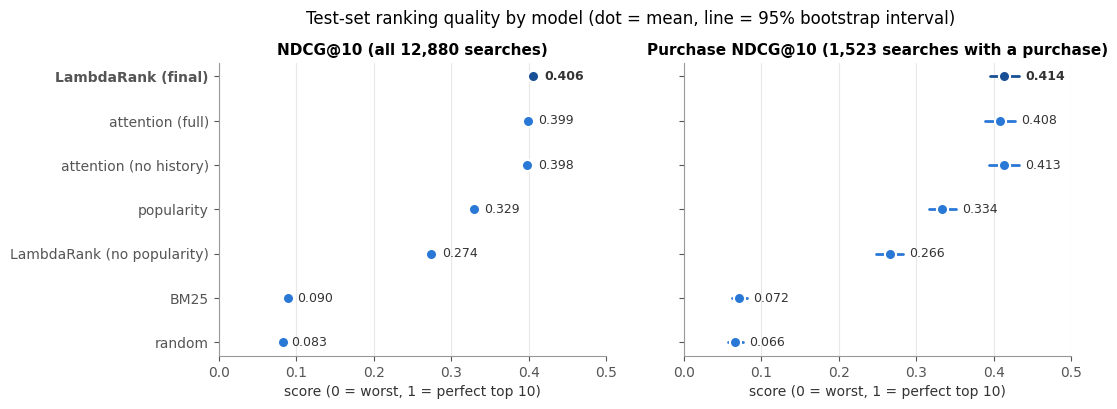

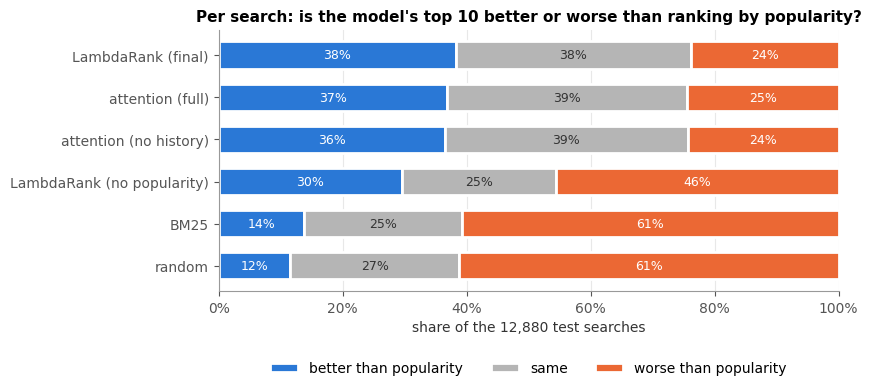

In [8]:
order = W['ndcg'][MODELS].mean().sort_values().index.tolist()       # worst to best, bottom to top
labels = [MODEL_NAMES[m] for m in order]
x_max = np.ceil((max(summary[(m, k)][2] for m in MODELS for k in ['ndcg', 'ndcg_purchase']) + 0.06) * 10) / 10
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, metric, title in [(axes[0], 'ndcg', 'NDCG@10 (all 12,880 searches)'),
                          (axes[1], 'ndcg_purchase', 'Purchase NDCG@10 (1,523 searches with a purchase)')]:
    for y, m in enumerate(order):
        mean, lo, hi = summary[(m, metric)]
        c = COL['blue_dark'] if m == 'lr' else COL['blue']
        ax.plot([lo, hi], [y, y], color=c, lw=2, solid_capstyle='round')
        ax.plot(mean, y, 'o', ms=8, color=c, mec='white', mew=1.5, zorder=3)
        ax.text(hi + 0.008, y, f'{mean:.3f}', va='center', fontsize=9, color=COL['ink'],
                fontweight='bold' if m == 'lr' else 'normal')
    ax.set_title(title)
    ax.set_xlim(0, x_max)                                  # same scale on both panels
    ax.set_xlabel('score (0 = worst, 1 = perfect top 10)')
    ax.grid(axis='y', visible=False)
axes[0].set_yticks(range(len(order)), labels)
axes[0].get_yticklabels()[order.index('lr')].set_fontweight('bold')
fig.suptitle('Test-set ranking quality by model (dot = mean, line = 95% bootstrap interval)', y=1.02)
fig.savefig(FIG / '1_overall_results.png')
plt.show()

# better / same / worse than popularity
w = wtl.loc[[MODEL_NAMES[m] for m in order if m != 'popularity']]
fig, ax = plt.subplots(figsize=(8, 3.4))
left = np.zeros(len(w))
for col, c, name in [('better', COL['blue'], 'better than popularity'),
                     ('same', COL['grey'], 'same'),
                     ('worse', COL['orange'], 'worse than popularity')]:
    ax.barh(w.index, w[col], left=left, color=c, edgecolor='white', linewidth=2, label=name, height=0.65)
    for y, (l, v) in enumerate(zip(left, w[col])):
        if v > 0.06:
            ax.text(l + v / 2, y, f'{v:.0%}', ha='center', va='center', fontsize=9,
                    color='white' if col != 'same' else COL['ink'])
    left += w[col].to_numpy()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_xlabel('share of the 12,880 test searches')
ax.set_title('Per search: is the model\'s top 10 better or worse than ranking by popularity?')
ax.grid(axis='y', visible=False)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=3)
fig.savefig(FIG / '1_better_same_worse.png')
plt.show()


**Finding (1.2).**
- The figure shows three tiers: the trained models with popularity (0.398–0.406), popularity alone and LambdaRank without popularity (0.27–0.33), and BM25 with random order (0.08–0.09).
- **The intervals of LambdaRank and the attention model overlap** in the figure, yet the paired test in 1.1 separates them on NDCG@10 (+0.007 [+0.005, +0.010]). This is why model comparisons use paired differences: both models face the same easy and hard searches, and that shared difficulty is removed before comparing.
- **Purchase intervals are about three times wider** than NDCG@10 intervals (±0.02 against ±0.006), because they rest on 1,523 searches instead of 12,880. Purchase-only claims need that caution throughout the notebook.

### 1.3 Past-project baseline (LSTM-NCF) on the same searches
Step 2 retrained the past project's **LSTM-NCF** model on the team's split and scored every product of the test searches (0.6 checks the file). Here LSTM-NCF joins the comparison with exactly the same metric (0.4), the same tie handling (5 random draws) and the same bootstrap as Section 1. Step 2's own popularity and BM25 columns are scored too, as a check that their definitions agree with ours.

**Why not use step 2's own numbers.** Step 2 reports its results with one tie-breaking draw and without intervals. Re-scoring here puts LSTM-NCF in the same table as every other model, with paired differences against it and against LambdaRank. The bootstrap reuses Section 1's resampled searches, so the intervals are directly comparable with 1.1.


In [ ]:
# add step 2's three models to Section 1's per-search tables 
STEP2_COLS = {'score_lstm_ncf': 'lstm_ncf', 'score_popularity': 'step2_popularity', 'score_bm25': 'step2_bm25'}
MODEL_NAMES.update({'lstm_ncf': 'LSTM-NCF (step 2)', 'step2_popularity': 'popularity (step 2 version)',
                    'step2_bm25': 'BM25 (step 2 version)'})
Q = P[['session_id', 'wid', 'label']].merge(
    B2[['session_id', 'wid', 'label'] + list(STEP2_COLS)].rename(columns={'label': 'label_b2'}),
    on=['session_id', 'wid'], how='left', validate='one_to_one')
assert Q[list(STEP2_COLS)].notna().all().all(), 'step 2 file does not score every test product'
assert (Q['label'] == Q['label_b2']).all(), 'labels differ from step 3a: rows joined wrongly'
for col, m in STEP2_COLS.items():
    met = per_search_metrics(Q['session_id'], Q['label'], Q[col])
    for metric in W:
        W[metric][m] = met[metric].reindex(W[metric].index)
del Q, B2, met

# same table and paired differences as Section 1 (same bootstrap draws)
COMPARE = ['random', 'bm25', 'step2_bm25', 'popularity', 'step2_popularity', 'lstm_ncf', 'lr_no_pop', 'att', 'lr']

def with_interval(m, metric):
    t, pop = values(metric)
    return fmt(t[m].mean(), *np.percentile(boot(t[m], pop), [2.5, 97.5]))

rows = []
for m in COMPARE:
    r = {'model': MODEL_NAMES[m], 'NDCG@10': with_interval(m, 'ndcg'),
         'purchase NDCG@10': with_interval(m, 'ndcg_purchase'), 'purchase in top 10': with_interval(m, 'hit_purchase')}
    for ref in ['lstm_ncf', 'lr']:
        r[f'− {MODEL_NAMES[ref]}'] = '' if m == ref else fmt(*paired(m, ref, 'ndcg'), signed=True)
    rows.append(r)
T13 = pd.DataFrame(rows).set_index('model')
print(f'{len(buy_rows):,} test searches, {buy_rows.sum():,} with a purchase. Mean [95% interval]\n')
print(T13[['NDCG@10', 'purchase NDCG@10', 'purchase in top 10']].to_string())
print('\nPaired difference in NDCG@10, mean [95% interval]')
print(T13[[f'− {MODEL_NAMES["lstm_ncf"]}', f'− {MODEL_NAMES["lr"]}']].to_string())

mean, lo, hi = paired('lr', 'lstm_ncf', 'hit_purchase')
print(f'\nLambdaRank − LSTM-NCF: {1000 * mean:+.0f} purchases on the first page per 1,000 purchase searches '
      f'[{1000 * lo:+.0f}, {1000 * hi:+.0f}]')
print('LSTM-NCF NDCG@10 here %.4f vs step 2 reported 0.3520 (one tie-breaking draw)' % W['ndcg']['lstm_ncf'].mean())


12,880 searches (the full test set), 1,523 with a purchase, 1,147,673 products

Mean [95% interval]
                                             NDCG@10         purchase NDCG@10       purchase in top 10
model                                                                                                 
random                       0.0829 [0.0795, 0.0862]  0.0665 [0.0574, 0.0761]  0.1418 [0.1254, 0.1602]
BM25                         0.0897 [0.0862, 0.0930]  0.0716 [0.0623, 0.0820]  0.1504 [0.1322, 0.1685]
BM25 (step 2 version)        0.0897 [0.0862, 0.0930]  0.0716 [0.0623, 0.0820]  0.1504 [0.1322, 0.1685]
popularity                   0.3289 [0.3231, 0.3347]  0.3336 [0.3160, 0.3518]  0.5695 [0.5443, 0.5928]
popularity (step 2 version)  0.3260 [0.3202, 0.3318]  0.3353 [0.3174, 0.3535]  0.5648 [0.5396, 0.5892]
LSTM-NCF (step 2)            0.3521 [0.3459, 0.3584]  0.3561 [0.3375, 0.3760]  0.5526 [0.5275, 0.5768]
LambdaRank (no popularity)   0.2742 [0.2684, 0.2801]  0.2657 [0.2476, 0.2830

**Finding (1.3). The past project's LSTM-NCF beats popularity, but both of our models beat it clearly.**

| | NDCG@10 | purchase in top 10 |
|---|---|---|
| LambdaRank (final) | 0.406 [0.399, 0.412] | 63.8% |
| attention (full) | 0.399 [0.392, 0.405] | 63.3% |
| **LSTM-NCF (step 2)** | **0.352** [0.346, 0.358] | **55.3%** [52.8, 57.7] |
| popularity | 0.329 [0.323, 0.335] | 57.0% |
| LambdaRank (no popularity) | 0.274 [0.268, 0.280] | 42.3% |

- **Our re-scoring reproduces step 2** (0.3521 vs 0.3520 reported, which used one tie-breaking draw).
- **LSTM-NCF is +0.023 [+0.017, +0.029] above popularity.** **LambdaRank is +0.054 [+0.050, +0.058] above LSTM-NCF** (15% higher) and the attention model +0.047 [+0.042, +0.051]. This is the comparison with past projects the report needs, now with intervals on the same 12,880 searches.
- **On purchases LSTM-NCF is no better than popularity**: 55.3% of purchased products in the top 10 against 57.0%, and purchase NDCG@10 0.356 against 0.334, with overlapping intervals. LambdaRank puts **85 more purchases on the first page per 1,000 purchase searches** than LSTM-NCF [+64, +107].
- **LSTM-NCF beats LambdaRank without popularity by 0.078.** LSTM-NCF learns a vector for each product, which can absorb how popular the product is; LambdaRank without popularity has no such signal. Our final model's lead comes from combining popularity with the history and query features (1.1).
- **Step 2's popularity and BM25 columns agree with ours.** BM25 is identical (0.0897). Step 2's popularity scores 0.326 against our 0.329, a slightly different count that changes no comparison.


## 2. Errors by segment: who does the model work for, and who does it fail?
Section 1 gave one average per model. This section splits the 12,880 test searches into groups (**segments**) and recomputes the averages inside each group.

Three kinds of segment, each tied to an earlier finding:
- **User segments**: how much history the user has and how recently they were active. The interim report found history length varies 1,000-fold between users and that history keeps clicks for 7 days only.
- **Product segments**, describing the **engaged product** (the one the model should have ranked high): is it **cold** (no training user ever acted on it), how popular is it, is it a **repeat product** for this user? The interim report found 58.5% of shown products have no training data, the reason ID-based models (NCF, NMF) fail here.
- **Search segments**: is the query common or rare, how strong is the engagement (click, cart or purchase), how long is the list, and how mixed are its categories?

### 2.1 Describe every test search by its segments
**What this step does.** It builds one table, `S`, with one row per test search and one column per segment, from the step 1a, 1b and popularity files (test searches only).

| Segment | Definition | Levels | Source |
|---|---|---|---|
| History length | past actions in the full history | 1–9, 10–49, 50–199, 200+ | `history_len_full` (1a) |
| Recent clicks | any click in the 7 days before the search | yes / no | `has_click` (1a) |
| Visit | last past action within 30 minutes of the search (an ongoing visit) | continuing / new | `in_session` (1a) |
| Past checkouts | checkouts in the last year (same-second orders merged) | 0, 1–5, 6–20, 21+ | `n_checkouts_365d` (1a) |
| Engaged product's popularity | training users who acted on the engaged product, in their history or by engaging with it in their own search (the most popular engaged product if there are several) | **cold (0)**, 1–9, 10–99, 100+ | `pop_product_users` + training labels |
| Repeat product | the user acted on an engaged product before this search | yes / no | `prod_seen_before` (1a) |
| Brand | an engaged product has no brand name in the catalogue | brand known / missing | `has_brand` (1b) |
| Query frequency | training searches with exactly the same query | 0 (new query), 1–9, 10+ | `user_subset.parquet` |
| Strongest engagement | highest label in the list | click / cart / purchase | labels |
| List length | products in the search results list | <50, 50–99, 100+ | `P` |
| Category mix | share of the list in its most common leaf category | <50%, 50–89%, 90%+ | product lookup (3b) |

**Cold products, precisely.** A product is cold if no training user acted on it, either in their history (`pop_product_users = 0`; step 3b computed this from training users only, ignoring actions ≤1 s before a search) or by engaging with it in their own search results list. A model has seen no outcome for that exact product, so anything it knows about it comes from its brand, shop, category and query match.

Everything here is information the model could have had at search time. No segment uses a test label except "strongest engagement" and the engaged-product segments, which describe *what happened* in order to group searches. They are used to read results, never as model inputs.



In [ ]:
T = TEST_SESSIONS.tolist()

# user-level features (one row per search)
hu = pd.read_parquet(FILES['hist_user'], columns=['session_id', 'history_len_full', 'has_click',
                                                   'in_session', 'n_checkouts_365d', 'days_since_last_action'])
hu = hu.set_index('session_id').reindex(TEST_SESSIONS)       # same order as the test searches

# product-level features for every test candidate
E = P[['session_id', 'wid', 'label', 'popularity']].copy()
hc = pd.read_parquet(FILES['hist_cand'], columns=['session_id', 'wid', 'prod_seen_before'],
                     filters=[('session_id', 'in', T)])
E = E.merge(hc, on=['session_id', 'wid'], how='left', validate='one_to_one')
qi = pd.read_parquet(FILES['query_item'], columns=['session_id', 'candidate_id', 'has_brand'])
E = E.merge(qi.rename(columns={'candidate_id': 'wid'}), on=['session_id', 'wid'], how='left', validate='one_to_one')
E['has_brand'] = E['has_brand'].fillna(0)                  # no catalogue row -> no brand
lookup = pd.read_parquet(FILES['lookup'], columns=['wid', 'cate_id_4', 'shop_id']).set_index('wid')
E['cate4'] = E['wid'].map(lookup['cate_id_4']).fillna(-1).astype('int64')
E['shop'] = E['wid'].map(lookup['shop_id']).fillna(-1).astype('int64')
del hc, qi, lookup

# training searches in which each product was engaged (clicked, carted or bought)
train_eng = pd.read_parquet(FILES['hist_cand'], columns=['wid', 'label', 'split'],
                            filters=[('split', '==', 'train'), ('label', '>', 0)])
E['train_engaged'] = E['wid'].map(train_eng['wid'].value_counts()).fillna(0)
E['n_train'] = E['popularity'] + E['train_engaged']          # training users who acted on the product
E['cold'] = E['n_train'] == 0
del train_eng
assert E[['prod_seen_before']].notna().all().all() and len(E) == len(P)

print('Test candidates that are cold (no training user acted on them): %.1f%%' % (100 * E['cold'].mean()))
print('Engaged test products that are cold:                             %.1f%%' % (100 * E.loc[E['label'] > 0, 'cold'].mean()))
print('Purchased test products that are cold:                           %.1f%%' % (100 * E.loc[E['label'] == 3, 'cold'].mean()))

# query frequency among training searches
us = pd.read_parquet(FILES['user_subset'], columns=['query', 'split'])
train_q = us.loc[us['split'] == 'train', 'query'].value_counts()
q_freq = us.loc[TEST_SESSIONS, 'query'].map(train_q).fillna(0)
del us

# one row per search
eng = E[E['label'] > 0]
g_all, g_eng = E.groupby('session_id'), eng.groupby('session_id')   # both sorted by session_id, like TEST_SESSIONS
assert (g_eng.size().index == TEST_SESSIONS).all()
cate_top = E.groupby(['session_id', 'cate4']).size().groupby('session_id').max()

def bucket(x, edges, labels):
    return pd.cut(x, edges, labels=labels, right=False)

S = pd.DataFrame(index=pd.Index(TEST_SESSIONS, name='session_id'))
S['history length']   = bucket(hu['history_len_full'], [1, 10, 50, 200, np.inf], ['1–9', '10–49', '50–199', '200+'])
S['recent clicks']    = pd.Categorical(np.where(hu['has_click'] == 1, 'clicked in last 7 days', 'no click in 7 days'),
                                       ['clicked in last 7 days', 'no click in 7 days'], ordered=True)
S['visit']            = pd.Categorical(np.where(hu['in_session'] == 1, 'continuing', 'new'), ['continuing', 'new'], ordered=True)
S['past checkouts']   = bucket(hu['n_checkouts_365d'], [0, 1, 6, 21, np.inf], ['0', '1–5', '6–20', '21+'])
S['engaged product popularity'] = bucket(g_eng['n_train'].max(), [0, 1, 10, 100, np.inf], ['cold (0)', '1–9', '10–99', '100+'])
S['repeat product']   = pd.Categorical(np.where(g_eng['prod_seen_before'].max() == 1, 'yes', 'no'), ['yes', 'no'], ordered=True)
S['brand']            = pd.Categorical(np.where(g_eng['has_brand'].min() == 0, 'missing', 'known'), ['known', 'missing'], ordered=True)
S['query frequency']  = bucket(q_freq.to_numpy(), [0, 1, 10, np.inf], ['0 (new)', '1–9', '10+'])
S['strongest engagement'] = pd.Categorical(g_all['label'].max().map({1: 'click', 2: 'cart', 3: 'purchase'}),
                                           ['click', 'cart', 'purchase'], ordered=True)
S['list length']      = bucket(g_all.size(), [0, 50, 100, np.inf], ['<50', '50–99', '100+'])
S['category mix']     = bucket(cate_top / g_all.size(), [0, 0.5, 0.9, 1.01], ['<50%', '50–89%', '90%+'])
# kept for later sections, not a segment
S['n_engaged'] = g_eng.size()
S['last_gap_s'] = (hu['days_since_last_action'] * 86400).round()
assert S.drop(columns=['last_gap_s']).notna().all().all(), S.isna().sum()

SEGMENTS = {
    'user':    ['history length', 'recent clicks', 'visit', 'past checkouts'],
    'product': ['engaged product popularity', 'repeat product', 'brand'],
    'search':  ['query frequency', 'strongest engagement', 'list length', 'category mix'],
}
for group, cols in SEGMENTS.items():
    print(f'\n=== {group} segments (searches, share)')
    for c in cols:
        vc = S[c].value_counts(sort=False)
        print(f'{c:28s}', ' | '.join(f'{k}: {v:,} ({v / len(S):.0%})' for k, v in vc.items()))
del hu, g_all, g_eng, cate_top


Test candidates that are cold (no training user acted on them): 67.2%
Engaged test products that are cold:                             38.0%
Purchased test products that are cold:                           19.7%

=== user segments (searches, share)
history length               1–9: 1,231 (10%) | 10–49: 3,630 (28%) | 50–199: 4,996 (39%) | 200+: 3,023 (23%)
recent clicks                clicked in last 7 days: 10,763 (84%) | no click in 7 days: 2,117 (16%)
visit                        continuing: 5,317 (41%) | new: 7,563 (59%)
past checkouts               0: 1,102 (9%) | 1–5: 3,255 (25%) | 6–20: 3,985 (31%) | 21+: 4,538 (35%)

=== product segments (searches, share)
engaged product popularity   cold (0): 3,180 (25%) | 1–9: 4,115 (32%) | 10–99: 3,927 (30%) | 100+: 1,658 (13%)
repeat product               yes: 1,902 (15%) | no: 10,978 (85%)
brand                        known: 12,300 (95%) | missing: 580 (5%)

=== search segments (searches, share)
query frequency              0 (new): 8,332 (

**Finding (2.1).**
- **Cold products are the norm, not the exception.** **67.2%** of test candidates, **38.0%** of engaged test products and **19.7%** of purchased test products were never acted on by any training user. These shares are higher than the interim report's full-data figures (58.5% of candidates, 30.0% of engaged products) because the team's training split holds 60,104 users rather than 139,064: fewer training users means fewer products seen. Purchases fall on cold products half as often as engagement in general, a first sign that purchases lean towards popular products.
- **In 25% of test searches (3,180) every engaged product is cold.** For these searches no model has ever seen an outcome for the product that should rank first.
- **15% of searches (1,902) have a repeat product**: the user acted on an engaged product before this search.
- **65% of test queries never occur among the training searches** (exact match on the query terms), so a model cannot rely on having seen the same query before.
- The other segments are reasonably balanced: 41% of searches continue a visit, 16% of users have no click in the 7 days before, 9% have no checkout in the past year, 5% of searches have an engaged product without a brand name, and 56% / 32% / 12% have a click, cart or purchase as the strongest engagement.


### 2.2 Ranking quality in each segment
A segment where every model scores low is a hard segment (e.g. the engaged product is cold). A segment where LambdaRank scores high but popularity also scores high is one where the model mostly repeats popularity. The interesting segments are where models **diverge**.

- NDCG@10 per search comes from Section 0.5; here it is averaged within each level.
- The table gives, per level: searches, LambdaRank (final) NDCG@10 with a 95% bootstrap interval, popularity, attention (full), LambdaRank without popularity, random, and the share of searches where LambdaRank ranks **worse** than popularity.
- **Random order is shown for scale.** Its NDCG depends on the list itself (a short list with three engaged products is easy even at random), so comparing a model with random *inside* a segment separates "this segment is easy" from "the model is good here".

**Caveats when reading.**
- **Segments overlap.** Users with long histories also have more repeat products, so a gap by history length may really be a repeat-product effect. These are descriptions, not causes.
- **Many comparisons.** With 35 segment levels, one or two will look unusual by chance. Only gaps whose intervals clearly separate are claimed.


=== user segments: NDCG@10 by level
                                       searches    LambdaRank (final) popularity attention (full) LambdaRank (no popularity) random LR worse than popularity
segment        level                                                                                                                                        
history length 1–9                         1231  0.378 [0.358, 0.397]      0.314            0.370                      0.241  0.086                      23%
               10–49                       3630  0.398 [0.386, 0.411]      0.329            0.390                      0.268  0.081                      24%
               50–199                      4996  0.408 [0.398, 0.418]      0.331            0.401                      0.270  0.083                      23%
               200+                        3023  0.423 [0.409, 0.435]      0.331            0.416                      0.303  0.083                      25%
recent clicks  clicke

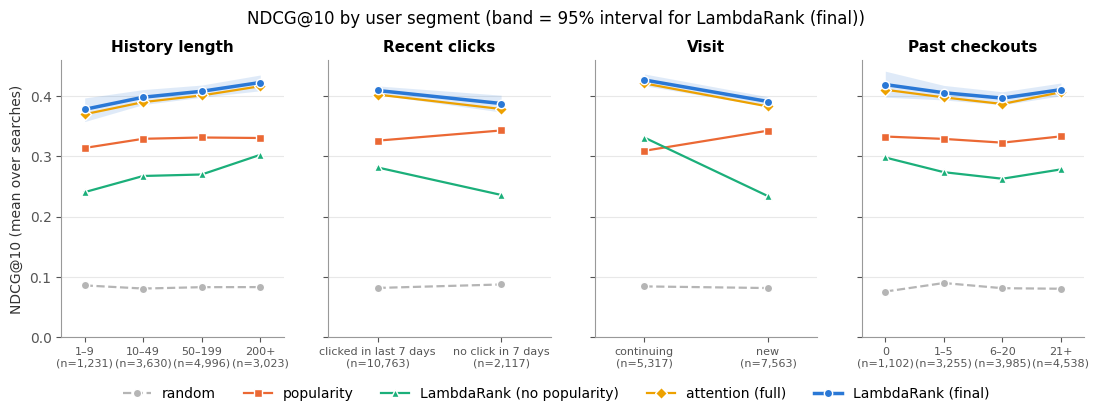

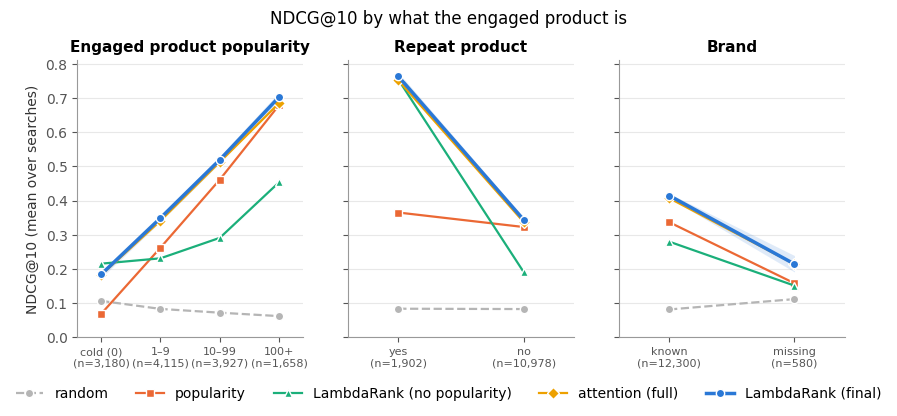

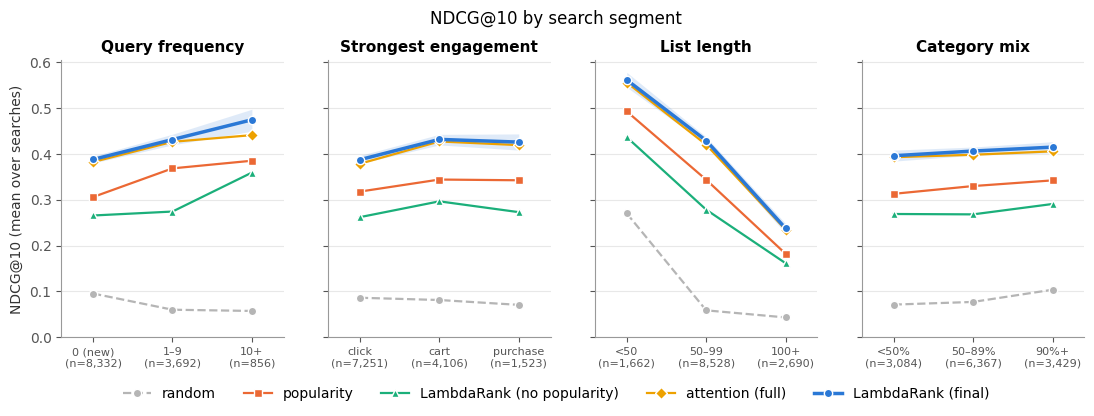

In [11]:
SEG_MODELS = ['random', 'popularity', 'lr_no_pop', 'att', 'lr']
SEG_STYLE = {'random':    dict(color=COL['grey'], ls='--', marker='o'),
             'popularity':dict(color=COL['orange'], ls='-', marker='s'),
             'lr_no_pop': dict(color=COL['aqua'], ls='-', marker='^'),
             'att':       dict(color=COL['yellow'], ls='-', marker='D'),
             'lr':        dict(color=COL['blue'], ls='-', marker='o', lw=2.5)}
N_BOOT_SEG = 1000
MIN_SEG = 30                                     # levels with fewer searches are listed, not analysed
nd = W['ndcg'].loc[S.index]                       # searches x models, same order as S

def ci_mean(x, rng):
    x = np.asarray(x, dtype='float64')
    b = x[rng.integers(0, len(x), (N_BOOT_SEG, len(x)))].mean(axis=1)
    return np.percentile(b, [2.5, 97.5])

rng_seg = np.random.default_rng(SEED)
rows = []
for group, cols in SEGMENTS.items():
    for c in cols:
        for level in S[c].cat.categories:
            mask = (S[c] == level).to_numpy()
            if mask.sum() < MIN_SEG:
                print(f'not analysed (fewer than {MIN_SEG} searches): {c} = {level} ({mask.sum()} searches)')
                continue
            x = nd[mask]
            lo, hi = ci_mean(x['lr'], rng_seg)
            rows.append({'group': group, 'segment': c, 'level': level, 'searches': int(mask.sum()),
                         **{m: x[m].mean() for m in SEG_MODELS}, 'lr_lo': lo, 'lr_hi': hi,
                         'worse_than_pop': ((x['lr'] - x['popularity']) < -TIE_TOL).mean()})
SEG = pd.DataFrame(rows)

show = SEG.copy()
show['LambdaRank (final)'] = [f'{m:.3f} [{lo:.3f}, {hi:.3f}]' for m, lo, hi in zip(show['lr'], show['lr_lo'], show['lr_hi'])]
for m in ['popularity', 'att', 'lr_no_pop', 'random']:
    show[MODEL_NAMES[m]] = show[m].map('{:.3f}'.format)
show['LR worse than popularity'] = show['worse_than_pop'].map('{:.0%}'.format)
cols_out = ['searches', 'LambdaRank (final)', 'popularity', 'attention (full)', 'LambdaRank (no popularity)', 'random', 'LR worse than popularity']
for group in SEGMENTS:
    print(f'\n=== {group} segments: NDCG@10 by level')
    print(show[show['group'] == group].set_index(['segment', 'level'])[cols_out].to_string())

def plot_segments(group, title, fname):
    cols = SEGMENTS[group]
    fig, axes = plt.subplots(1, len(cols), figsize=(3.3 * len(cols), 3.6), sharey=True)
    for ax, c in zip(np.atleast_1d(axes), cols):
        d = SEG[SEG['segment'] == c]
        x = np.arange(len(d))
        ax.fill_between(x, d['lr_lo'], d['lr_hi'], color=COL['blue'], alpha=0.15, lw=0)
        for m in SEG_MODELS:
            st = SEG_STYLE[m]
            ax.plot(x, d[m], ms=6, mec='white', mew=1, lw=st.get('lw', 1.6), color=st['color'],
                    ls=st['ls'], marker=st['marker'], label=MODEL_NAMES[m], zorder=3 if m == 'lr' else 2)
        ax.set_xticks(x, [f'{l}\n(n={n:,})' for l, n in zip(d['level'], d['searches'])], fontsize=8)
        ax.set_title(c.capitalize())
        ax.set_xlim(-0.4, len(d) - 0.6)
        ax.grid(axis='x', visible=False)
    np.atleast_1d(axes)[0].set_ylabel('NDCG@10 (mean over searches)')
    np.atleast_1d(axes)[0].set_ylim(0, None)
    handles, labels = np.atleast_1d(axes)[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=len(SEG_MODELS), bbox_to_anchor=(0.5, -0.1))
    fig.suptitle(title, y=1.02)
    fig.savefig(FIG / fname)
    plt.show()

plot_segments('user', 'NDCG@10 by user segment (band = 95% interval for LambdaRank (final))', '2_ndcg_by_user_segment.png')
plot_segments('product', 'NDCG@10 by what the engaged product is', '2_ndcg_by_product_segment.png')
plot_segments('search', 'NDCG@10 by search segment', '2_ndcg_by_search_segment.png')


**Finding (2.2). What the engaged product is matters far more than who the user is.**
- **Product segments create the largest gaps.**
  - **Engaged product popularity.** LambdaRank (final) scores **0.184** when every engaged product is cold, rising to 0.349, 0.520 and **0.703** as the engaged product becomes more popular (1–9, 10–99, 100+ training users). On cold-product searches it is barely above random order (0.107).
  - **Popularity actively harms cold products.** Ranking by popularity alone scores 0.068 on cold-product searches, **below random**, because every cold product has popularity 0 and is pushed to the bottom. LambdaRank *without* popularity (0.215) beats the final model (0.184) on these searches.
  - **Repeat products are where the model shines.** With a repeat product LambdaRank scores **0.763**, against 0.344 without one. LambdaRank without popularity scores almost the same (0.754), and popularity alone only 0.365: the user's own history finds these products, popularity cannot.
  - Searches whose engaged product has no brand name score 0.214 against 0.415 (580 searches).
- **User segments matter only mildly.** NDCG@10 rises from 0.378 (1–9 past actions) to 0.423 (200+), is higher in continuing visits (0.427 vs 0.391), and slightly lower for users with no click in the last 7 days (0.388 vs 0.409). Past checkouts make no difference.
- **Search segments mostly reflect how hard the list is.** NDCG@10 falls from 0.561 on lists under 50 products to 0.237 on lists of 100+, but random order falls in step (0.270 → 0.043): longer lists are harder for everyone. Queries seen 10+ times in training score higher (0.474 vs 0.388 for new queries). Category mix makes no difference.
- **The attention model tracks LambdaRank in every segment** (at most 0.03 lower, usually under 0.01). There is no group of users or products where reading the history step by step helps.
- **LambdaRank is worse than popularity in 27% of searches without a repeat product but only 5% of searches with one.**

### 2.3 Where does the model add value, and where does popularity?
For every segment level it computes two **paired gains** with 95% intervals and draws them side by side (`2_gain_by_segment.png`):
1. **LambdaRank (final) − popularity**: what the full model adds on top of ranking by popularity alone. Section 1 found +0.077 overall.
2. **LambdaRank (final) − LambdaRank (no popularity)**: what the 13 popularity features add to the model (Ning's suggestion). Section 1 found +0.132 overall.

**Why.** Section 1 showed that popularity alone gets three quarters of the way, and that LambdaRank is worse than popularity in 24% of searches. The first gain shows **where the extra features earn their place** (e.g. repeat products, long histories) and where the model adds nothing over popularity. The second shows **where popularity is doing the work**, and where it cannot help (it carries no information about a cold product).

**How.** Within each level, the per-search difference between the two models is bootstrapped (1,000 resamples) for the interval, as in 1.1.

**How to read the figure.** One row per segment level, grouped by segment. A dot right of the zero line means LambdaRank (final) is better. **Blue**: the interval is entirely above zero (a real gain). **Grey**: the interval crosses zero (no measurable difference). **Orange**: the interval is entirely below zero (a real loss).


Paired gains in NDCG@10 by segment, mean [95% interval]

                                                   searches  LambdaRank − popularity what popularity adds to LambdaRank
segment                    level                                                                                       
history length             1–9                         1231  +0.064 [+0.053, +0.076]            +0.137 [+0.120, +0.154]
                           10–49                       3630  +0.069 [+0.061, +0.077]            +0.131 [+0.120, +0.140]
                           50–199                      4996  +0.077 [+0.069, +0.084]            +0.138 [+0.130, +0.147]
                           200+                        3023  +0.092 [+0.082, +0.101]            +0.120 [+0.110, +0.130]
recent clicks              clicked in last 7 days     10763  +0.083 [+0.078, +0.088]            +0.128 [+0.122, +0.133]
                           no click in 7 days          2117  +0.045 [+0.036, +0.054]            +0.152 

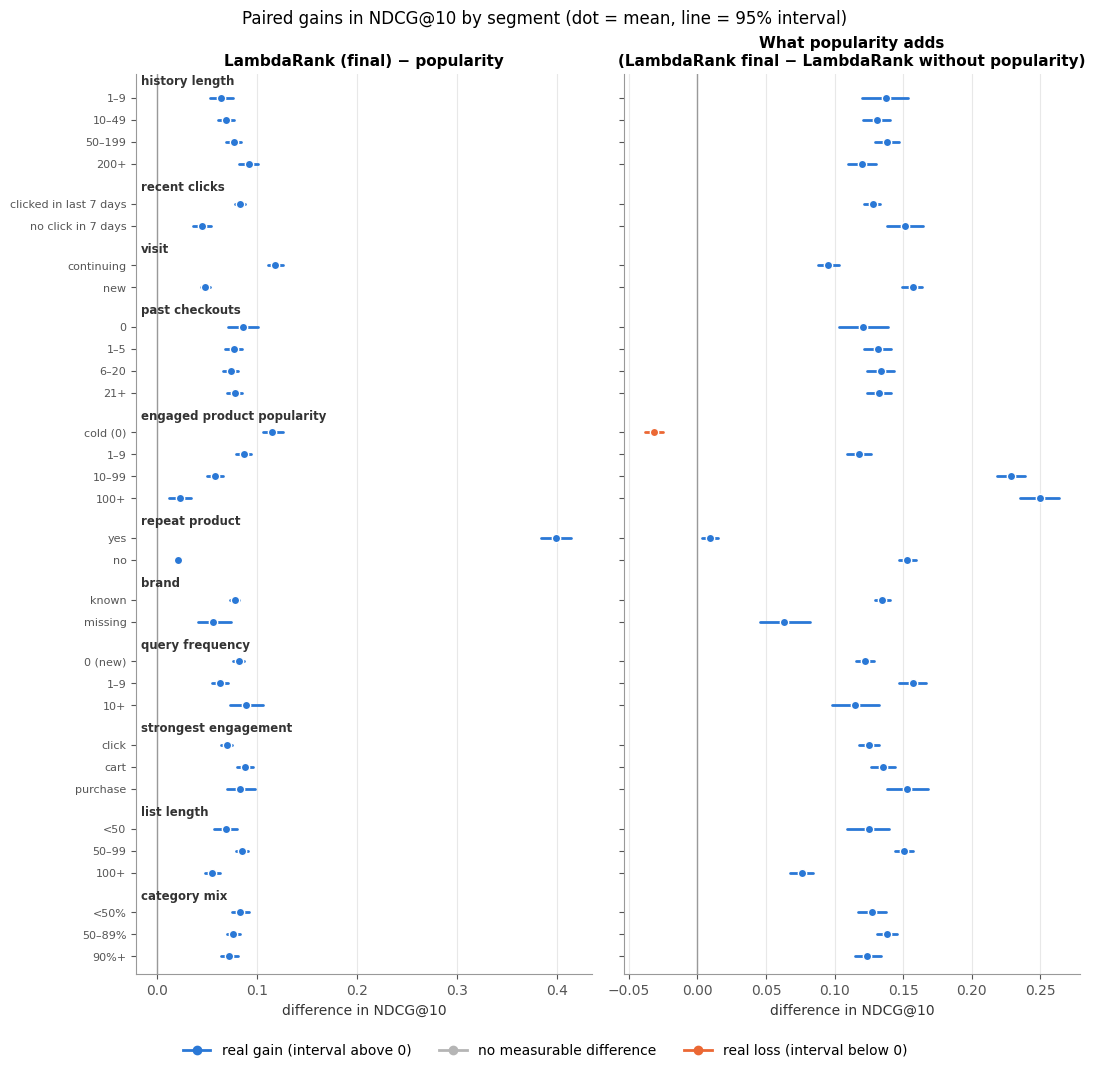

In [ ]:
def paired_gain(a, b, mask, rng):
    d = (nd[a] - nd[b]).to_numpy()[mask]
    lo, hi = ci_mean(d, rng)
    return d.mean(), lo, hi

rng_gain = np.random.default_rng(SEED)
GAIN = []
for group, cols in SEGMENTS.items():
    for c in cols:
        for level in S[c].cat.categories:
            mask = (S[c] == level).to_numpy()
            if mask.sum() < MIN_SEG:
                continue
            r = {'segment': c, 'level': level, 'searches': int(mask.sum())}
            for name, (a, b) in {'vs_pop': ('lr', 'popularity'), 'pop_adds': ('lr', 'lr_no_pop')}.items():
                r[name], r[name + '_lo'], r[name + '_hi'] = paired_gain(a, b, mask, rng_gain)
            GAIN.append(r)
GAIN = pd.DataFrame(GAIN)

out = GAIN[['segment', 'level', 'searches']].copy()
out['LambdaRank − popularity'] = [f'{m:+.3f} [{lo:+.3f}, {hi:+.3f}]' for m, lo, hi in GAIN[['vs_pop', 'vs_pop_lo', 'vs_pop_hi']].to_numpy()]
out['what popularity adds to LambdaRank'] = [f'{m:+.3f} [{lo:+.3f}, {hi:+.3f}]' for m, lo, hi in GAIN[['pop_adds', 'pop_adds_lo', 'pop_adds_hi']].to_numpy()]
print('Paired gains in NDCG@10 by segment, mean [95% interval]\n')
print(out.set_index(['segment', 'level']).to_string())

# figure
labels, ypos, y, seg_starts = [], [], 0, []
for c in GAIN['segment'].unique():
    seg_starts.append((y, c))
    for lvl in GAIN.loc[GAIN['segment'] == c, 'level']:
        labels.append(f'{lvl}')
        ypos.append(y)
        y += 1
    y += 0.8                                            # gap between segments
ypos = np.array(ypos)

def colour(lo, hi):
    return COL['blue'] if lo > 0 else (COL['orange'] if hi < 0 else COL['grey'])

fig, axes = plt.subplots(1, 2, figsize=(11, 0.26 * len(ypos) + 2.5), sharey=True)
for ax, key, title in [(axes[0], 'vs_pop', 'LambdaRank (final) − popularity'),
                       (axes[1], 'pop_adds', 'What popularity adds\n(LambdaRank final − LambdaRank without popularity)')]:
    ax.axvline(0, color='#999999', lw=1)
    for yy, (m, lo, hi) in zip(ypos, GAIN[[key, key + '_lo', key + '_hi']].to_numpy()):
        c = colour(lo, hi)
        ax.plot([lo, hi], [yy, yy], color=c, lw=2, solid_capstyle='round')
        ax.plot(m, yy, 'o', color=c, ms=6, mec='white', mew=1)
    ax.set_title(title)
    ax.set_xlabel('difference in NDCG@10')
    ax.grid(axis='y', visible=False)
axes[0].set_yticks(ypos, labels, fontsize=8)
axes[0].set_ylim(ypos.max() + 0.8, -1.1)                # top to bottom, room for the first heading
for y0, c in seg_starts:                                # segment name as a heading above its levels
    axes[0].text(0.01, y0 - 0.75, c, transform=axes[0].get_yaxis_transform(), fontsize=8.5,
                 fontweight='bold', va='center', ha='left', color=COL['ink'])
from matplotlib.lines import Line2D
fig.suptitle('Paired gains in NDCG@10 by segment (dot = mean, line = 95% interval)')
fig.tight_layout(rect=(0, 0.035, 1, 1))
fig.legend([Line2D([], [], color=COL['blue'], marker='o', lw=2), Line2D([], [], color=COL['grey'], marker='o', lw=2),
            Line2D([], [], color=COL['orange'], marker='o', lw=2)],
           ['real gain (interval above 0)', 'no measurable difference', 'real loss (interval below 0)'],
           loc='lower center', ncol=3, bbox_to_anchor=(0.5, 0))
fig.savefig(FIG / '2_gain_by_segment.png')
plt.show()


**Finding (2.3). LambdaRank's gain over popularity comes mostly from repeat products, and popularity hurts cold products.**
- **LambdaRank beats popularity in every segment** (all blue in the left panel), but the size of the gain varies twenty-fold:
  - **Repeat product: +0.398** [+0.384, +0.414]. **No repeat product: +0.021** [+0.018, +0.024].
  - Weighting by the number of searches, **77% of LambdaRank's overall gain over popularity (+0.077) comes from the 15% of searches with a repeat product** (1,902 × 0.398 against 10,978 × 0.021). For the other 85% of searches, the 36 query, product and history features add only 0.021 NDCG@10 on top of popularity.
  - The gain is also larger in continuing visits (+0.117 vs +0.048 for new visits) and smaller for users with no recent click (+0.045). These segments overlap with repeat products (a user browsing right before the search is more likely to see a product again), so they are not independent effects.
  - The gain shrinks as the engaged product gets more popular (+0.115 cold, +0.023 for 100+ users): for popular products, popularity already ranks them well.
- **What popularity adds to LambdaRank depends on the engaged product** (right panel):
  - **+0.249** when the engaged product is very popular (100+ training users) and **+0.228** for 10–99.
  - **−0.032 [−0.038, −0.025] when the engaged product is cold**: the only real loss in the figure. For a quarter of all test searches, adding popularity makes the model worse.
  - **+0.009 for repeat products**: the history features already find them.
- **Implications.**
  - **For the model:** the final model is close to "popularity, plus a repeat-product detector". The gap diagnosis predicted brand, shop and category features would carry cold products. They do lift LambdaRank without popularity well above popularity on cold-product searches (0.215 vs 0.068), but the final model trades that away to rank popular products higher. A cold-aware treatment of popularity (for example, letting the model know a zero means "no data" rather than "unpopular", or reporting cold-product results separately as a target) is the clearest next step.
  - **For the business:** the model is strong at "buy it again" and at popular products, and weak at helping users find products nobody has bought yet. That is 38% of engaged products and a quarter of searches, so new and niche sellers get the least help from it. Section 6 quantifies this exposure.

### 2.4 Where does the past-project baseline (LSTM-NCF) fail?
**What this step does.** It repeats the key segments of 2.2 for LSTM-NCF, next to popularity and LambdaRank (final): the popularity of the engaged product (including **cold**: no training user acted on it), whether the search has a **repeat product**, and the user's **history length**. For each level it gives the NDCG@10 of each model and two paired differences with 95% intervals: LSTM-NCF − popularity and LambdaRank − LSTM-NCF.

Our interim report's gap diagnosis predicted that models built on product IDs (the NCF/NMF family of past projects) have nothing to learn from for most products: 58.5% of shown products had no training data on the full dataset, 67.2% on the team's split (2.1). If that is right, LSTM-NCF should do well on popular and repeat products and fall towards random order on cold ones. This step tests the prediction on the model itself rather than on data counts.

NDCG@10 by segment, with paired differences [95% interval]

                                     searches random popularity LSTM-NCF (step 2) LambdaRank (final)    LSTM-NCF − popularity    LambdaRank − LSTM-NCF
segment                    level                                                                                                                      
engaged product popularity cold (0)      3180  0.107      0.068             0.193              0.184  +0.125 [+0.115, +0.135]  -0.010 [-0.016, -0.003]
                           1–9           4115  0.083      0.262             0.286              0.349  +0.024 [+0.012, +0.034]  +0.063 [+0.055, +0.071]
                           10–99         3927  0.072      0.462             0.451              0.520  -0.011 [-0.022, -0.000]  +0.069 [+0.061, +0.077]
                           100+          1658  0.062      0.680             0.587              0.703  -0.093 [-0.108, -0.077]  +0.116 [+0.104, +0.128]
repeat product             yes    

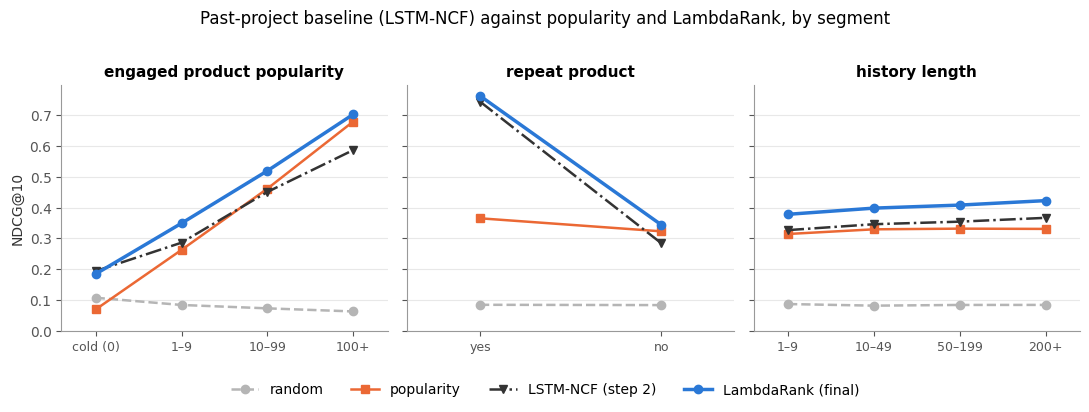

In [13]:
MODELS24 = ['random', 'popularity', 'lstm_ncf', 'lr']
STYLE24 = {**SEG_STYLE, 'lstm_ncf': dict(color=COL['ink'], ls='-.', marker='v')}
SEG24_COLS = ['engaged product popularity', 'repeat product', 'history length']
rng24 = np.random.default_rng(SEED)
rows = []
for c in SEG24_COLS:
    for level in S[c].cat.categories:
        mask = (S[c] == level).to_numpy()
        if mask.sum() < MIN_SEG:
            continue
        x = nd[mask]
        r = {'segment': c, 'level': level, 'searches': int(mask.sum())}
        r.update({m: x[m].mean() for m in MODELS24})
        for name, (a, b) in {'LSTM-NCF − popularity': ('lstm_ncf', 'popularity'),
                             'LambdaRank − LSTM-NCF': ('lr', 'lstm_ncf')}.items():
            d = (x[a] - x[b]).to_numpy()
            lo, hi = ci_mean(d, rng24)
            r[name] = f'{d.mean():+.3f} [{lo:+.3f}, {hi:+.3f}]'
        rows.append(r)
SEG24 = pd.DataFrame(rows)
show24 = SEG24.set_index(['segment', 'level']).rename(columns=MODEL_NAMES)
print('NDCG@10 by segment, with paired differences [95% interval]\n')
print(show24.to_string(formatters={MODEL_NAMES[m]: '{:.3f}'.format for m in MODELS24}))

fig, axes = plt.subplots(1, len(SEG24_COLS), figsize=(11, 3.7), sharey=True)
for ax, c in zip(axes, SEG24_COLS):
    d = SEG24[SEG24['segment'] == c]
    xs = np.arange(len(d))
    for m in MODELS24:
        st = STYLE24[m]
        ax.plot(xs, d[m], color=st['color'], ls=st['ls'], marker=st['marker'], lw=st.get('lw', 1.8), ms=6,
                label=MODEL_NAMES[m])
    ax.set_xticks(xs, d['level'], fontsize=9)
    ax.set_xlim(-0.4, len(d) - 0.6)
    ax.set_title(c)
    ax.grid(axis='x', visible=False)
axes[0].set_ylabel('NDCG@10')
axes[0].set_ylim(0, None)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(MODELS24), bbox_to_anchor=(0.5, -0.06))
fig.suptitle('Past-project baseline (LSTM-NCF) against popularity and LambdaRank, by segment', y=1.02)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(FIG / '2_lstm_ncf_by_segment.png')
plt.show()


**Finding (2.4). The interim report's prediction does not hold: LSTM-NCF does not collapse on cold products. It falls behind on popular ones.**

| engaged product | searches | random | popularity | LSTM-NCF | LambdaRank (final) | LambdaRank − LSTM-NCF |
|---|---|---|---|---|---|---|
| cold (0 training users) | 3,180 | 0.107 | 0.068 | **0.193** | 0.184 | **−0.010** [−0.016, −0.003] |
| 1–9 users | 4,115 | 0.083 | 0.262 | 0.286 | 0.349 | +0.063 [+0.055, +0.071] |
| 10–99 users | 3,927 | 0.072 | 0.462 | 0.451 | 0.520 | +0.069 [+0.061, +0.077] |
| 100+ users | 1,658 | 0.062 | 0.680 | 0.587 | 0.703 | +0.116 [+0.104, +0.128] |

- **On cold-product searches LSTM-NCF is well above random order (0.193 vs 0.107) and slightly above our final model** (by 0.010). A model that only knew product IDs would rank cold products at random, so LSTM-NCF must use something besides the ID. The model file's name (`best_lstm_ncf_4emb.pt`) suggests four embedding tables, for example product, brand, shop and category, which would let it score products it never saw. 
- **Its weakness is popular products.** With 100+ training users LSTM-NCF scores 0.587, below popularity alone (0.680), and LambdaRank's lead over it grows from −0.010 on cold products to +0.116.
- **Like LambdaRank, it wins on repeat products**: 0.745 with a repeat product (LambdaRank 0.763) against 0.284 without, which is below popularity (0.323). The LSTM over the user's history finds products the user touched before.
- **History length makes little difference** (0.327 for 1–9 past actions, 0.367 for 200+); LambdaRank stays about 0.05 ahead at every level.
- **What this changes.** The interim's gap diagnosis was right about the data (most products have no training data of their own) but wrong to predict that an NCF-style model would therefore fail: with attribute information it handles cold products as well as our final model. It also confirms 2.3 from another angle: models that do not penalise zero popularity do better on cold searches (LambdaRank without popularity 0.215, LSTM-NCF 0.193) than the final model (0.184) and popularity (0.068).



## 3. Failure analysis: when the model misses, what went wrong?
Section 2 found where the model is weak on average. This section looks at the **individual searches it gets wrong** and asks what they have in common. A search counts as a **failure** when **no engaged product reaches LambdaRank's top 10**: the user would have had to scroll past ten products to find anything they wanted.

### 3.1 Where do engaged and purchased products end up in the ranking?
For every test search it finds the **rank of the first engaged product** (the highest-placed product the user clicked, carted or bought) under each model, and for purchase searches the **rank of the purchased product**. It then shows how these ranks are spread: rank 1, 2–3, 4–10, 11–30, 31–100, 101+.

NDCG@10 compresses everything beyond position 10 into zero. A search where the engaged product sits at rank 11 and one where it sits at rank 150 count the same. The rank distribution shows whether failures are near misses (just outside the top 10) or the product is buried.

- Ranks are computed from each model's scores within each search, with ties broken by one random draw (seed 42). One draw is enough for ranks; averaging (as in 0.4) matters for the small differences in NDCG.
- `R` holds one row per test product with the rank under each model.



Rank of the first engaged product (12,880 searches): share of searches per rank band
                                1    2–3   4–10  11–30 31–100  101+ in top 10 median rank
random                       3.0%   4.9%  14.7%  29.5%  46.2%  1.6%     22.7%          29
popularity                  18.8%  17.9%  25.5%  20.7%  16.3%  0.8%     62.3%           6
LambdaRank (no popularity)  17.7%  12.9%  21.4%  24.8%  22.5%  0.8%     52.0%          10
attention (full)            26.3%  19.6%  23.9%  18.5%  11.4%  0.5%     69.7%           4
LambdaRank (final)          27.1%  19.4%  23.7%  18.8%  10.5%  0.5%     70.2%           4

Rank of the purchased product (1,523 searches): share of searches per rank band
                                1    2–3   4–10  11–30 31–100  101+ in top 10 median rank
random                       1.9%   2.7%   9.6%  23.4%  56.4%  6.0%     14.2%          42
popularity                  14.6%  17.5%  25.4%  21.3%  19.3%  1.9%     57.5%           8
LambdaRank (no populari

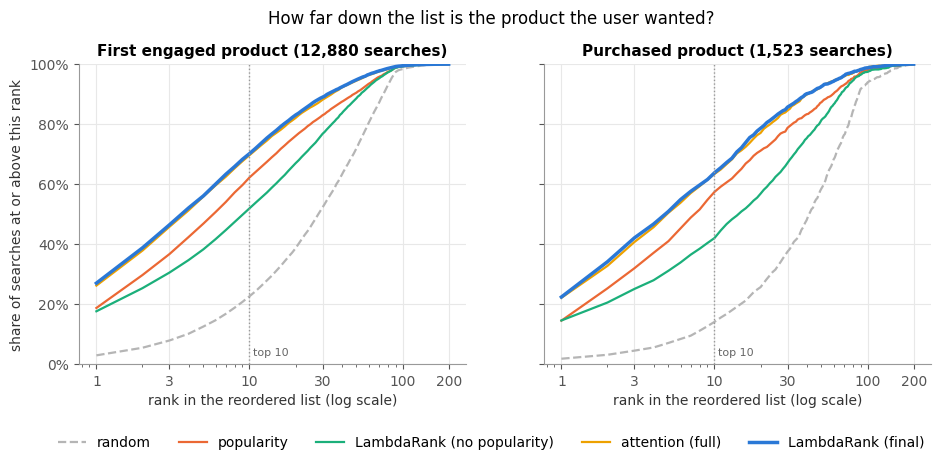

In [ ]:
RANK_MODELS = ['random', 'popularity', 'lr_no_pop', 'att', 'lr']

def row_rank(score, seed=SEED):
    # 1-based rank of every row within its search (higher score = better), ties broken at random
    order, r = _ranks(P['session_id'].to_numpy(), np.asarray(score, dtype='float64'), np.random.default_rng(seed))
    out = np.empty(len(r), dtype=np.int32)
    out[order] = r
    return out

assert (E['wid'].to_numpy() == P['wid'].to_numpy()).all(), 'E and P rows are not aligned'
R = P[['session_id', 'wid', 'label']].copy()
for m in RANK_MODELS:
    R[m] = row_rank(P[m])

first_rank = R[R['label'] > 0].groupby('session_id')[RANK_MODELS].min()       # one row per search
buy_rank = R[R['label'] == 3].groupby('session_id')[RANK_MODELS].min()        # purchase searches only
BANDS = [0, 1, 3, 10, 30, 100, np.inf]
BAND_NAMES = ['1', '2–3', '4–10', '11–30', '31–100', '101+']

def band_table(ranks):
    t = {MODEL_NAMES[m]: pd.cut(ranks[m], BANDS, labels=BAND_NAMES).value_counts(normalize=True, sort=False)
         for m in RANK_MODELS}
    t = pd.DataFrame(t).T
    t['in top 10'] = t[['1', '2–3', '4–10']].sum(axis=1)
    t['median rank'] = [ranks[m].median() for m in RANK_MODELS]
    return t

for name, ranks in [('first engaged product', first_rank), ('purchased product', buy_rank)]:
    t = band_table(ranks)
    print(f'\nRank of the {name} ({len(ranks):,} searches): share of searches per rank band')
    print(t.drop(columns='median rank').map('{:.1%}'.format).join(t['median rank'].map('{:.0f}'.format)).to_string())

xs = np.arange(1, 201)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
for ax, ranks, title in [(axes[0], first_rank, f'First engaged product ({len(first_rank):,} searches)'),
                         (axes[1], buy_rank, f'Purchased product ({len(buy_rank):,} searches)')]:
    for m in RANK_MODELS:
        r = np.sort(ranks[m].to_numpy())
        st = SEG_STYLE[m]
        ax.plot(xs, np.searchsorted(r, xs, side='right') / len(r), color=st['color'], ls=st['ls'],
                lw=st.get('lw', 1.6), label=MODEL_NAMES[m])
    ax.axvline(10, color='#999999', ls=':', lw=1)
    ax.text(10.5, 0.03, 'top 10', fontsize=8, color='#666666')
    ax.set_xscale('log')
    ax.set_xticks([1, 3, 10, 30, 100, 200], ['1', '3', '10', '30', '100', '200'])
    ax.set_xlabel('rank in the reordered list (log scale)')
    ax.set_title(title)
    ax.set_ylim(0, 1)
axes[0].set_ylabel('share of searches at or above this rank')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(RANK_MODELS), bbox_to_anchor=(0.5, -0.14))
fig.suptitle('How far down the list is the product the user wanted?', y=1.02)
fig.savefig(FIG / '3_rank_of_engaged_product.png')
plt.show()


**Finding (3.1).**
- **LambdaRank puts the first engaged product at rank 1 in 27.1% of searches, in the top 3 in 46.5% and in the top 10 in 70.2%** (median rank 4). Popularity alone reaches the top 10 in 62.3% (median rank 6), LambdaRank without popularity in 52.0%, random order in 22.7%.
- **For purchases the picture is similar but weaker**: the purchased product is in LambdaRank's top 10 in 63.8% of purchase searches (rank 1 in 22.5%, median rank 5), against 57.5% for popularity.
- **Most misses are near misses.** In 18.8% of all searches the first engaged product sits just outside the top 10, at ranks 11–30 (a second screen of results), and in 11.0% it is beyond rank 30. For purchases, 21.9% sit at 11–30 and 14.3% beyond 30.
- The attention model's curve lies on top of LambdaRank's at every rank, consistent with Sections 1 and 2.

### 3.2 What are the searches where LambdaRank and popularity score the same?
**What this step does.** Section 1 found LambdaRank and popularity get the **same** NDCG@10 in 37.9% of searches. This step splits those searches into: **both miss** (neither puts an engaged product in the top 10, NDCG@10 = 0), **both perfect** (both produce the ideal top 10, NDCG@10 = 1), and **other** (same non-zero score). It also compares the searches where LambdaRank is **better** and **worse** than popularity on two properties from Section 2: a repeat product, and every engaged product cold.

This is because "Same" sounds harmless, but if it mostly means "both fail", a large block of searches is out of reach for both approaches and is where improvement has to come from.

In [15]:
d = nd['lr'] - nd['popularity']
outcome = pd.Series(np.select([d > TIE_TOL, d < -TIE_TOL], ['better', 'worse'], 'same'), index=nd.index)
same = outcome == 'same'
both_miss = same & (nd['lr'] <= TIE_TOL)
both_perfect = same & (nd['lr'] >= 1 - TIE_TOL)
print(f'LambdaRank vs popularity, same NDCG@10: {same.sum():,} searches ({same.mean():.1%} of all)')
print(f'  both miss (no engaged product in either top 10): {both_miss.sum():,} ({both_miss.mean():.1%} of all searches)')
print(f'  both perfect (ideal top 10 for both):            {both_perfect.sum():,} ({both_perfect.mean():.1%})')
print(f'  other equal scores:                              {(same & ~both_miss & ~both_perfect).sum():,} '
      f'({(same & ~both_miss & ~both_perfect).mean():.1%})')

props = pd.DataFrame({
    'has a repeat product': S['repeat product'] == 'yes',
    'every engaged product cold': S['engaged product popularity'] == 'cold (0)',
})
prof = props.groupby(outcome).mean().reindex(['better', 'same', 'worse'])
prof.insert(0, 'searches', outcome.value_counts().reindex(['better', 'same', 'worse']))
print('\nShare of searches with each property, by LambdaRank vs popularity outcome')
print(prof.to_string(formatters={c: '{:.1%}'.format for c in props.columns}))
print(f"\nall searches: repeat product {props.iloc[:, 0].mean():.1%}, every engaged product cold {props.iloc[:, 1].mean():.1%}")


LambdaRank vs popularity, same NDCG@10: 4,886 searches (37.9% of all)
  both miss (no engaged product in either top 10): 2,883 (22.4% of all searches)
  both perfect (ideal top 10 for both):            1,159 (9.0%)
  other equal scores:                              844 (6.6%)

Share of searches with each property, by LambdaRank vs popularity outcome
        searches has a repeat product every engaged product cold
better      4922                30.6%                      20.6%
same        4886                 6.0%                      32.4%
worse       3072                 3.3%                      19.1%

all searches: repeat product 14.8%, every engaged product cold 24.7%


**Finding (3.2). "Same as popularity" mostly means both fail.**
- Of the 37.9% of searches where LambdaRank and popularity score the same, **22.4% of all searches are ones where both miss** (no engaged product in either top 10), 9.0% where both are perfect and 6.6% other ties.
- So **more than a fifth of test searches are out of reach of both approaches.** They hold a disproportionate share of cold products: every engaged product is cold in 32.4% of the "same" searches, against 24.7% overall.
- **Repeat products separate the outcomes**: they occur in 30.6% of searches where LambdaRank beats popularity but only 3.3% of those where it loses, matching Section 2.3.


### 3.3 What do failed searches have in common?
We take the searches where **no engaged product reaches LambdaRank's top 10** and:
1. **Profiles them**: for a set of properties (cold engaged product, repeat product, new query, long list, ...), the share among failed searches against the share among all searches. A ratio above 1 means the property is over-represented among failures.
2. **Sorts every failure into one of three types**, using the engaged product the model ranked highest:
   - **Cold product**: every engaged product is cold, so there is no outcome data on it and its popularity is 0.
   - **Outranked by more popular products**: the engaged product has been acted on before, but at least 10 products in the same list are more popular, so a ranking that leans on popularity pushes it out of the top 10.
   - **Missed despite being popular**: the engaged product is among the 10 most popular in its list, yet the model still ranked it outside the top 10. Here the other features worked against it.
3. **Repeats the typing for the other models**, so we can see whether LambdaRank's failures are the same kind as popularity's, only fewer.

Section 2 found that cold products and products without a repeat drive most of the weakness. This step checks that against the individual failures and gives breakdown of *why* searches fail.

LambdaRank failures (no engaged product in the top 10): 3,838 of 12,880 searches (29.8%)

Property of the search: share among LambdaRank failures vs all searches (ratio > 1 = over-represented)
                                       among failures among all searches ratio
engaged product not in 10 most popular          61.1%              24.6%  2.48
every engaged product cold                      53.4%              24.7%  2.16
engaged product has no brand                     7.2%               4.5%  1.61
list of 100+ products                           29.3%              20.9%  1.40
user has 1–9 past actions                       10.7%               9.6%  1.12
new query (not in training)                     69.9%              64.7%  1.08
no click in last 7 days                         17.4%              16.4%  1.06
continuing a visit                              39.1%              41.3%  0.95
strongest engagement is a purchase               9.7%              11.8%  0.82
has a repeat prod

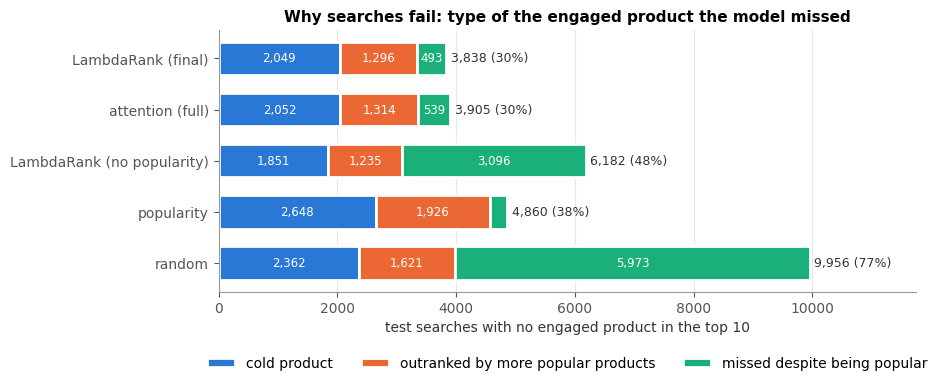

In [ ]:
E['pop_rank'] = E.groupby('session_id')['popularity'].rank(ascending=False, method='min')
best_pop_rank = E[E['label'] > 0].groupby('session_id')['pop_rank'].min().reindex(S.index)   # most popular engaged product
cold_all = S['engaged product popularity'] == 'cold (0)'

fail = first_rank['lr'].reindex(S.index) > 10
print(f'LambdaRank failures (no engaged product in the top 10): {fail.sum():,} of {len(fail):,} searches ({fail.mean():.1%})\n')

profile = pd.DataFrame({
    'every engaged product cold':                 cold_all,
    'engaged product not in 10 most popular':     best_pop_rank > 10,
    'has a repeat product':                       S['repeat product'] == 'yes',
    'new query (not in training)':                S['query frequency'] == '0 (new)',
    'list of 100+ products':                      S['list length'] == '100+',
    'engaged product has no brand':               S['brand'] == 'missing',
    'user has 1–9 past actions':                  S['history length'] == '1–9',
    'no click in last 7 days':                    S['recent clicks'] == 'no click in 7 days',
    'continuing a visit':                         S['visit'] == 'continuing',
    'strongest engagement is a purchase':         S['strongest engagement'] == 'purchase',
})
pt = pd.DataFrame({'among failures': profile[fail].mean(), 'among all searches': profile.mean()})
pt['ratio'] = pt['among failures'] / pt['among all searches']
pt = pt.sort_values('ratio', ascending=False)
print('Property of the search: share among LambdaRank failures vs all searches (ratio > 1 = over-represented)')
print(pt.to_string(formatters={'among failures': '{:.1%}'.format, 'among all searches': '{:.1%}'.format,
                               'ratio': '{:.2f}'.format}))

TYPES = ['cold product', 'outranked by more popular products', 'missed despite being popular']
ftype = pd.Series(np.select([cold_all, best_pop_rank > 10], TYPES[:2], TYPES[2]), index=S.index)
ft = {}
for m in RANK_MODELS:
    f_m = first_rank[m].reindex(S.index) > 10
    ft[MODEL_NAMES[m]] = ftype[f_m].value_counts().reindex(TYPES).fillna(0)
ft = pd.DataFrame(ft).T
ft['failed searches'] = ft.sum(axis=1)
print('\nFailed searches by type and model (counts; share of that model\'s failures in brackets)')
show = ft[TYPES].astype(int).astype(str) + ft[TYPES].div(ft['failed searches'], axis=0).map(lambda v: f' ({v:.0%})')
print(show.join(ft['failed searches'].astype(int)).to_string())

TYPE_COL = {TYPES[0]: COL['blue'], TYPES[1]: COL['orange'], TYPES[2]: COL['aqua']}
order_m = [MODEL_NAMES[m] for m in ['lr', 'att', 'lr_no_pop', 'popularity', 'random']]
fig, ax = plt.subplots(figsize=(9, 3.4))
left = np.zeros(len(order_m))
for t in TYPES:
    v = ft.loc[order_m, t].to_numpy()
    ax.barh(order_m, v, left=left, color=TYPE_COL[t], edgecolor='white', linewidth=2, height=0.65, label=t)
    for y, (l, x) in enumerate(zip(left, v)):
        if x > 450:
            ax.text(l + x / 2, y, f'{int(x):,}', ha='center', va='center', fontsize=8.5, color='white')
    left += v
for y, tot in enumerate(left):
    ax.text(tot + 80, y, f'{int(tot):,} ({tot / len(S):.0%})', va='center', fontsize=9, color=COL['ink'])
ax.invert_yaxis()
ax.set_xlim(0, left.max() * 1.18)
ax.set_xlabel('test searches with no engaged product in the top 10')
ax.set_title('Why searches fail: type of the engaged product the model missed')
ax.grid(axis='y', visible=False)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3)
fig.savefig(FIG / '3_failure_types.png')
plt.show()


**Finding (3.3). LambdaRank fails on products that are cold or less popular than their neighbours, not on particular users.**
- **3,838 searches (29.8%) have no engaged product in LambdaRank's top 10.**
- **Properties of the product drive failures; properties of the user barely do.**
  - The engaged product is **not among the 10 most popular in its list** in 61.1% of failures against 24.6% of all searches (2.5× over-represented).
  - **Every engaged product is cold** in 53.4% of failures against 24.7% overall (2.2×).
  - Missing brand (1.6×) and lists of 100+ products (1.4×) are mildly over-represented.
  - User properties are close to 1: short history 1.1×, no recent click 1.1×, continuing visit 0.95×.
  - **Searches with a repeat product almost never fail**: 0.1% of failures against 14.8% of searches.
- **Failure types for LambdaRank: 53% cold product (2,049), 34% outranked by more popular products (1,296), 13% missed despite being popular (493).** 87% of its failures are about popularity: the product either has none or has less than ten others in the list.
- **Compared with popularity alone** (4,860 failures: 54% / 40% / 6%), LambdaRank has, net, about 600 fewer cold-product failures and 630 fewer "outranked" failures, but about 200 more where the engaged product was popular and the other features pushed it down. **LambdaRank without popularity** fails more often overall (6,182), mostly by missing popular products (3,096), yet has the fewest cold-product failures (1,851), consistent with Section 2.3: popularity helps on popular products and hurts on cold ones.

### 3.4 In a failed search, what does the model put in the top 10 instead?
For every search LambdaRank fails, it describes the 10 products the model ranked first and compares them with **all the products shown but ignored in the same searches** (what a random top 10 would look like). For each top-10 product it checks whether it:
- is **more popular** than the most popular engaged product in that search;
- is **cold** (no training user acted on it);
- is in the **same leaf category**, from the **same shop**, or of the **same brand** as an engaged product;
- is a **repeat product the user ignored** this time (the user acted on it before, but not in this search).

This separates two kinds of miss. If the top 10 is full of products from the engaged product's own category, shop or brand, the model read the user's intent correctly and picked the wrong item among close substitutes, a **near miss**. If the top 10 is mostly more popular products from elsewhere, popularity pulled the ranking **away** from what the user wanted.

The engaged products' categories, shops and brands come from the product lookup (step 3b). A missing brand or shop (−1) never counts as a match.

The output in each row: the share among LambdaRank's top 10 in failed searches, the share among all ignored products in those searches, and their ratio. A ratio far above 1 means the model actively picks that kind of product.


In [17]:
brand = pd.read_parquet(FILES['lookup'], columns=['wid', 'brand_id']).set_index('wid')['brand_id']
E['brand'] = E['wid'].map(brand).fillna(-1).astype('int64')
del brand

fail_ids = fail[fail].index
F = E[E['session_id'].isin(fail_ids)][['session_id', 'wid', 'label', 'popularity', 'cold', 'prod_seen_before',
                                       'cate4', 'shop', 'brand']].copy()
F['rank_lr'] = R.loc[F.index, 'lr'].to_numpy()                 # E, R and P share the row index
engF = F[F['label'] > 0]
F['more popular than engaged'] = F['popularity'] > F['session_id'].map(engF.groupby('session_id')['popularity'].max())
for key, name in [('cate4', 'same leaf category as engaged'), ('shop', 'same shop as engaged'),
                  ('brand', 'same brand as engaged')]:
    pairs = engF.loc[engF[key] != -1, ['session_id', key]].drop_duplicates().assign(_hit=True)
    F[name] = F[['session_id', key]].merge(pairs, on=['session_id', key], how='left')['_hit'].notna().to_numpy()
F['ignored repeat product'] = (F['prod_seen_before'] == 1) & (F['label'] == 0)

cols = ['more popular than engaged', 'cold', 'same leaf category as engaged', 'same shop as engaged',
        'same brand as engaged', 'ignored repeat product']
top10 = F[F['rank_lr'] <= 10]
ignored = F[F['label'] == 0]
t = pd.DataFrame({'LambdaRank top 10': top10[cols].mean(), 'all ignored products in these searches': ignored[cols].mean()})
t['ratio'] = t.iloc[:, 0] / t.iloc[:, 1]
print(f'{len(fail_ids):,} failed searches, {len(top10):,} top-10 products, {len(ignored):,} ignored products\n')
print(t.to_string(formatters={t.columns[0]: '{:.1%}'.format, t.columns[1]: '{:.1%}'.format, 'ratio': '{:.2f}'.format}))

near = top10.groupby('session_id')['same leaf category as engaged'].mean()
print(f'\nfailed searches where at least half of the top 10 shares the engaged product\'s leaf category: {(near >= 0.5).mean():.1%}')
print(f'failed searches where none of the top 10 does:                                              {(near == 0).mean():.1%}')


3,838 failed searches, 38,380 top-10 products, 369,437 ignored products

                              LambdaRank top 10 all ignored products in these searches ratio
more popular than engaged                 71.2%                                  16.5%  4.30
cold                                      21.4%                                  69.4%  0.31
same leaf category as engaged             68.8%                                  65.1%  1.06
same shop as engaged                      12.4%                                   9.1%  1.36
same brand as engaged                     28.2%                                  23.2%  1.22
ignored repeat product                     5.0%                                   0.5%  9.18

failed searches where at least half of the top 10 shares the engaged product's leaf category: 73.2%
failed searches where none of the top 10 does:                                              9.5%


**Finding (3.4). Failures are mostly "right category, more popular product".**
- In failed searches, **71.2% of LambdaRank's top 10 is more popular than the engaged product**, against 16.5% of the ignored products in the same lists (4.3×). Cold products are pushed out: 21.4% of the top 10 against 69.4% of ignored products.
- **The model still reads the intent correctly.** 68.8% of the top-10 products share the engaged product's leaf category, and in **73.2% of failed searches at least half of the top 10 is in that category**; only 9.5% have none. The search engine already narrowed the list to the right kind of product (the interim found the median list is 72% one leaf category), so the miss is about *which* item within the category, and there the model defaults to the more popular ones. Same brand (1.2×) and same shop (1.4×) are only mildly over-represented.
- **A second, smaller failure source: past products the user did not want this time.** 5.0% of the top 10 in failed searches are repeat products the user ignored, against 0.5% of ignored products (9.2×). The repeat-product signal that wins Section 2 also over-promotes old products when the user is looking for something new.
- **Implication.** Most failures are near misses among substitutes, so better within-category differentiation (product-level text, price or attributes, none of which the current features describe beyond category, brand and shop) is where the remaining gain lies, rather than better intent detection.


### 3.5 What are the tied products?
Section 0.5 found that 10.7% of products get exactly the same LambdaRank score as another product in the same list. This step looks at those **tie groups** (products in one search with identical scores) and checks how often all members share the same shop, brand and leaf category, and the same popularity.

If tied products are mostly the same item in different variants (same shop, brand and category, e.g. colours or sizes listed as separate products), the ties are natural: nothing in our features can tell variants apart, and in practice it hardly matters which variant is shown first. If tied products are unrelated, the model is losing information it should have used. Either way, a deployed ranker needs a tie-breaking rule, and this shows what it is choosing between.

In [18]:
tg = E[['session_id', 'label', 'popularity', 'cate4', 'shop', 'brand']].assign(score=P['lr'].to_numpy())
grp = tg.groupby(['session_id', 'score'])
size = grp['label'].transform('size')
tg = tg[size > 1]
g = tg.groupby(['session_id', 'score']).agg(
    n=('label', 'size'), top_label=('label', 'max'),
    shops=('shop', 'nunique'), shop_min=('shop', 'min'), brands=('brand', 'nunique'), brand_min=('brand', 'min'),
    cates=('cate4', 'nunique'), pops=('popularity', 'nunique'))
g['engaged'] = g['top_label'] > 0
g['same shop'] = (g['shops'] == 1) & (g['shop_min'] != -1)
g['same brand'] = (g['brands'] == 1) & (g['brand_min'] != -1)
g['same leaf category'] = g['cates'] == 1
g['same popularity'] = g['pops'] == 1
g['same shop, brand and category'] = g['same shop'] & g['same brand'] & g['same leaf category']
print(f'tie groups: {len(g):,} in {g.index.get_level_values(0).nunique():,} searches; '
      f'products in a tie: {len(tg):,} ({len(tg) / len(E):.1%} of all)')
print('group size:', g['n'].describe(percentiles=[0.5, 0.9])[['50%', '90%', 'max']].to_dict())
cols = ['same leaf category', 'same shop', 'same brand', 'same shop, brand and category', 'same popularity']
t = pd.DataFrame({'all tie groups': g[cols].mean(), 'tie groups with an engaged product': g.loc[g['engaged'], cols].mean()})
print(f"\ntie groups containing an engaged product: {g['engaged'].sum():,}\n")
print(t.map('{:.1%}'.format).to_string())
del tg, grp, size


tie groups: 49,488 in 9,816 searches; products in a tie: 123,257 (10.7% of all)
group size: {'50%': 2.0, '90%': 3.0, 'max': 92.0}

tie groups containing an engaged product: 2,100

                              all tie groups tie groups with an engaged product
same leaf category                    100.0%                             100.0%
same shop                              96.5%                              97.9%
same brand                             92.3%                              93.2%
same shop, brand and category          90.7%                              92.5%
same popularity                       100.0%                             100.0%


**Finding (3.5). Tied products are almost always variants of one product.**
- LambdaRank produces **49,488 tie groups in 9,816 of the 12,880 searches**, covering 123,257 products (10.7%). Most groups are pairs (median 2, 90th percentile 3, largest 92).
- **90.7% of tie groups share the same shop, brand and leaf category**, and all of them share the same leaf category and the same popularity (96.5% same shop, 92.3% same brand). For the 2,100 groups containing an engaged product the figure is 92.5%.
- These are very likely **variants of one product** (e.g. colours or sizes listed as separate products): nothing in the 49 features differs between them, so the model cannot separate them. The catalogue has no product name similarity or price in our features to confirm this directly.
- **Implication.** Ties are not a modelling error, but a deployed ranker needs an explicit rule for them (for example, JD's own order or the cheapest variant). Which variant the user picks is a separate decision the model does not make, and evaluation must keep breaking ties at random (Section 0.4).


## 4. Inside the models: what has each model learned?
Sections 2 and 3 described *where* the models succeed and fail from the outside. This section looks within the models, 
- **LambdaRank** is the final model, so it gets most of the space (4.1–4.3). We use **SHAP values**: for every product, how much each of the 49 features pushed its score up or down.
- **The attention model** (4.4) is read through its **attention weights**: which past actions it looks at when scoring a product.

### 4.1 Rebuild LambdaRank's inputs and compute SHAP values
**What this step does.**
1. Rebuilds the 49 input features for every test product exactly as step 3a did (same files, same `qi__ / hc__ / hg__ / pop__` names, same 32-bit floats, missing values left missing), in the order stored in the model file.
2. **Checks the rebuild**: the saved model (`lambdarank_final_pop.txt`) re-scores the test products, and the result must equal step 3a's saved scores. If it does, our inputs are exactly the model's inputs.
3. Computes SHAP values for a random sample of **500 test searches** (about 45,000 products) in the next cell.

**SHAP values** For one product, the model's score can be split into a fixed starting value plus one contribution per feature; the contributions add up exactly to the score. A contribution of +0.8 for popularity means "this product's popularity raised its score by 0.8 compared with an average product". LightGBM computes these exactly for tree models (`pred_contrib=True`), so no approximation is involved.

We take a sample reason being that the exact SHAP for a model of 495 trees costs far more than scoring: on a free Colab runtime it handles a few hundred products per second, so all 1.15 million products would take hours. 500 searches (about 45,000 products, roughly 900 of them engaged) is enough for stable averages, and the SHAP cell is cached to Drive so it only runs once.




In [ ]:
import time
t0 = time.time()
try:
    import lightgbm as lgb
except ImportError:                                       # Colab normally has it; install if not
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'lightgbm'], check=True)
    import lightgbm as lgb

# rebuild the 49 inputs for the test products (same files and names as step 3a)
def prefixed(d, prefix):
    return d.rename(columns={c: prefix + c for c in d.columns if c not in ('session_id', 'wid')})

qi = pd.read_parquet(FILES['query_item']).rename(columns={'candidate_id': 'wid'})
qi = prefixed(qi.drop(columns=['candidate_pos', 'split', 'label']), 'qi__')
hc = pd.read_parquet(FILES['hist_cand'], filters=[('session_id', 'in', T)]).drop(columns=['label', 'split'])
hg = pd.read_parquet(FILES['hist_group'], filters=[('session_id', 'in', T)])
pop = pd.read_parquet(FILES['popularity'], filters=[('session_id', 'in', T)])

X = P[['session_id', 'wid']].copy()
for d, prefix in [(qi, None), (hc, 'hc__'), (hg, 'hg__'), (pop, 'pop__')]:
    X = X.merge(d if prefix is None else prefixed(d, prefix), on=['session_id', 'wid'], how='left', validate='one_to_one')
del qi, hc, hg, pop
print(f'inputs rebuilt in {time.time() - t0:.0f}s')
assert len(X) == len(P) and (X['wid'].to_numpy() == P['wid'].to_numpy()).all()
missing_cols = [f for f in LR_FEATURES if f not in X.columns]
assert not missing_cols, missing_cols
XF = X[LR_FEATURES].astype('float32')                     # exactly the model's input matrix

booster = lgb.Booster(model_file=str(FILES['lr_model']))
t1 = time.time()
rescore = booster.predict(XF)
print(f're-scored {len(XF):,} products in {time.time() - t1:.0f}s')
diff = np.abs(rescore - P['lr'].to_numpy())
print(f'rebuild check: largest |our re-score - step 3a score| = {diff.max():.2e} over {len(XF):,} products')
assert diff.max() < 1e-4, 'inputs do not reproduce the saved scores'


inputs rebuilt in 18s
re-scored 1,147,673 products in 49s
rebuild check: largest |our re-score - step 3a score| = 0.00e+00 over 1,147,673 products


### 4.1b SHAP values for a sample of searches
We draw 500 test searches at random (seed 42) and computes the exact SHAP values of every product in them with LightGBM's `pred_contrib=True` and cache them to avoid lengthy recomputation times. It first times 2,000 products and prints a projected total, then runs the rest.

In [20]:
N_SHAP = 500
SHAP_CACHE = OUT / f'shap_sample_{N_SHAP}.parquet'
shap_sessions = np.sort(np.random.default_rng(SEED).choice(TEST_SESSIONS, N_SHAP, replace=False))
rows = np.flatnonzero(P['session_id'].isin(shap_sessions).to_numpy())

if SHAP_CACHE.exists():
    cached = pd.read_parquet(SHAP_CACHE)
    assert len(cached) == len(rows) and (cached['row'].to_numpy() == rows).all(), 'cache is for a different sample'
    contrib = cached.drop(columns='row').to_numpy()
    print(f'SHAP values loaded from cache: {SHAP_CACHE.name}')
else:
    t1 = time.time()
    booster.predict(XF.iloc[rows[:2000]], pred_contrib=True)
    rate = 2000 / (time.time() - t1)
    print(f'speed: about {rate:,.0f} products per second -> about {len(rows) / rate / 60:.1f} min for {len(rows):,} products')
    t1 = time.time()
    contrib = booster.predict(XF.iloc[rows], pred_contrib=True)          # last column = starting value
    print(f'done in {(time.time() - t1) / 60:.1f} min')
    pd.DataFrame(contrib, columns=LR_FEATURES + ['start_value']).assign(row=rows).to_parquet(SHAP_CACHE, index=False)

SH = pd.DataFrame(contrib[:, :-1], columns=LR_FEATURES)
SH_sess = P['session_id'].to_numpy()[rows]
assert np.allclose(contrib.sum(axis=1), P['lr'].to_numpy()[rows], atol=1e-4), 'SHAP values do not add up to the scores'
GROUP_OF = {'qi': 'query & product', 'hc': 'exact-product history', 'hg': 'brand/shop/category history', 'pop': 'popularity'}
FEAT_GROUP = pd.Series({f: GROUP_OF[f.split('__')[0]] for f in LR_FEATURES})
print(f'SHAP values: {len(rows):,} products in {N_SHAP:,} searches; contributions add up to the scores')


SHAP values loaded from cache: shap_sample_500.parquet
SHAP values: 42,791 products in 500 searches; contributions add up to the scores


### 4.2 Which features move the ranking?
**How we measured importance.**
- **Mean |SHAP|**: how much a feature moves a product's score on average. This is the usual SHAP importance.
- **Within-list spread**: the standard deviation of a feature's SHAP values *inside each search*, averaged over searches. A ranking only depends on how scores differ **between products in the same list**. A feature that raises every product in a list by the same amount moves the scores but reorders nothing. The within-list spread measures what actually reorders the list, so it is the more relevant measure here.
- **Gain importance** (step 3a's `feature_importance_lambdarank.csv`) measures how much each feature improved the training loss when the trees were built. It is computed on training data and says nothing about direction; SHAP is computed on test products.


Share of each feature group

                            mean |SHAP| within-list spread   gain
group                                                            
popularity                        50.7%              54.8%  60.3%
query & product                   29.7%              25.6%  13.1%
brand/shop/category history       17.5%              12.9%   6.2%
exact-product history              2.0%               6.7%  20.4%

Top 15 features by within-list spread of SHAP

                                               group within-list spread mean |SHAP|  spread rank  gain rank
pop__pop_product_users                    popularity              0.390       0.410            1          1
pop__pop_product_cart                     popularity              0.148       0.144            2          2
qi__shop_product_count               query & product              0.147       0.136            3         10
pop__pop_product_click                    popularity              0.129       0.125            

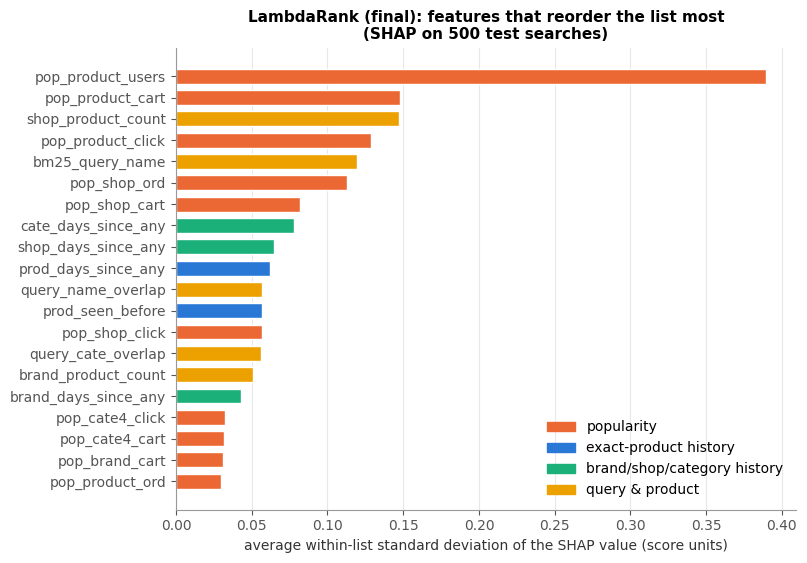

In [21]:
abs_mean = SH.abs().mean()
spread = SH.groupby(SH_sess).std().mean()                 # within-search standard deviation, averaged
imp = pd.read_csv(FILES['lr_importance'])
gain = imp.set_index('feature')['gain'].reindex(LR_FEATURES).fillna(0)

feat = pd.DataFrame({'group': FEAT_GROUP, 'mean |SHAP|': abs_mean, 'within-list spread': spread, 'gain': gain})
grp = feat.groupby('group')[['mean |SHAP|', 'within-list spread', 'gain']].sum()
grp = grp / grp.sum()
print('Share of each feature group\n')
print(grp.sort_values('within-list spread', ascending=False).map('{:.1%}'.format).to_string())

feat['spread rank'] = feat['within-list spread'].rank(ascending=False).astype(int)
feat['gain rank'] = feat['gain'].rank(ascending=False).astype(int)
top = feat.sort_values('within-list spread', ascending=False)
print('\nTop 15 features by within-list spread of SHAP\n')
print(top.head(15)[['group', 'within-list spread', 'mean |SHAP|', 'spread rank', 'gain rank']].to_string(
    formatters={'within-list spread': '{:.3f}'.format, 'mean |SHAP|': '{:.3f}'.format}))

GROUP_COL = {'popularity': COL['orange'], 'exact-product history': COL['blue'],
             'brand/shop/category history': COL['aqua'], 'query & product': COL['yellow']}
t20 = top.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh([f.split('__', 1)[1] for f in t20.index], t20['within-list spread'],
        color=[GROUP_COL[g] for g in t20['group']], height=0.7, edgecolor='white', linewidth=1)
ax.set_xlabel('average within-list standard deviation of the SHAP value (score units)')
ax.set_title(f'LambdaRank (final): features that reorder the list most\n(SHAP on {N_SHAP:,} test searches)')
ax.grid(axis='y', visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=g) for g, c in GROUP_COL.items()], loc='lower right')
fig.savefig(FIG / '4_shap_importance.png')
plt.show()


**Finding (4.2). Popularity reorders the list more than everything else combined; exact-product history matters a lot for a few products.**

| Feature group | mean \|SHAP\| | within-list spread | gain (step 3a) |
|---|---|---|---|
| popularity (13) | 50.7% | **54.8%** | 60.3% |
| query & product (12) | 29.7% | 25.6% | 13.1% |
| brand/shop/category history (15) | 17.5% | 12.9% | 6.2% |
| exact-product history (9) | 2.0% | 6.7% | 20.4% |

- **Popularity accounts for 55% of what reorders a list**, and the top feature by far is `pop_product_users` (within-list spread 0.39, more than twice the next feature). Four of the top seven features are popularity counts.
- **The three measures disagree in an informative way.**
  - **Exact-product history** has 20% of the gain but only 2% of mean |SHAP|. It matters hugely for the 0.8% of products the user touched before and not at all for the rest. Gain importance, computed during training, reflects how decisive a feature is when it applies; SHAP averages over all products. Both are right; they answer different questions.
  - **Brand/shop/category history** has more SHAP weight (13–18%) than gain (6%): it nudges many products a little.
  - Some features mostly **shift whole lists** rather than reorder them: `cate_days_since_any` (mean |SHAP| 0.165, within-list spread 0.078) and `query_cate_overlap` (0.122 vs 0.056). Search results lists are usually concentrated in one category, so most products in a list share the same category history and the same category match. They change the score level of the whole list, which does not change the ranking.
- **`shop_product_count` (the number of products the shop lists in the catalogue) is the third-strongest feature.** It acts as a proxy for large shops, another popularity-like signal. **BM25** ranks fifth inside the model, even though BM25 alone barely beats random (Section 1): it helps separate products once popularity has done the coarse ordering.

### 4.3 How the model treats cold products, repeat products and popularity
**(a) Dependence plots**: for four key features, each product's SHAP value against the feature's value:
- `pop_product_users` (training users who touched the product), the main popularity feature. The point at 0 is every cold product.
- `prod_days_since_any` (days since the user last touched this exact product), for repeat products only.
- `shop_days_since_any` (days since the user last touched a product from this shop; 365 means never).
- `bm25_query_name` (text match between query and product name).

**(b) The push on engaged products by type.** For every engaged product in the sample, the SHAP contribution of each feature group **relative to the average product in the same list** (its contribution minus the list mean), split into three types: **repeat products**, **cold products** (not repeat) and **other warm products**. A positive value means that feature group lifts the engaged product above its neighbours; negative means it pushes it down.

Section 2 found that popularity lowers NDCG when the engaged product is cold and that repeat products are where the model wins. If that is how the model works, the SHAP values should show popularity pushing cold engaged products down and exact-product history lifting repeat products up. Which is what we are trying to test for here.




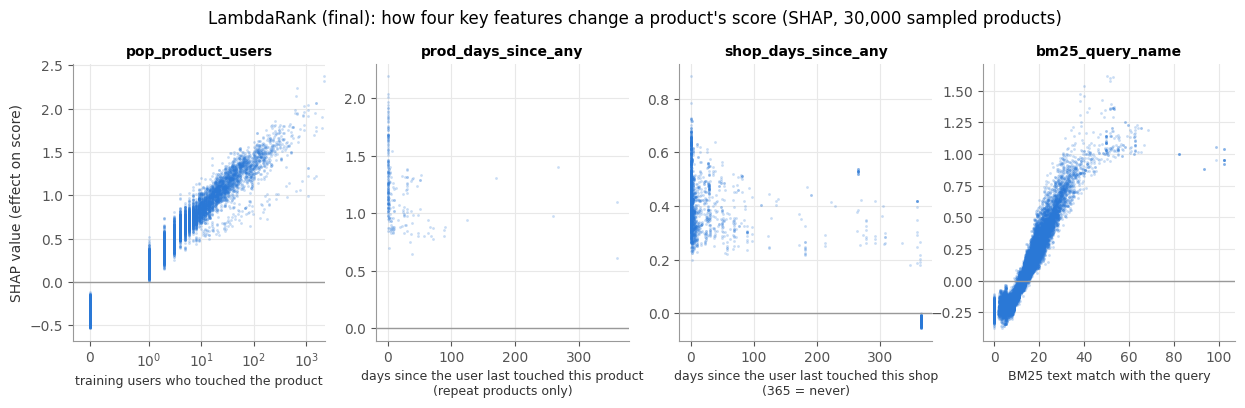

Popularity feature: average SHAP of pop_product_users by its value
                          products  mean SHAP
v_pop__pop_product_users                     
0 (cold)                     28674     -0.314
1–9                          10146      0.403
10–99                         3379      1.060
100+                           592      1.499

Engaged products: SHAP push of each feature group relative to the list average (score units)

                    engaged products  brand/shop/category history  exact-product history  popularity  query & product  total
repeat product                    75                        0.709                  2.647       0.730            0.113  4.199
other warm product               519                        0.094                 -0.029       1.517            0.106  1.687
cold product                     312                        0.058                 -0.015      -0.155            0.079 -0.034


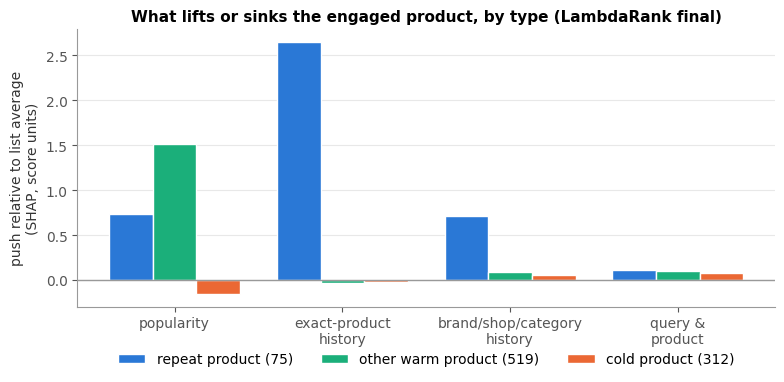

In [ ]:
samp = pd.DataFrame({'session_id': SH_sess, 'label': P['label'].to_numpy()[rows]})
samp['cold'] = E['cold'].to_numpy()[rows]
samp['repeat'] = E['prod_seen_before'].to_numpy()[rows] == 1
for f in ['pop__pop_product_users', 'hc__prod_days_since_any', 'hg__shop_days_since_any', 'qi__bm25_query_name']:
    samp['v_' + f] = XF[f].to_numpy()[rows]
    samp['s_' + f] = SH[f].to_numpy()

# dependence plots 
pick = np.random.default_rng(SEED).choice(len(samp), min(30000, len(samp)), replace=False)
sp = samp.iloc[pick]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
specs = [('pop__pop_product_users', 'training users who touched the product', sp, 'symlog'),
         ('hc__prod_days_since_any', 'days since the user last touched this product\n(repeat products only)', sp[sp['repeat']], 'linear'),
         ('hg__shop_days_since_any', 'days since the user last touched this shop\n(365 = never)', sp, 'linear'),
         ('qi__bm25_query_name', 'BM25 text match with the query', sp, 'linear')]
for ax, (f, xlabel, d, scale) in zip(axes, specs):
    ax.scatter(d['v_' + f], d['s_' + f], s=4, alpha=0.25, color=COL['blue'], lw=0)
    ax.axhline(0, color='#999999', lw=1)
    if scale == 'symlog':
        ax.set_xscale('symlog', linthresh=1)
        ax.set_xlim(-0.3, None)
    ax.set_xlabel(xlabel, fontsize=9)
    ax.set_title(f.split('__', 1)[1], fontsize=10)
axes[0].set_ylabel('SHAP value (effect on score)')
fig.suptitle('LambdaRank (final): how four key features change a product\'s score (SHAP, 30,000 sampled products)', y=1.03)
fig.savefig(FIG / '4_shap_dependence.png')
plt.show()

pu = samp['v_pop__pop_product_users']
print('Popularity feature: average SHAP of pop_product_users by its value')
print(samp.groupby(pd.cut(pu, [-0.5, 0.5, 9.5, 99.5, np.inf], labels=['0 (cold)', '1–9', '10–99', '100+']), observed=True)
      ['s_pop__pop_product_users'].agg(['size', 'mean']).rename(columns={'size': 'products', 'mean': 'mean SHAP'}).round(3).to_string())

# push on engaged products, relative to their list
grp_sh = SH.T.groupby(FEAT_GROUP).sum().T                           # products x groups
rel = grp_sh - grp_sh.groupby(SH_sess).transform('mean').to_numpy() # relative to the list average
rel['total'] = rel.sum(axis=1)
eng_mask = (samp['label'] > 0).to_numpy()
etype = np.select([samp['repeat'], samp['cold']], ['repeat product', 'cold product'], 'other warm product')
push = rel[eng_mask].groupby(etype[eng_mask]).mean().reindex(['repeat product', 'other warm product', 'cold product'])
push.insert(0, 'engaged products', pd.Series(etype[eng_mask]).value_counts())
print('\nEngaged products: SHAP push of each feature group relative to the list average (score units)\n')
print(push.round(3).to_string())

groups = ['popularity', 'exact-product history', 'brand/shop/category history', 'query & product']
fig, ax = plt.subplots(figsize=(9, 3.6))
w = 0.26
for i, (typ, c) in enumerate([('repeat product', COL['blue']), ('other warm product', COL['aqua']), ('cold product', COL['orange'])]):
    ax.bar(np.arange(len(groups)) + (i - 1) * w, push.loc[typ, groups], width=w, color=c,
           label=f'{typ} ({int(push.loc[typ, "engaged products"]):,})', edgecolor='white', linewidth=1)
ax.axhline(0, color='#999999', lw=1)
ax.set_xticks(np.arange(len(groups)), ['popularity', 'exact-product\nhistory', 'brand/shop/category\nhistory', 'query &\nproduct'])
ax.set_ylabel('push relative to list average\n(SHAP, score units)')
ax.set_title('What lifts or sinks the engaged product, by type (LambdaRank final)')
ax.grid(axis='x', visible=False)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3)
fig.savefig(FIG / '4_shap_push_engaged.png')
plt.show()


**Finding (4.3). The model treats "no data" as "unpopular", and nothing lifts cold products above their neighbours.**
- **Popularity dependence.** `pop_product_users` raises a product's score steadily with the log of the number of training users who touched it: average SHAP **−0.31 for cold products** (0 users; 67% of all products), +0.40 for 1–9 users, +1.06 for 10–99 and +1.50 for 100+. A single training user's touch is worth about +0.7, so the model reads "no data" as strongly negative.
- **Repeat products** (exact-product history) get a large lift, +0.8 to +2.2, largest when the user touched the product within the last day. **Shop history** gives +0.2 to +0.7 to products from a shop the user acted on, more when recent, and about 0 otherwise. **BM25** has a steady, roughly linear positive effect.
- **The push on engaged products, relative to their list:**

| Engaged product | n | popularity | exact-product history | brand/shop/category history | query & product | **total** |
|---|---|---|---|---|---|---|
| repeat product | 75 | +0.73 | **+2.65** | +0.71 | +0.11 | **+4.20** |
| other warm product | 519 | **+1.52** | −0.03 | +0.09 | +0.11 | **+1.69** |
| cold product | 312 | **−0.16** | −0.02 | +0.06 | +0.08 | **−0.03** |

- **This is the mechanism behind Sections 2 and 3.** Repeat products are lifted far above their list, mainly by exact-product history. Other warm products are lifted mainly by popularity. **Cold engaged products end up at the list average (−0.03)**: popularity pushes them down a little, and the brand, shop, category and query features push them up by about the same small amount. With about 90 products per list, "average" means around rank 45, far outside the top 10. Nothing in the model separates a wanted cold product from the unwanted cold products around it.
- **Caution.** These are averages over the 500-search sample; the repeat-product row rests on 75 products, so its exact size is uncertain, though its direction matches Section 2.3 (+0.398 NDCG@10 over popularity for repeat-product searches).


### 4.4 The attention model: what do its weights show, and why does the history branch add nothing?
Step 3b saved, for every test product, how the attention model spread its weight over the user's past actions (`step3b_attention_summary.parquet`). We examine three main questions:
1. **Does the model "give up" on short histories?** The attention model has a **null slot**: a learned "nothing relevant here" option it can put weight on instead of any past action. We compare the null weight across history lengths, and between engaged and ignored products.
2. **Is the attention just counting matches?** For each product, the attention on past actions from the **same leaf category, brand or shop** is compared with the **share** of such actions in the history (what equal weighting would give). If attention is close to a fixed multiple of the share, it carries little information beyond a count of matching past actions, and step 1a's brand/shop/category features (which LambdaRank and the attention model both receive) already hold those counts. That would explain why the history branch adds nothing measurable (step 3b: +0.0001 on validation).
3. **Does focused attention go with a larger gain from history?** Per search, the gain from the history branch (attention full − attention without history, seed 42) is compared across how much attention the engaged product put on same-category past actions. About half of the searches put no attention at all on same-category actions (often there are none in the history); they form one group, and the rest are split into three equal groups (low, middle, high).

For question 2 we report R²: the share of the variation in attention explained by (i) the history share alone and (ii) the history share plus the five matching group features for that attribute (clicks, carts, orders, days since any action, days since last order). R² near 1 means attention adds almost nothing beyond those counts.




attention summary joined: 1,147,673 products; score column agrees with the seed-42 test scores: 1.0000 correlation

1. Average weight on the null slot ("nothing relevant"), by history length

engaged        engaged ignored
history length                
1–9              71.1%   70.4%
10–49            37.7%   38.3%
50–199           19.5%   19.8%
200+             14.5%   14.6%
cold vs warm candidates: 28.7% vs 28.7%

2. Attention on matching past actions vs their share of the history
           attention / share  R² share only  R² share + group features
attribute                                                             
cate4                  1.441          0.523                      0.651
brand                  1.388          0.523                      0.635
shop                   1.434          0.453                      0.562

3. Gain from the history branch (attention full − no history, NDCG@10) by how much attention the engaged
   product put on same-leaf-category past actions

 

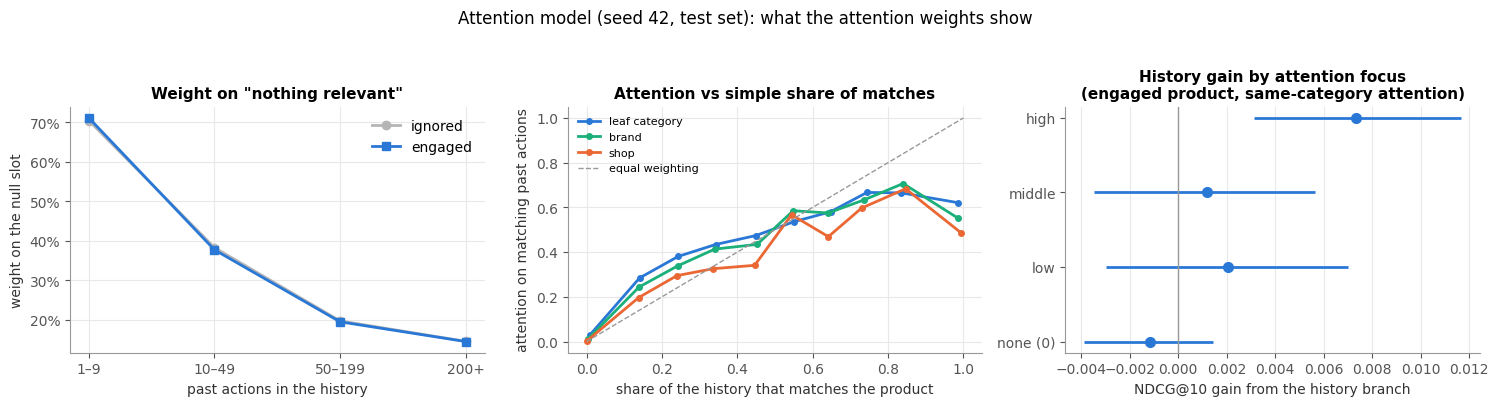

In [ ]:
A = pd.read_parquet(FILES['att_summary'])
A = P[['session_id', 'wid', 'label', 'att']].merge(A.drop(columns=['label', 'candidate_pos']), on=['session_id', 'wid'],
                                                  how='left', validate='one_to_one')
assert A['attn_null'].notna().all()
print(f"attention summary joined: {len(A):,} products; score column agrees with the seed-42 test scores: "
      f"{np.corrcoef(A['score'], A['att'])[0, 1]:.4f} correlation")
A['history length'] = pd.Categorical(S['history length'].reindex(A['session_id']).to_numpy(),
                                     categories=S['history length'].cat.categories, ordered=True)
A['engaged'] = np.where(A['label'] > 0, 'engaged', 'ignored')
A['cold'] = E['cold'].to_numpy()

# 1. null slot 
null_t = A.pivot_table(index='history length', columns='engaged', values='attn_null', aggfunc='mean', observed=True)
print('\n1. Average weight on the null slot ("nothing relevant"), by history length\n')
print(null_t.map('{:.1%}'.format).to_string())
print('cold vs warm candidates: %.1f%% vs %.1f%%' % tuple(100 * A.groupby('cold')['attn_null'].mean().reindex([True, False])))

# 2. attention vs share of matching history 
ATTRS = {'cate4': 'cate', 'brand': 'brand', 'shop': 'shop'}
smp = A.sample(min(300_000, len(A)), random_state=SEED)
Xg = X.loc[smp.index]                                             # A, X and P share the row index
print('\n2. Attention on matching past actions vs their share of the history')
rows_r2 = []
for attr, hgp in ATTRS.items():
    y = smp[f'attn_same_{attr}'].to_numpy()
    sh = smp[f'share_same_{attr}'].to_numpy()
    feats = np.column_stack([sh] + [np.log1p(Xg[f'hg__{hgp}_n_{k}'].to_numpy(dtype='float64')) for k in ['click', 'cart', 'order']]
                            + [Xg[f'hg__{hgp}_days_since_any'].to_numpy(dtype='float64') / 365,
                               Xg[f'hg__{hgp}_days_since_order'].to_numpy(dtype='float64') / 365])
    def r2(M):
        M = np.column_stack([np.ones(len(M)), M])
        resid = y - M @ np.linalg.lstsq(M, y, rcond=None)[0]
        return 1 - resid.var() / y.var()
    rows_r2.append({'attribute': attr, 'attention / share': y.mean() / sh.mean(),
                    'R² share only': r2(sh[:, None]), 'R² share + group features': r2(feats)})
print(pd.DataFrame(rows_r2).set_index('attribute').round(3).to_string())

# 3. history gain by attention focus 
gain_h = (nd['att'] - nd['att_no_hist'])
focus = A[A['label'] > 0].groupby('session_id')['attn_same_cate4'].max().reindex(gain_h.index)
# about half of the searches put no attention at all on same-category actions: keep them as one group,
# and split the rest into three equal groups
pos = focus > 1e-6
fq = pd.Series('none (0)', index=focus.index)
fq[pos] = pd.qcut(focus[pos].rank(method='first'), 3, labels=['low', 'middle', 'high']).astype(str)
fq = pd.Categorical(fq, ['none (0)', 'low', 'middle', 'high'], ordered=True)
fq = pd.Series(fq, index=focus.index)
rng_a = np.random.default_rng(SEED)
g3 = []
for lvl in fq.cat.categories:
    x = gain_h[fq == lvl].to_numpy()
    lo, hi = ci_mean(x, rng_a)
    g3.append({'attention focus': lvl, 'searches': len(x), 'focus range': f'{focus[fq == lvl].min():.2f}–{focus[fq == lvl].max():.2f}',
               'history gain': x.mean(), 'lo': lo, 'hi': hi})
g3 = pd.DataFrame(g3).set_index('attention focus')
print('\n3. Gain from the history branch (attention full − no history, NDCG@10) by how much attention the engaged\n'
      '   product put on same-leaf-category past actions\n')
print(g3.round(4).to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
ax = axes[0]
x = np.arange(len(null_t))
for col, c, mk in [('ignored', COL['grey'], 'o'), ('engaged', COL['blue'], 's')]:
    ax.plot(x, null_t[col], marker=mk, color=c, lw=2, label=col)
ax.set_xticks(x, null_t.index)
ax.set_xlabel('past actions in the history')
ax.set_ylabel('weight on the null slot')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_title('Weight on "nothing relevant"')
ax.legend()
ax = axes[1]
bins = np.linspace(0, 1, 11)
for attr, c in [('cate4', COL['blue']), ('brand', COL['aqua']), ('shop', COL['orange'])]:
    b = pd.cut(A[f'share_same_{attr}'], bins, include_lowest=True)
    m = A.groupby(b, observed=True)[[f'share_same_{attr}', f'attn_same_{attr}']].mean()
    ax.plot(m.iloc[:, 0], m.iloc[:, 1], marker='o', ms=4, color=c, lw=2, label=attr if attr != 'cate4' else 'leaf category')
ax.plot([0, 1], [0, 1], ls='--', color='#999999', lw=1, label='equal weighting')
ax.set_xlabel('share of the history that matches the product')
ax.set_ylabel('attention on matching past actions')
ax.set_title('Attention vs simple share of matches')
ax.legend(fontsize=8)
ax = axes[2]
y3 = np.arange(len(g3))
ax.errorbar(g3['history gain'], y3, xerr=[g3['history gain'] - g3['lo'], g3['hi'] - g3['history gain']],
            fmt='o', color=COL['blue'], ecolor=COL['blue'], elinewidth=2, capsize=0, ms=7)
ax.axvline(0, color='#999999', lw=1)
ax.set_yticks(y3, g3.index)
ax.set_xlabel('NDCG@10 gain from the history branch')
ax.set_title('History gain by attention focus\n(engaged product, same-category attention)')
ax.grid(axis='y', visible=False)
fig.suptitle('Attention model (seed 42, test set): what the attention weights show', y=1.03)
fig.tight_layout()
fig.savefig(FIG / '4_attention.png')
plt.show()


**Finding (4.4). The attention weights are sensible but add little the dense features do not already carry.**
- **The null slot tracks how much history the user has, not which product is being scored.** It takes **71%** of the weight for users with 1–9 past actions, 38% for 10–49, 20% for 50–199 and 15% for 200+. It is the same for engaged and ignored products (71.1% vs 70.4% for short histories) and for cold and warm products (28.7% both). So the model uses "nothing relevant" as a per-user setting and never to tell products in a list apart. This explains step 3b's ablation result that candidate-independent attention does as well as the full model.
- **Attention favours matching past actions** (same leaf category, brand or shop) at about **1.4× their share** of the history, more strongly when matches are rare, and levels off around 0.6–0.7 when most of the history matches. **The share alone explains 45–52% of the variation in this attention, and the share plus the five matching brand/shop/category features 56–65%.** Attention is therefore not just a count, but much of it is predictable from counts that LambdaRank and the attention model's own dense inputs already contain.
- **The history branch helps only when attention is strongly focused.** In the 55% of searches where the engaged product puts no attention on same-category past actions (7,044 searches), and in the low and middle groups, the gain from the history branch is indistinguishable from zero. **In the 15% with the highest focus (attention ≥ 0.32 on same-category actions, 1,946 searches) it is +0.0073 [+0.0031, +0.0117] NDCG@10.**
- **Caution on that last result.** It is one seed (42), on the test set (which step 3b already used for exploration), and one of four groups compared, so it is a lead rather than a finding. Step 3b found no history gain on validation overall (+0.0001 [−0.0008, +0.0010]).
- **Implication.** The attention model reads the history sensibly but mostly re-derives what the brand/shop/category and exact-product features already give it. To add value it would need information those features lack (for example product text or the order of past actions), or it should be applied only where the user has rich history in the searched category.

## 5. Robustness: can we trust the headline numbers?
The team's differentiator is rigour, so before turning results into business insights we test the three things most likely to make them wrong:
1. **Popularity timing (5.1).** Popularity is the largest single input (+0.12 NDCG@10 in both models). Does part of it come from information the model could not have had at search time?
2. **The 1-second searches (5.2).** The interim report found that 4.6% of searches have their last past action exactly 1 second before the search, a sign the search's own clicks may have been logged into history. Do they distort the results?
3. **Randomness (5.3).** Do the results hold for other tie-breaking draws and other training seeds?

### 5.1 Does popularity use information from after the search?
**The concern.** Every test search happened on the same day, 17 Oct 2022 (each user's last search that day; dataset paper, §3.1). Popularity counts how many **training** users acted on a product, using their full histories. A training user's history runs up to *their own* last search on 17 Oct, which may be **later in the day** than a test user's search. So the popularity of a product seen by a test user can include clicks and orders made by other users **after** that test search. In production, a popularity count can only use the past.

**The test.** Every action more than 24 hours before its own user's last search happened before 17 Oct 00:00, so before **every** test search. We rebuild all 13 popularity features twice from the training users' history (`history_long.parquet`), following step 3b's recipe exactly (training users only, actions ≤1 s before a search dropped, clicks / carts / orders counted per product, brand, leaf category and shop, and distinct users per product):
- **A. as in step 3b**: all actions. This must reproduce step 3b's popularity file; it checks that our rebuild is the same recipe.
- **B. strictly before the test day**: only actions more than 24 hours old.

Then we compare test NDCG@10 using A and B:
- **popularity alone** (`pop_product_users` from A vs B);
- **LambdaRank (final), re-scored** with its 13 popularity inputs replaced by version B, everything else unchanged. The model was trained on version-A counts, so this measures what happens if, at serving time, popularity only included data up to the day before, as a nightly batch job would provide.

The share of training actions from the last 24 hours, the check that version A reproduces step 3b's features, then NDCG@10 under A and B with the paired difference and its 95% interval. **A small difference means the popularity signal is genuine past information. A large drop means part of the reported gain depends on same-day activity** and should be reported as such.


In [ ]:
import time
t0 = time.time()
split_all = pd.read_parquet(FILES['user_subset'], columns=['split'])['split'].to_numpy()   # row number = session_id
hl = pd.read_parquet(FILES['hist_long'], columns=['session_id', 'wid', 'type', 'age_sec'])
hl = hl[(split_all[hl['session_id'].to_numpy()] == 'train') & (hl['age_sec'] > 1)].reset_index(drop=True)
hl['type'] = hl['type'].astype(str)
lk = pd.read_parquet(FILES['lookup'], columns=['wid', 'brand_id', 'cate_id_4', 'shop_id'])
lk_w = lk['wid'].to_numpy()
pos = np.searchsorted(lk_w, hl['wid'].to_numpy())
assert (lk_w[pos] == hl['wid'].to_numpy()).all(), 'history product missing from lookup'
for c in ['brand_id', 'cate_id_4', 'shop_id']:
    hl[c] = lk[c].to_numpy()[pos]
del lk, lk_w, pos
print(f'training actions used: {len(hl):,} (loaded in {time.time() - t0:.0f}s)')
recent = hl['age_sec'] <= 86400
print('share from the last 24 hours before the user\'s search: %.1f%% overall; by type: %s'
      % (100 * recent.mean(), {t: f'{100 * v:.1f}%' for t, v in recent.groupby(hl['type']).mean().items()}))

# candidate keys, same missing-value rule as step 3b (-1 never counts)
CAND_KEY = {'wid': P['wid'], 'brand_id': E['brand'], 'cate_id_4': E['cate4'], 'shop_id': E['shop']}
NAME = {'wid': 'product', 'brand_id': 'brand', 'cate_id_4': 'cate4', 'shop_id': 'shop'}

def popularity_features(h):
    out = pd.DataFrame(index=P.index)
    for key, name in NAME.items():
        hh = h[(h[key] != -1) & h['type'].isin(['CLICK', 'CART', 'ORD'])]
        cnt = hh.groupby([key, 'type']).size().unstack(fill_value=0).reindex(columns=['CLICK', 'CART', 'ORD'], fill_value=0)
        ck = CAND_KEY[key]
        for t in ['CLICK', 'CART', 'ORD']:
            out[f'pop_{name}_{t.lower()}'] = np.where(ck.to_numpy() == -1, 0, ck.map(cnt[t]).fillna(0)).astype('float32')
    users = h.groupby('wid')['session_id'].nunique()               # includes follows, as in step 3b
    out['pop_product_users'] = P['wid'].map(users).fillna(0).astype('float32').to_numpy()
    return out

pop_A = popularity_features(hl)
pop_B = popularity_features(hl[hl['age_sec'] > 86400])
POP_COLS = sorted(pop_A.columns)

# check: version A reproduces step 3b's popularity features (as used by LambdaRank, X from 4.1)
agree = {c: (np.abs(pop_A[c].to_numpy() - X['pop__' + c].to_numpy()) < 0.5).mean() for c in POP_COLS}
print('\nversion A equals step 3b\'s feature on this share of test products:')
print('  ' + ', '.join(f'{c.replace("pop_", "")} {v:.2%}' for c, v in agree.items()))

lost = (pop_A['pop_product_users'] > 0) & (pop_B['pop_product_users'] == 0)
print(f'\ntest products touched by some training user (A): {(pop_A["pop_product_users"] > 0).mean():.1%}; '
      f'of all test products, {lost.mean():.1%} are touched only in the last 24 hours (cold under B)')
print('engaged test products touched only in the last 24 hours: %.1f%%' % (100 * lost[P['label'] > 0].mean()))

# NDCG under A and B 
t1 = time.time()
XB = XF.copy()
for c in POP_COLS:
    XB['pop__' + c] = pop_B[c].to_numpy()
lr_B = booster.predict(XB)
del XB
scores = {'popularity (A)': pop_A['pop_product_users'].to_numpy(), 'popularity (B)': pop_B['pop_product_users'].to_numpy(),
          'LambdaRank (A: as reported)': P['lr'].to_numpy(), 'LambdaRank (B: popularity up to the day before)': lr_B}
nd5 = pd.DataFrame({k: per_search_metrics(P['session_id'], P['label'], v)['ndcg'] for k, v in scores.items()})
print(f'\nre-scored and evaluated in {time.time() - t1:.0f}s\n')
rows5 = []
for a, b in [('popularity (A)', 'popularity (B)'), ('LambdaRank (A: as reported)', 'LambdaRank (B: popularity up to the day before)')]:
    d = (nd5[b] - nd5[a]).to_numpy()
    lo, hi = np.percentile(boot(d, 'all'), [2.5, 97.5])
    rows5.append({'model': a.split(' (')[0], 'NDCG@10 with A': nd5[a].mean(), 'NDCG@10 with B': nd5[b].mean(),
                  'B − A [95% interval]': f'{d.mean():+.4f} [{lo:+.4f}, {hi:+.4f}]'})
TIMING = pd.DataFrame(rows5).set_index('model')
print(TIMING.to_string(formatters={'NDCG@10 with A': '{:.4f}'.format, 'NDCG@10 with B': '{:.4f}'.format}))
lr_gain_B = nd5['LambdaRank (B: popularity up to the day before)'] - nd5['popularity (B)']
print(f"\nLambdaRank − popularity with B (both strictly past): {lr_gain_B.mean():+.4f} (as reported with A: +0.0769)")


training actions used: 9,218,252 (loaded in 16s)
share from the last 24 hours before the user's search: 8.2% overall; by type: {'CART': '2.4%', 'CLICK': '22.8%', 'FLW': '2.5%', 'ORD': '0.5%'}

version A equals step 3b's feature on this share of test products:
  brand_cart 100.00%, brand_click 100.00%, brand_ord 100.00%, cate4_cart 100.00%, cate4_click 100.00%, cate4_ord 100.00%, product_cart 100.00%, product_click 100.00%, product_ord 100.00%, product_users 100.00%, shop_cart 100.00%, shop_click 100.00%, shop_ord 100.00%

test products touched by some training user (A): 32.3%; of all test products, 1.1% are touched only in the last 24 hours (cold under B)
engaged test products touched only in the last 24 hours: 1.2%

re-scored and evaluated in 71s

           NDCG@10 with A NDCG@10 with B        B − A [95% interval]
model                                                               
popularity         0.3289         0.3266  -0.0024 [-0.0032, -0.0015]
LambdaRank         0.4058         

**Finding (5.1). Popularity is genuine past information; same-day activity adds very little.**
- **The rebuild is exact.** Version A reproduces step 3b's popularity features on **100%** of test products for all 13 features, so B differs from step 3b's features only in the timing rule.
- **8.2% of training actions fall in the last 24 hours** before their user's search, mostly clicks (22.8% of clicks, 2.4% of carts, 0.5% of orders). But only **1.1% of test products (1.2% of engaged ones) are touched by training users only on the test day**, so almost every popular product was already popular the day before.
- **Removing same-day activity barely moves the results:**

| | NDCG@10, popularity as reported (A) | strictly before the test day (B) | B − A [95% interval] |
|---|---|---|---|
| popularity alone | 0.3289 | 0.3266 | −0.0024 [−0.0032, −0.0015] |
| LambdaRank (final), re-scored | 0.4058 | 0.4018 | −0.0040 [−0.0055, −0.0024] |

- LambdaRank still beats popularity by **+0.075** when both use strictly-past popularity (reported: +0.077).
- **Conclusion.** The concern raised at the start of this notebook does not hold up: the large popularity effect is not an artefact of same-day data. A deployment with popularity refreshed nightly would lose about 0.004 NDCG@10, and probably less if the model were retrained on such counts (here it was trained on version A and only re-scored with B). The report can use the headline numbers, with this check as supporting evidence.


### 5.2 The 1-second searches
**The concern.** The interim report found that the gap between the last past action and the search is floored at 1 second, and 4.6% of searches sit exactly at 1 s. Products touched in that last second were engaged far more often, consistent with the search's own clicks being logged into the history. Steps 1a and 3b already drop past actions ≤1 s old from every feature, so the model cannot see them directly. What remains is whether these searches behave differently (the interim found fewer of them end in engagement) and whether they move the headline numbers.

We Split the test searches by whether the last past action is exactly 1 s before the search (from step 1a's `days_since_last_action`). For each model, NDCG@10 in the two groups; LambdaRank − popularity in each with a 95% interval; and the overall test NDCG@10 with and without the 1-second searches.

We then check whether Section 2's repeat-product result survives without these searches, and how recently the engaged repeat products were last touched in each group (actions ≤1 s are already excluded from the features, so anything left is at least 2 s old).

In [ ]:
one_sec = (S['last_gap_s'] == 1).reindex(nd.index)
print(f'searches whose last past action is exactly 1 s before the search: {one_sec.sum():,} ({one_sec.mean():.1%})\n')
t = pd.DataFrame({'1-second searches': nd[one_sec].mean(), 'other searches': nd[~one_sec].mean(),
                  'all searches (reported)': nd.mean(), 'all except 1-second': nd[~one_sec].mean()}).reindex(MODELS)
t['change from excluding them'] = t['all except 1-second'] - t['all searches (reported)']
t.index = [MODEL_NAMES[m] for m in t.index]
print('NDCG@10')
print(t.round(4).to_string())
rng_1s = np.random.default_rng(SEED)
for name, mask in [('1-second searches', one_sec), ('other searches', ~one_sec)]:
    dd = (nd['lr'] - nd['popularity'])[mask].to_numpy()
    lo, hi = ci_mean(dd, rng_1s)
    print(f'\nLambdaRank − popularity, {name}: {dd.mean():+.4f} [{lo:+.4f}, {hi:+.4f}]', end='')
rep = (S['repeat product'] == 'yes').reindex(nd.index)
print(f"\n\nrepeat-product searches: {rep[one_sec].mean():.1%} of 1-second searches vs {rep[~one_sec].mean():.1%} of others")

# do the repeat-product results survive without the 1-second searches?
gap_all = (nd['lr'] - nd['popularity'])
print('\nLambdaRank − popularity by repeat product, all searches vs without the 1-second searches')
for name, mask in [('all searches', pd.Series(True, index=nd.index)), ('without 1-second searches', ~one_sec)]:
    parts = []
    for lvl in ['yes', 'no']:
        m_ = mask & (rep == (lvl == 'yes'))
        dd = gap_all[m_].to_numpy()
        lo, hi = ci_mean(dd, rng_1s)
        parts.append(f'repeat {lvl}: {dd.mean():+.3f} [{lo:+.3f}, {hi:+.3f}] (n={m_.sum():,})')
    share_rep = gap_all[mask & rep].sum() / gap_all[mask].sum()
    print(f'  {name:26s}', ' | '.join(parts), f'| share of the gain from repeat-product searches: {share_rep:.0%}')

# how recently was the engaged repeat product last touched?
eng_rep = (P['label'] > 0).to_numpy() & (E['prod_seen_before'] == 1).to_numpy()
age_s = X['hc__prod_days_since_any'].to_numpy() * 86400                    # 1-second actions already removed
er = pd.DataFrame({'session_id': P['session_id'].to_numpy()[eng_rep], 'age_s': age_s[eng_rep]})
er['1-second search'] = er['session_id'].map(one_sec).to_numpy()
bands = pd.cut(er['age_s'], [1, 60, 3600, 86400, np.inf], labels=['1 s–1 min', '1 min–1 h', '1 h–1 day', '> 1 day'])
print('\nEngaged repeat products: time since the user last touched them (actions ≤1 s already excluded)')
print(pd.crosstab(bands, er['1-second search'].map({True: '1-second searches', False: 'other searches'}),
                  normalize='columns').map('{:.1%}'.format).to_string())


searches whose last past action is exactly 1 s before the search: 602 (4.7%)

NDCG@10
                            1-second searches  other searches  all searches (reported)  all except 1-second  change from excluding them
random                                 0.1001          0.0820                   0.0829               0.0820                     -0.0008
BM25                                   0.0966          0.0893                   0.0897               0.0893                     -0.0003
popularity                             0.3431          0.3282                   0.3289               0.3282                     -0.0007
LambdaRank (no popularity)             0.6302          0.2568                   0.2742               0.2568                     -0.0175
LambdaRank (final)                     0.6682          0.3929                   0.4058               0.3929                     -0.0129
attention (no history)                 0.6332          0.3861                   0.3977            

**Finding (5.2). The 1-second searches are easy, repeat-heavy searches; they lift the headline a little but change no conclusion.**
- **602 test searches (4.7%)** have their last past action exactly 1 s before the search. In them every trained model scores far higher (LambdaRank 0.668 vs 0.393), and **57.5% have a repeat product**, against 12.7% of other searches.
- **They contribute about a fifth of LambdaRank's gain over popularity**: +0.325 there against +0.065 elsewhere. Without them, LambdaRank's NDCG@10 is **0.393** instead of 0.406, and its gain over popularity **+0.065** [+0.061, +0.068] instead of +0.077. Popularity and random order barely move (−0.001), so the 1-second searches are easy specifically for models that read the user's history.
- **The repeat-product result survives.** Without the 1-second searches, LambdaRank beats popularity by **+0.365** [+0.349, +0.381] in searches with a repeat product and +0.021 in those without, and repeat-product searches still supply **72%** of the gain (77% with them).
- **Is it leakage beyond the 1-second guard?** The evidence points the other way. If the search's own clicks were logged into history a few seconds after the 1-second cut, the engaged repeat products in these searches would mostly have been touched within the last minute. They are not: 21.6% were touched 1 s–1 min before the search, close to the 17.8% in other searches. What sets these searches apart is the **last hour**: 73% of their engaged repeat products were touched within the hour, against 43% elsewhere. These look like users in the middle of a browsing session who search for a product they were just looking at, which is genuine behaviour the model is right to use. Leakage cannot be ruled out from logs alone, but nothing here suggests it.


### 5.3 Do the results hold for other random draws and seeds?
**What this step does.** Two kinds of randomness could move the results:
1. **Tie-breaking.** Every metric so far averages 5 random tie-breaking draws (0.4). Here each model is scored with 10 single draws, and we report the lowest and highest average, to show how much one draw (what steps 3a and 3b reported) can move a model's number.
2. **Training seeds.** A neural network or a boosted model trained with another seed gives slightly different scores. Step 3b trained the attention model with seeds 42, 43 and 44 and saved per-search NDCG for each; Ning retrained the final LambdaRank model with seeds 43 and 44 (`step3a_lambdarank_seeds.ipynb`) and saved test scores for all three seeds in `predictions_lambdarank_seeds_test.parquet`; the cell first checks that the file's seed-42 scores are the ones used throughout this notebook. For every available seed we recompute the **key segment results** of Section 2: overall NDCG@10, searches with and without a repeat product, and searches where every engaged product is cold.

In [ ]:
# 1. tie-breaking draws 
draws = {}
for m in ['random', 'bm25', 'popularity', 'lr', 'att']:
    means = [per_search_metrics(P['session_id'], P['label'], P[m], n_draws=1, seed=s)['ndcg'].mean() for s in range(10)]
    draws[MODEL_NAMES[m]] = {'lowest': min(means), 'highest': max(means), 'range': max(means) - min(means)}
print('NDCG@10 over 10 single tie-breaking draws')
print(pd.DataFrame(draws).T.round(4).to_string())

# 2. training seeds: key segment results 
SEG_KEYS = {'all searches': pd.Series(True, index=S.index),
            'repeat product: yes': S['repeat product'] == 'yes',
            'repeat product: no': S['repeat product'] == 'no',
            'every engaged product cold': S['engaged product popularity'] == 'cold (0)'}

def segment_row(per_search):            # per_search: NDCG@10 indexed by session_id
    ps = per_search.reindex(S.index)
    return {k: ps[v].mean() for k, v in SEG_KEYS.items()}

seed_rows = []
att_sess = pd.read_parquet(FILES['att_sess'])
for model_name, label in [('attention (full)', 'attention (full)'), ('no history', 'attention (no history)')]:
    for s in sorted(att_sess['seed'].unique()):
        ps = att_sess[(att_sess['model'] == model_name) & (att_sess['seed'] == s) & (att_sess['split'] == 'test')]
        seed_rows.append({'model': label, 'seed': int(s), **segment_row(ps.set_index('session_id')['graded'])})
del att_sess

import re

seed_rows.append({'model': 'LambdaRank (final)', 'seed': 42, **segment_row(nd['lr'])})
ls = pd.read_parquet(FILES['lr_seeds'])
print(f'\nLambdaRank seed file: {len(ls):,} rows, columns {list(ls.columns)}')
seed_cols = {int(m.group(1)): col for col in ls.columns if (m := re.fullmatch(r'score_seed(\d+)', col))}
ls = ls[['session_id', 'wid'] + list(seed_cols.values())].astype({'session_id': P['session_id'].dtype, 'wid': P['wid'].dtype})
j = P[['session_id', 'wid', 'label', 'lr']].merge(ls, on=['session_id', 'wid'], how='left', validate='one_to_one')
del ls
assert j[list(seed_cols.values())].notna().all().all(), 'seed file does not score every test product'
print(f'seeds found: {sorted(seed_cols)} | seed 42 in the seed file vs the scores used in this notebook: '
      f'max difference {np.abs(j[seed_cols[42]] - j["lr"]).max():.1e}')
for sd, col in sorted(seed_cols.items()):
    if sd != 42:                                  # seed 42 is the model used everywhere: already in the table
        seed_rows.append({'model': 'LambdaRank (final)', 'seed': sd,
                          **segment_row(per_search_metrics(j['session_id'], j['label'], j[col])['ndcg'])})
del j

SEEDS = pd.DataFrame(seed_rows).set_index(['model', 'seed'])
print('\nNDCG@10 by training seed for the key segments of Section 2')
print(SEEDS.round(4).to_string())

# mean ± sd over the seeds (sample sd, as in steps 3a and 3b)
def mean_sd(x):
    return f'{x.mean():.4f} ± {x.std():.4f}' if len(x) > 1 else f'{x.mean():.4f}'
print('\nMean ± sd over the training seeds')
print(SEEDS.groupby(level='model', sort=False).agg(mean_sd).assign(seeds=SEEDS.groupby(level='model', sort=False).size()).to_string())


NDCG@10 over 10 single tie-breaking draws
                    lowest  highest   range
random              0.0829   0.0829  0.0000
BM25                0.0893   0.0903  0.0011
popularity          0.3280   0.3296  0.0015
LambdaRank (final)  0.4057   0.4061  0.0004
attention (full)    0.3986   0.3990  0.0003

LambdaRank seed file: 1,147,673 rows, columns ['session_id', 'wid', 'label', 'score_seed42', 'score_seed43', 'score_seed44', 'score_mean']
seeds found: [42, 43, 44]
seed 42 in the seed file vs the scores used in this notebook: max difference 2.4e-07

NDCG@10 by training seed for the key segments of Section 2
                             all searches  repeat product: yes  repeat product: no  every engaged product cold
model                  seed                                                                                   
attention (full)       42          0.3988               0.7523              0.3375                      0.1825
                       43          0.3982         

**Finding (5.3). The results do not depend on one random draw or one training seed.**
- **Tie-breaking.** Over 10 single draws, a model's NDCG@10 moves by at most **0.0015** (popularity), 0.0011 (BM25), 0.0004 (LambdaRank) and 0.0003 (attention). This is why steps 3a and 3b report slightly different BM25 numbers (0.0893 vs 0.0900). Every model comparison in Section 1 (smallest: LambdaRank vs attention, 0.007) is several times larger, and this notebook averages 5 draws anyway.
- **Training seeds.** Both models were trained with seeds 42, 43 and 44 (LambdaRank seeds 43 and 44 by Ning in `step3a_lambdarank_seeds.ipynb`; the file's seed-42 scores match the ones used in this notebook to 2e-7). Mean ± sd over the three seeds:

  | | all searches | repeat product | no repeat product | every engaged product cold |
  |---|---|---|---|---|
  | LambdaRank | 0.4061 ± 0.0007 | 0.763 ± 0.001 | 0.344 ± 0.001 | 0.184 ± 0.000 |
  | attention | 0.3991 ± 0.0010 | 0.746 ± 0.007 | 0.339 ± 0.001 | 0.184 ± 0.002 |

  The Section 2 pattern is the same for every seed of both models. The largest seed-to-seed difference (0.014, attention on repeat-product searches) is tiny next to the gap between searches with and without a repeat product (about 0.42). LambdaRank's overall 0.4061 ± 0.0007 agrees with step 3a's 0.4062 ± 0.0006, which uses one tie-breaking draw instead of five.
- **LambdaRank beats attention for every seed.** The lowest LambdaRank seed (0.4055) is above the highest attention seed (0.4002). The lead is +0.017 on repeat-product searches, +0.005 on searches without one, and nothing on searches where every engaged product is cold (0.1836 vs 0.1840): LambdaRank is ahead where the user's own past products can be used, and the two models are level where nothing about the products is known. LambdaRank is also steadier across seeds on repeat-product searches (sd 0.0006 vs 0.0070).
- **History in the attention model.** With history, attention beats its no-history version in each seed, but only by 0.0010–0.0016 (mean 0.3991 vs 0.3978), about the size of one seed's sd. This agrees with 4.4: on average the history stream adds very little.


## 6. Business insights: what does this mean for JD?
Four main questions:
1. **Purchases (6.1).** Which purchases does the model put on the first page, and how many more than popularity does it put there?
2. **Sellers (6.2).** Who gets the top-10 slots? Does the model give new products and smaller shops fewer slots than users' own choices would justify?
3. **Customers (6.3).** Which customers does the model help most, and do new customers get a worse experience?
4. **Limits (6.4).** What can these offline results not tell JD?

Here we define a couple of terms we use: **First page** = the top 10 of the reordered list (NDCG@10's cut-off; on a phone the first screen shows fewer). A **purchase search** is one of the 1,523 test searches with a purchase.

### 6.1 Which purchases land on the first page?
**What this step does.** It takes every purchased product in the test searches and sorts it into one of four kinds, using the user's own history (step 1a's features, actions ≤1 s before the search excluded) and the training users' activity (2.1):

| Kind of purchase | Definition |
|---|---|
| **bought before** ("buy again") | the user ordered this product in the past year |
| **looked at before** | the user clicked, carted or followed it before, but never ordered it |
| **new to the user, others engaged** | not in the user's history; at least one training user acted on it |
| **new to the user, cold** | not in the user's history; no training user ever acted on it |

For each kind, it reports how often each model ranks the purchased product in the top 10 (one tie-breaking draw, the ranks from 3.1). It then restates the overall difference between LambdaRank and popularity as purchases per 1,000 purchase searches, using the 5-draw purchase hit rate and bootstrap interval from Section 1.

**Why.** "Purchased product on the first page" is the closest thing this dataset has to a revenue metric (there are no prices, see 6.4). Splitting by kind shows *which* purchases the model wins: JD can act differently on "buy again" (a shortcut or a dedicated shelf) and on new-product discovery.

**How to read the output.** One row per kind: how many purchased products, their share, and the share each model puts in the top 10, with LambdaRank − popularity and its 95% interval (bootstrap over purchased products). Then the per-1,000 translation and the figure.


1,562 purchased products in 1,523 purchase searches

Purchased products ranked in the top 10, by kind of purchase
                                 products  share random popularity LambdaRank (no popularity) attention (full) LambdaRank (final)   LambdaRank − popularity
kind                                                                                                                                                       
bought before                          89   5.7%  16.9%      70.8%                     100.0%            98.9%              98.9%  +28.1 pts [+19.1, +37.1]
looked at before                      123   7.9%  16.3%      58.5%                     100.0%           100.0%             100.0%  +41.5 pts [+33.3, +49.6]
new to the user, others engaged      1072  68.6%  13.5%      67.8%                      34.4%            67.4%              67.4%     -0.5 pts [-2.4, +1.4]
new to the user, cold                 278  17.8%  13.7%       9.0%                      25.9%            1

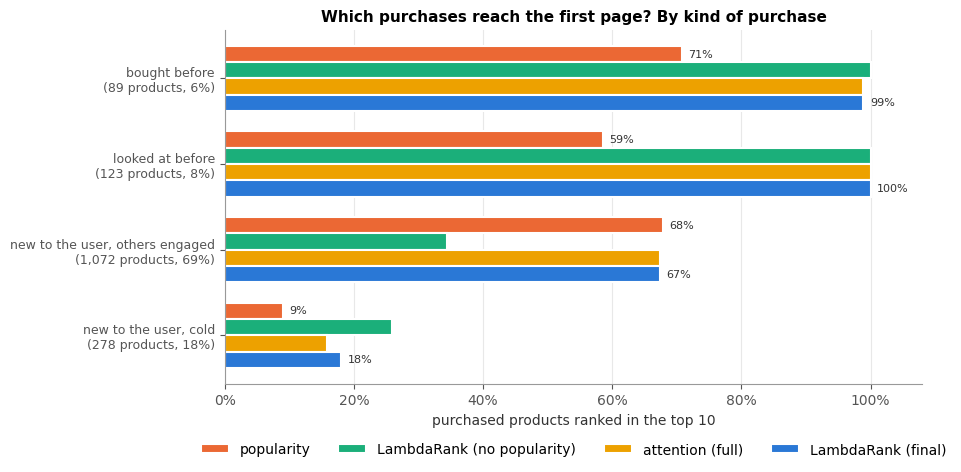

In [ ]:
# every purchased test product: what kind of purchase is it?
assert (X['wid'].to_numpy() == P['wid'].to_numpy()).all() and (E['wid'].to_numpy() == P['wid'].to_numpy()).all()
buy = (P['label'] == 3).to_numpy()
seen = E['prod_seen_before'].to_numpy()[buy] == 1
ordered = X['hc__prod_n_order'].fillna(0).to_numpy()[buy] > 0
cold_b = E['cold'].to_numpy()[buy]
KINDS = ['bought before', 'looked at before', 'new to the user, others engaged', 'new to the user, cold']
B = pd.DataFrame({'session_id': P['session_id'].to_numpy()[buy],
                  'kind': pd.Categorical(np.select([seen & ordered, seen, ~cold_b], KINDS[:3], KINDS[3]),
                                         KINDS, ordered=True)})
for m in RANK_MODELS:
    B[m] = R[m].to_numpy()[buy] <= 10                    # purchased product on the first page?
print(f'{len(B):,} purchased products in {B["session_id"].nunique():,} purchase searches\n')

rng6 = np.random.default_rng(SEED)
rows = []
for kind in KINDS + ['all purchased products']:
    b = B if kind == 'all purchased products' else B[B['kind'] == kind]
    r = {'kind': kind, 'products': len(b), 'share': len(b) / len(B)}
    r.update({MODEL_NAMES[m]: b[m].mean() for m in RANK_MODELS})
    d = b['lr'].astype(float) - b['popularity'].astype(float)
    if len(b) >= MIN_SEG:
        lo, hi = ci_mean(d, rng6)
        r['LambdaRank − popularity'] = f'{100 * d.mean():+.1f} pts [{100 * lo:+.1f}, {100 * hi:+.1f}]'
    else:
        r['LambdaRank − popularity'] = f'{100 * d.mean():+.1f} pts (n < {MIN_SEG})'
    rows.append(r)
BUY_KIND = pd.DataFrame(rows).set_index('kind')
pct = {c: '{:.1%}'.format for c in ['share'] + [MODEL_NAMES[m] for m in RANK_MODELS]}
print('Purchased products ranked in the top 10, by kind of purchase')
print(BUY_KIND.to_string(formatters=pct))

# the same difference in business terms (search level, 5 tie-breaking draws, Section 1)
print('\nPurchase searches with the purchased product in the top 10 (Section 1, mean of 5 tie-breaking draws)')
for m in ['random', 'popularity', 'att', 'lr']:
    print(f'   {MODEL_NAMES[m]:20s} {summary[(m, "hit_purchase")][0]:.1%}')
for ref in ['popularity', 'att', 'random']:
    mean, lo, hi = paired('lr', ref, 'hit_purchase')
    print(f'LambdaRank − {MODEL_NAMES[ref]:12s}: {1000 * mean:+.0f} purchases on the first page per 1,000 purchase searches '
          f'[{1000 * lo:+.0f}, {1000 * hi:+.0f}]')

fig_models = ['popularity', 'lr_no_pop', 'att', 'lr']
fig, ax = plt.subplots(figsize=(9, 4.6))
h = 0.19
y0 = np.arange(len(KINDS))
for k, m in enumerate(fig_models):
    v = BUY_KIND.loc[KINDS, MODEL_NAMES[m]].to_numpy()
    yy = y0 + (k - 1.5) * h
    ax.barh(yy, v, height=h, color=SEG_STYLE[m]['color'], edgecolor='white', linewidth=1.5, label=MODEL_NAMES[m])
    if m in ('popularity', 'lr'):
        for y_, v_ in zip(yy, v):
            ax.text(v_ + 0.01, y_, f'{v_:.0%}', va='center', fontsize=8, color=COL['ink'])
ax.set_yticks(y0, [f'{k}\n({n:,} products, {s:.0%})' for k, n, s in
                   zip(KINDS, BUY_KIND.loc[KINDS, 'products'], BUY_KIND.loc[KINDS, 'share'])], fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 1.08)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_xlabel('purchased products ranked in the top 10')
ax.set_title('Which purchases reach the first page? By kind of purchase')
ax.grid(axis='y', visible=False)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=4)
fig.savefig(FIG / '6_purchases_first_page.png')
plt.show()


**Finding (6.1). LambdaRank's extra purchases come almost entirely from products the user already knew.**
- **Overall:** LambdaRank puts the purchased product on the first page in 63.8% of purchase searches against 57.0% for popularity: **+69 purchases on the first page per 1,000 purchase searches [+50, +88]**. Against attention the difference is +5 [−9, +18], so the two models are equal on purchases.
- **By kind of purchase** (1,562 purchased products in 1,523 purchase searches; top-10 rate for LambdaRank vs popularity):

  | kind of purchase | share of purchases | LambdaRank | popularity | difference |
  |---|---|---|---|---|
  | bought before ("buy again") | 5.7% | 98.9% | 70.8% | +28.1 pts [+19.1, +37.1] |
  | looked at before, not bought | 7.9% | 100.0% | 58.5% | +41.5 pts [+33.3, +49.6] |
  | new to the user, others engaged | 68.6% | 67.4% | 67.8% | −0.5 pts [−2.4, +1.4] |
  | new to the user, cold | 17.8% | 18.0% | 9.0% | +9.0 pts [+4.3, +13.7] |

- **Repeat purchases are solved.** For the 13.6% of purchases where the user had already looked at or bought the product, LambdaRank reaches the first page 99–100% of the time. Weighting by purchases, these 13.6% account for **about 80% of LambdaRank's extra first-page purchases** over popularity (89 × 28.1 + 123 × 41.5 of the 1,562 × 6.1 point total). "Looked at before" contributes twice as much as "bought before": the model mostly helps users come back to a product they were considering, not reorder one.
- **For the largest group, products new to the user but known to others (69% of purchases), LambdaRank is no better than popularity** (67.4% vs 67.8%). Here the final model *is* popularity: without popularity it reaches only 34.4%.
- **New products are the weak spot.** A purchased cold product reaches the first page 18.0% of the time, barely above random order (13.7%) and below LambdaRank without popularity (25.9%), consistent with 2.3.


### 6.2 Who gets the first-page slots?
| Kind of product | Definition |
|---|---|
| **cold product** | no training user ever acted on it (2.1) |
| **little-known product** | 1–9 training users acted on it |
| **shop in the least-active quarter** | the shop's clicks, carts and orders by training users (step 3b's shop popularity features) are in the bottom 25% of test candidates with a known shop |
| **product the user touched before** | a repeat product: in the user's own history |

It answers two questions:
1. **Slots.** What share of top-10 slots does each kind get under each model? For reference: its share among all candidates, which equals its share of slots under random order (what the search engine retrieved), and its share among engaged and purchased products (what users chose).
2. **Reach.** Of the engaged products of each kind, what share does each model put in the top 10, against the same share for all *other* engaged products? This is the fair comparison: it asks whether a product **the user actually wanted** has a lower chance of reaching the first page because of its kind. (In fairness terms this is *equal opportunity*: equal true-positive rates across groups.) The gap is then turned into engaged products per 1,000 searches that miss the first page because they reach it less often than other engaged products.

**Using slots alone are not enough.** A search has about 1.9 engaged products, so roughly 8 of the 10 slots go to products the user ignored, whichever model ranks them. A slot share therefore mixes "does the model find what users want" with "what does it fill the rest of the page with". The reach rate isolates the first.

First-page slots are what sellers compete for. Section 2.3 found popularity hurts cold products and 3.4 found failed searches are filled with more popular substitutes. If a wanted cold product, or one from a small shop, reaches the first page less often than other wanted products, new products and new sellers struggle to be discovered: they get few slots, so they collect few clicks, so they stay "unpopular". This is the **popularity feedback loop**, a known risk of popularity-based ranking.

least-active quarter of shops: at most 10 training actions on the shop
top-10 slots per model: 127,353 (lists shorter than 10 contribute every product); engaged products: 23,929

1. Share of each kind among candidates, engaged and purchased products, and among top-10 slots
kind                               cold product little-known product (1–9 users) shop in the least-active quarter product the user touched before
all candidates                            67.2%                            24.0%                            24.8%                            0.8%
engaged products                          38.0%                            31.9%                            13.7%                            9.3%
purchased products                        19.7%                            34.1%                             6.5%                           13.6%
top 10: random                            67.3%                            23.6%                            24.9%                            0

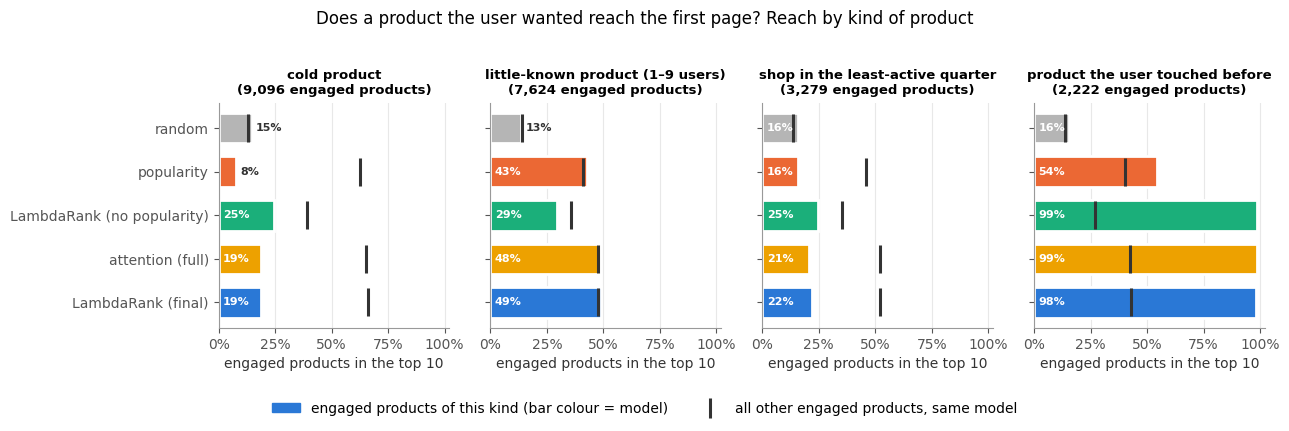

In [ ]:
# shop activity: training users' clicks, carts and orders on the shop (step 3b's features) 
shop_act = X[['pop__pop_shop_click', 'pop__pop_shop_cart', 'pop__pop_shop_ord']].fillna(0).sum(axis=1).to_numpy()
has_shop = E['shop'].to_numpy() != -1
shop_thr = np.quantile(shop_act[has_shop], 0.25)
print(f'least-active quarter of shops: at most {shop_thr:,.0f} training actions on the shop')

KIND_MASK = {
    'cold product': E['cold'].to_numpy(),
    'little-known product (1–9 users)': ((E['n_train'] >= 1) & (E['n_train'] <= 9)).to_numpy(),
    'shop in the least-active quarter': has_shop & (shop_act <= shop_thr),
    'product the user touched before': (E['prod_seen_before'] == 1).to_numpy(),
}
REACH_MODELS = ['random', 'popularity', 'lr_no_pop', 'att', 'lr']
TOP = {m: R[m].to_numpy() <= 10 for m in REACH_MODELS}
lab = P['label'].to_numpy()
eng_m = lab > 0
print(f'top-10 slots per model: {TOP["random"].sum():,} (lists shorter than 10 contribute every product); '
      f'engaged products: {eng_m.sum():,}\n')

# 1. share of top-10 slots 
rows = []
for kind, msk in KIND_MASK.items():
    r = {'kind': kind, 'all candidates': msk.mean(), 'engaged products': msk[eng_m].mean(),
         'purchased products': msk[lab == 3].mean()}
    r.update({f'top 10: {MODEL_NAMES[m]}': msk[TOP[m]].mean() for m in REACH_MODELS})
    rows.append(r)
SLOTS = pd.DataFrame(rows).set_index('kind')
print('1. Share of each kind among candidates, engaged and purchased products, and among top-10 slots')
print(SLOTS.map('{:.1%}'.format).T.to_string())

# 2. reach: share of engaged products of each kind ranked in the top 10
rng62 = np.random.default_rng(SEED)
rows = []
for kind, msk in KIND_MASK.items():
    for grp, sel in [('this kind', eng_m & msk), ('other engaged products', eng_m & ~msk)]:
        r = {'kind': kind, 'engaged products of': grp, 'n': int(sel.sum())}
        r.update({MODEL_NAMES[m]: TOP[m][sel].mean() for m in REACH_MODELS})
        lo, hi = ci_mean(TOP['lr'][sel], rng62)
        r['LambdaRank 95% interval'] = f'[{lo:.1%}, {hi:.1%}]'
        rows.append(r)
REACH = pd.DataFrame(rows).set_index(['kind', 'engaged products of'])
print('\n2. Reach: share of engaged products ranked in the top 10')
print(REACH.to_string(formatters={MODEL_NAMES[m]: '{:.1%}'.format for m in REACH_MODELS}))

print('\nEngaged products per 1,000 searches that miss the first page because their kind reaches it less often '
      'than other engaged products (LambdaRank; negative = reaches it more often)')
for kind, msk in KIND_MASK.items():
    gap = REACH.loc[(kind, 'other engaged products'), MODEL_NAMES['lr']] - REACH.loc[(kind, 'this kind'), MODEL_NAMES['lr']]
    print(f'   {kind:34s} {gap * (eng_m & msk).sum() / len(S) * 1000:+6.0f}   (reach gap {100 * gap:+.1f} pts)')

fig, axes = plt.subplots(1, len(KIND_MASK), figsize=(13, 3.8), sharey=True, sharex=True)
for ax, kind in zip(axes, KIND_MASK):
    v = [REACH.loc[(kind, 'this kind'), MODEL_NAMES[m]] for m in REACH_MODELS]
    o = [REACH.loc[(kind, 'other engaged products'), MODEL_NAMES[m]] for m in REACH_MODELS]
    ys = np.arange(len(REACH_MODELS))
    ax.barh(ys, v, color=[SEG_STYLE[m]['color'] for m in REACH_MODELS], edgecolor='white', linewidth=2, height=0.7)
    ax.scatter(o, ys, marker='|', s=420, linewidths=2.2, color=COL['ink'], zorder=3)
    for y_, v_ in zip(ys, v):
        inside = v_ >= 0.15
        ax.text(0.02 if inside else v_ + 0.02, y_, f'{v_:.0%}', va='center', fontsize=8,
                color='white' if inside else COL['ink'], fontweight='bold')
    n = REACH.loc[(kind, 'this kind'), 'n']
    ax.set_title(f'{kind}\n({n:,} engaged products)', fontsize=9.5)
    ax.set_xlim(0, 1.02)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
    ax.set_xlabel('engaged products in the top 10')
    ax.grid(axis='y', visible=False)
axes[0].set_yticks(range(len(REACH_MODELS)), [MODEL_NAMES[m] for m in REACH_MODELS])
axes[0].invert_yaxis()
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
fig.legend([Patch(color=COL['blue']), Line2D([], [], color=COL['ink'], marker='|', ls='', ms=14, mew=2.2)],
           ['engaged products of this kind (bar colour = model)', 'all other engaged products, same model'],
           loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.07))
fig.suptitle('Does a product the user wanted reach the first page? Reach by kind of product', y=1.03)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(FIG / '6_first_page_reach.png')
plt.show()


**Finding (6.2). A product the user wants is far less likely to reach the first page if it is new or comes from a small shop.**
- LambdaRank gives **cold products 18.1% of top-10 slots** although they are 67.2% of candidates and 38.0% of engaged products, and **products from the least-active quarter of shops** (at most 10 training actions on the shop) **7.2%**, against 24.8% of candidates and 13.7% of engaged products. Popularity alone gives 14.5% and 9.3%; attention is the same as LambdaRank (19.3% and 7.4%).
- **Reach** (share of engaged products ranked in the top 10, LambdaRank; 23,929 engaged products):

  | engaged products that are… | reach | all other engaged products | per 1,000 searches, wanted products that miss page one because of the gap |
  |---|---|---|---|
  | cold (9,096) | **18.6%** [17.8, 19.4] | 66.1% | **335** |
  | from a least-active shop (3,279) | **21.9%** [20.4, 23.2] | 52.2% | **77** |
  | little-known, 1–9 users (7,624) | 49.1% | 47.5% | none (−9) |
  | touched before by the user (2,222) | 98.3% | 42.9% | reaches it more often (−96) |

- **Reach rises steeply with popularity.** From the table, wanted products with 10+ training users reach the first page **about 84%** of the time (7,209 products), against 49% with 1–9 users and 19% with none. A wanted product with no data is about 4.5 times less likely to be shown on the first page than a wanted popular one. Under random order the four kinds reach it equally often (13–16%), so the gap is created by the ranking, not by the retrieved lists.
- **Small shops are partly the same story.** A shop with at most 10 training actions has few products anyone acted on, so its products are likely to be cold as well and the two gaps overlap; this notebook does not separate them.
- **Which model is fairest to new products?** LambdaRank without popularity reaches 24.7% of wanted cold products, the most of any model, but at the cost of 0.13 NDCG@10 overall (Section 1). Popularity alone reaches 7.8%, **below random order (14.6%)**: it actively buries new products.
- **Implication.** This is the popularity feedback loop in numbers: about 335 wanted products per 1,000 searches miss the first page because nobody has engaged with them yet, so they never collect the engagement that would lift them. A ranking change should be judged on reach for cold products and small shops as well as on NDCG (guardrail metrics in an A/B test).



### 6.3 Which customers benefit?
We look at these 2 aspects
- **gain over popularity** in NDCG@10 (from 2.3) and the **share of the total gain** the level accounts for (searches × gain ÷ total), which shows where the model's value goes;
- **purchase searches** in the level and the share whose purchased product is in the top 10 under LambdaRank and under popularity, with the difference and its 95% interval (bootstrap over purchase searches; levels with fewer than 30 purchase searches are listed without an interval).

Reason being that a ranking model that only helps heavy users would widen the gap between loyal and new customers; one that helps everyone is an easier business case. Section 2 already showed user segments matter much less than product segments; this step puts that in customer terms and adds purchases.

In [29]:
total_gain = (nd['lr'] - nd['popularity']).sum()
hit = W['hit_purchase'].reindex(S.index)                       # NaN for searches without a purchase
is_buy = hit['lr'].notna()
rng63 = np.random.default_rng(SEED)
rows = []
for c in SEGMENTS['user']:
    for level in S[c].cat.categories:
        mask = (S[c] == level).to_numpy()
        if mask.sum() < MIN_SEG:
            continue
        g = GAIN[(GAIN['segment'] == c) & (GAIN['level'] == level)].iloc[0]
        r = {'segment': c, 'level': level, 'searches': f'{mask.sum():,} ({mask.mean():.0%})',
             'gain over popularity': f'{g["vs_pop"]:+.3f}',
             'share of total gain': f'{mask.sum() * g["vs_pop"] / total_gain:.0%}'}
        bm = mask & is_buy.to_numpy()
        d = (hit['lr'] - hit['popularity'])[bm].to_numpy()
        r['purchase searches'] = int(bm.sum())
        r['purchase in top 10: LambdaRank'] = f'{hit["lr"][bm].mean():.1%}'
        r['popularity'] = f'{hit["popularity"][bm].mean():.1%}'
        if bm.sum() >= MIN_SEG:
            lo, hi = ci_mean(d, rng63)
            r['difference'] = f'{100 * d.mean():+.1f} pts [{100 * lo:+.1f}, {100 * hi:+.1f}]'
        else:
            r['difference'] = f'{100 * d.mean():+.1f} pts (n < {MIN_SEG})'
        rows.append(r)
CUSTOMERS = pd.DataFrame(rows).set_index(['segment', 'level'])
print(f'Total gain of LambdaRank over popularity: {total_gain / len(nd):+.3f} NDCG@10 per search\n')
print(CUSTOMERS.to_string())


Total gain of LambdaRank over popularity: +0.077 NDCG@10 per search

                                           searches gain over popularity share of total gain  purchase searches purchase in top 10: LambdaRank popularity               difference
segment        level                                                                                                                                                              
history length 1–9                      1,231 (10%)               +0.064                  8%                123                          62.6%      60.3%    +2.3 pts [-2.4, +7.0]
               10–49                    3,630 (28%)               +0.069                 25%                401                          59.1%      52.8%    +6.2 pts [+3.1, +9.5]
               50–199                   4,996 (39%)               +0.077                 39%                605                          65.1%      58.0%   +7.1 pts [+4.1, +10.0]
               200+                 

**Finding (6.3). The model's value goes to customers in the middle of a visit; new customers get little more than the popularity ranking.**
- **Continuing a visit is the main divide.** The 41% of searches that continue a visit receive **63% of LambdaRank's total gain** over popularity (+0.117 vs +0.048 NDCG@10 for new visits). For purchases the gap is wider: the purchased product reaches the first page **+12.6 pts [+9.2, +16.2] more often than with popularity** in continuing visits, against +3.3 pts [+1.2, +5.4] in new visits. This follows from 6.1: mid-visit users are the ones whose purchase is a product they just looked at.
- **The gain grows with history.** Users with 200+ past actions get +0.092 (28% of the gain from 23% of searches); users with 1–9 actions get +0.064, and for their purchases there is **no measurable gain** over popularity (+2.3 pts [−2.4, +7.0], 123 purchase searches). Users with no click in the last 7 days get about half the average gain (+0.045).
- **Loyal buyers do not benefit more than occasional ones.** The gain is flat across past checkouts (+0.074 to +0.086), and every level's purchase difference overlaps the others.
- **No customer group is worse off than with popularity:** every level's NDCG gain is positive (2.3), and no purchase difference is significantly negative. New and inactive customers effectively get the popularity ranking with small improvements.


### 6.4 What these results cannot tell JD
These are offline results on logged data. Five limits decide how far the business statements in 6.1–6.3 can go:
1. **No revenue.** The dataset has no prices or quantities, so neither NDCG nor "purchase on the first page" can be turned into GMV. A purchase of a cheap accessory counts the same as a purchase of a phone. Measuring GMV per search would need price data joined to the catalogue.
2. **Not a conversion rate.** Every test search has at least one engaged product (0.3: zero searches without one), because the dataset's authors kept only searches with an interaction (interim report, 1c). The metrics measure *which product an engaged user picks*, not *whether a search converts*. Better ranking might also rescue searches that currently end with nothing; that effect cannot be seen here.
3. **No comparison with JD's own ranking.** The stored list order puts engaged products first (interim report, 1b), so JD's real display order is lost. All gains are against popularity and random order, not against the ranker JD runs today.
4. **The labels were produced under JD's ranking.** Users could only engage with products JD showed them high enough to notice. Products JD buried had less chance of being engaged, so offline results tend to understate gains for products JD placed low and overstate them for products JD already placed high. Cold products are likely in the first group, so 6.2's under-exposure may partly reflect what JD already showed. Only an online A/B test can measure the real effect.
5. **One ordinary day, a sample.** 12,880 test searches from 17 Oct 2022. The intervals cover sampling noise, not seasonality: behaviour around sales events such as JD's 11.11 may differ. Section 5.1 showed the popularity counts would work with a nightly update, so the timing of the data is not a limit.


**What the diagnostics mean for JD.**
1. **The model's measurable value is "find it again".** LambdaRank puts **69 more purchases on the first page per 1,000 purchase searches** than popularity [+50, +88]. About **80%** of that comes from the 13.6% of purchases where the user had already looked at or bought the product, which LambdaRank ranks in the top 10 98–100% of the time (6.1), and **63% of the NDCG gain goes to searches that continue a visit** (6.3). *Business use:* this is a reliable, cheap signal; a "recently viewed / buy again" feature in search captures most of the model's gain.
2. **For products new to the user (86% of purchases), the model adds little beyond popularity.** For products others engaged with it matches popularity exactly (67.4% vs 67.8% in the top 10); for cold ones it reaches 18%. Failures are mostly "right category, more popular substitute" (3.4). *Next step:* information that tells similar products apart (price, attributes, product text), not more history features.
3. **New products and small sellers are under-exposed.** A product the user wanted reaches the first page **19% of the time if it is cold** and **22% if it comes from a least-active shop**, against 66% and 52% for other wanted products; about **335 and 77 wanted products per 1,000 searches** miss page one because of it (6.2). Popularity alone does worse than random order on cold products. *Business risk:* a popularity feedback loop that slows new launches and new sellers. *Action:* treat "no data" differently from "unpopular" (2.3), reserve some exploration slots for new products, and track reach by product kind as a guardrail in any A/B test.
4. **Customers: no one is worse off, but new and inactive customers effectively get the popularity ranking.** Users with 1–9 past actions show no measurable purchase gain (+2.3 pts [−2.4, +7.0]); loyal buyers gain no more than occasional ones (6.3).
5. **LambdaRank and attention are equal for the business.** Same purchases on the first page (+5 per 1,000 [−9, +18]), same exposure of cold products and small shops (6.2), and 0.007 NDCG@10 apart (Section 1). The simpler, faster model is enough.
6. **How far these claims go** (6.4): ranking quality among engaged searches, not revenue or conversion, measured offline against popularity, not against JD's live ranker. An online A/B test with GMV, conversion and reach by product kind would be needed to confirm them.
